# LLM-generated synthetic personas in chronic pain — statistical analyses

Cells follow the order in which tables and figures are cited in the manuscript.

| Section | Outputs |
|---|---|
| 1. Data import and verification | — |
| 2. Real population (RP) | Table 1, Appendix A, Supplementary Tables 1–6, Supplementary Figure 1, regression diagnostics (Appendix C.1.4) |
| 3. Structural fidelity (RQ1) | Supplementary Table 7, Supplementary Figure 2 |
| 4. Univariate distributional fidelity (RQ1) | Figure 2, Table 3, Supplementary Tables 8–9 |
| 5. Individual-level correspondence (RQ2) | Table 4, Supplementary Tables 10–11, Supplementary Figures 3–4, Table 5, Figure 3, Supplementary Table 12, Supplementary Figure 5 |

Tables are saved to `results/tables/` and figures to `results/figures/`. Run with *Restart & Run All*.

## 0. Setup

In [1]:
# ============================================================================
# SETUP — imports, paths, seeds, figure style and shared formatting helpers
# ============================================================================

# Standard library
from pathlib import Path
import random
import re
import unicodedata
import warnings

# Data
import numpy as np
import pandas as pd
from IPython.display import display

# Statistics
import pingouin as pg
from patsy import dmatrices
from scipy import stats
from scipy.stats import rankdata, wilcoxon
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import OLSInfluence
from statsmodels.stats.stattools import jarque_bera   # returns (JB, p, skew, kurtosis)

# Machine learning utilities
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold

# Visualization
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

warnings.filterwarnings("ignore")

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ── Paths ────────────────────────────────────────────────────────────────────
NOTEBOOK_DIR = Path().resolve()
CLEAN_DIR = NOTEBOOK_DIR / "clean"
FIG_DIR = Path("results/figures")
OUT_DIR = Path("results/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Figure style (single definition for all matplotlib figures) ──────────────
plt.rcParams.update({"font.family": "sans-serif",
                     "font.sans-serif": ["Arial", "DejaVu Sans"],
                     "pdf.fonttype": 42})
FS_PANEL, FS_TITLE, FS_LABEL, FS_TICK, FS_LEGEND = 13, 13, 12, 11, 11

def save_figure(fig, name, dpi=300):
    """Save a matplotlib figure as PNG (300 dpi) and vector PDF for submission."""
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=dpi, bbox_inches="tight", facecolor="white")
    print(f"✓ Saved: {FIG_DIR / name}.png / .pdf")

# ── Models ───────────────────────────────────────────────────────────────────
ID_COL = "id"
MODEL_KEYS = {"GPT": "gpt", "DeepSeek": "deepseek", "Llama": "llama"}
MODEL_ORDER = list(MODEL_KEYS)
ABBR = {"GPT": "GPT", "DeepSeek": "DS", "Llama": "Llama"}

# ── Shared formatting helpers ────────────────────────────────────────────────
EM_DASH = "\u2014"
MINUS = "\u2212"


def fmt_num(x, d=2):
    """Fixed decimals with a typographic minus sign (avoids '-0.00')."""
    x = 0.0 if round(x, d) == 0 else x
    return f"{x:.{d}f}".replace("-", MINUS)


def fmt_r2(x, d=2):
    """Two decimals, typographic minus, no '-0.00', em dash for missing."""
    return EM_DASH if pd.isna(x) else fmt_num(x, d)


def fmt_p_table(p):
    """'< 0.001'; three decimals below .01 or near .05 (avoids .048 -> 0.05); else two."""
    if p < 0.001:
        return "< 0.001"
    if p < 0.01 or 0.045 <= p < 0.055:
        return f"{p:.3f}"
    return f"{p:.2f}"


def export_table(df, title, csv_name):
    """Display, save as CSV, and print tab-separated text for pasting into Word."""
    print("\n" + "=" * 90 + f"\n{title}\n" + "=" * 90)
    display(df)
    df.to_csv(OUT_DIR / csv_name, encoding="utf-8-sig")
    print(df.to_csv(sep="\t"))


## 1. Data import and verification

In [2]:
# ============================================================================
# DATA IMPORT — real population (RP) and 24 synthetic persona (SP) datasets
# ============================================================================
# ── Load real participants dataset ────────────────────────────────────────────
rp = pd.read_csv(CLEAN_DIR / "rp.csv")

# ── Load synthetic datasets ───────────────────────────────────────────────────
gpt_step1       = pd.read_csv(CLEAN_DIR / "gpt_step1.csv")
deepseek_step1  = pd.read_csv(CLEAN_DIR / "deepseek_step1.csv")
llama_step1     = pd.read_csv(CLEAN_DIR / "llama_step1.csv")

gpt_step2       = pd.read_csv(CLEAN_DIR / "gpt_step2.csv")
deepseek_step2  = pd.read_csv(CLEAN_DIR / "deepseek_step2.csv")
llama_step2     = pd.read_csv(CLEAN_DIR / "llama_step2.csv")

gpt_step3       = pd.read_csv(CLEAN_DIR / "gpt_step3.csv")
deepseek_step3  = pd.read_csv(CLEAN_DIR / "deepseek_step3.csv")
llama_step3     = pd.read_csv(CLEAN_DIR / "llama_step3.csv")

gpt_step4       = pd.read_csv(CLEAN_DIR / "gpt_step4.csv")
deepseek_step4  = pd.read_csv(CLEAN_DIR / "deepseek_step4.csv")
llama_step4     = pd.read_csv(CLEAN_DIR / "llama_step4.csv")

gpt_step5       = pd.read_csv(CLEAN_DIR / "gpt_step5.csv")
deepseek_step5  = pd.read_csv(CLEAN_DIR / "deepseek_step5.csv")
llama_step5     = pd.read_csv(CLEAN_DIR / "llama_step5.csv")

gpt_step6       = pd.read_csv(CLEAN_DIR / "gpt_step6.csv")
deepseek_step6  = pd.read_csv(CLEAN_DIR / "deepseek_step6.csv")
llama_step6     = pd.read_csv(CLEAN_DIR / "llama_step6.csv")

gpt_step7       = pd.read_csv(CLEAN_DIR / "gpt_step7.csv")
deepseek_step7  = pd.read_csv(CLEAN_DIR / "deepseek_step7.csv")
llama_step7     = pd.read_csv(CLEAN_DIR / "llama_step7.csv")

gpt_step8       = pd.read_csv(CLEAN_DIR / "gpt_step8.csv")
deepseek_step8  = pd.read_csv(CLEAN_DIR / "deepseek_step8.csv")
llama_step8     = pd.read_csv(CLEAN_DIR / "llama_step8.csv")

# ── Dataset registry ──────────────────────────────────────────────────────────
ALL_DATASETS = {
    "rp":              rp,
    "gpt_step1":       gpt_step1,  "deepseek_step1": deepseek_step1, "llama_step1": llama_step1,
    "gpt_step2":       gpt_step2,  "deepseek_step2": deepseek_step2, "llama_step2": llama_step2,
    "gpt_step3":       gpt_step3,  "deepseek_step3": deepseek_step3, "llama_step3": llama_step3,
    "gpt_step4":       gpt_step4,  "deepseek_step4": deepseek_step4, "llama_step4": llama_step4,
    "gpt_step5":       gpt_step5,  "deepseek_step5": deepseek_step5, "llama_step5": llama_step5,
    "gpt_step6":       gpt_step6,  "deepseek_step6": deepseek_step6, "llama_step6": llama_step6,
    "gpt_step7":       gpt_step7,  "deepseek_step7": deepseek_step7, "llama_step7": llama_step7,
    "gpt_step8":       gpt_step8,  "deepseek_step8": deepseek_step8, "llama_step8": llama_step8,
}


# ============================================================================
# FEATURE ENGINEERING — BPI mean scores
# ============================================================================
BPI_INTERF_COLS = ["bpi_1", "bpi_2", "bpi_3", "bpi_4", "bpi_5", "bpi_6", "bpi_7"]
BPI_INT_COLS    = ["bpi_8", "bpi_9", "bpi_10", "bpi_11"]
BPI_ALL_COLS    = BPI_INTERF_COLS + BPI_INT_COLS

for name, df in ALL_DATASETS.items():
    df["bpi_interf_mean"] = df[BPI_INTERF_COLS].mean(axis=1, skipna=False)
    df["bpi_int_mean"]    = df[BPI_INT_COLS].mean(axis=1, skipna=False)
    df["bpi_mean"]        = df[BPI_ALL_COLS].mean(axis=1, skipna=False)

# ============================================================================
# OUTPUT 1 — Shape summary (rows × columns per dataset)
# ============================================================================
print("=" * 55)
print("OUTPUT 1 — Dataset shapes")
print("=" * 55)
print(f"{'Dataset':<20} {'Rows':>6} {'Cols':>6}")
print("-" * 55)
for name, df in ALL_DATASETS.items():
    print(f"  {name:<18} {df.shape[0]:>6} {df.shape[1]:>6}")

# ============================================================================
# OUTPUT 2 — Column consistency across synthetic datasets
#            All synthetic datasets must share the same columns as rp
# ============================================================================
print("\n" + "=" * 55)
print("OUTPUT 2 — Column consistency vs. RP")
print("=" * 55)

rp_cols = set(rp.columns)
all_consistent = True

for name, df in ALL_DATASETS.items():
    if name == "rp":
        continue
    extra   = set(df.columns) - rp_cols
    missing = rp_cols - set(df.columns)
    if extra or missing:
        all_consistent = False
        if missing: print(f"  ✗ {name:<18} MISSING: {sorted(missing)}")
        if extra:   print(f"  ✗ {name:<18} EXTRA:   {sorted(extra)}")
    else:
        print(f"  ✓ {name:<18} columns match RP ({df.shape[1]} cols)")

if all_consistent:
    print(f"\n  ✓ All synthetic datasets share the same {len(rp_cols)} columns as RP")

# ============================================================================
# OUTPUT 3 — Key variable completeness (no unexpected NaNs)
# ============================================================================
KEY_COLS = [
    "edad", "genero", "causa_dolor",
    "bpi_interf_sum", "bpi_int_sum", "bpi_sum",
    "bpi_interf_mean", "bpi_int_mean", "bpi_mean",
    "dass_total_interp", "mirswb_total"
]

print("\n" + "=" * 55)
print("OUTPUT 3 — Key variable completeness (% non-null)")
print("=" * 55)
print(f"{'Dataset':<20}", end="")
for col in KEY_COLS:
    print(f"  {col[:13]:>13}", end="")
print()
print("-" * 75)

for name, df in ALL_DATASETS.items():
    print(f"  {name:<18}", end="")
    for col in KEY_COLS:
        if col in df.columns:
            pct = df[col].notna().mean() * 100
            flag = "✓" if pct == 100 else f"{pct:.0f}%"
        else:
            flag = "N/A"
        print(f"  {flag:>13}", end="")
    print()

print("\n✓ Import complete — datasets ready for analysis.")

# ============================================================================
# OUTPUT 4 — MIRSWB item-level completeness
# ============================================================================
MIRSWB_ITEM_COLS = [f"mirswb_{i}" for i in range(1, 19)]


print("\n" + "=" * 70)
print("OUTPUT 4 — Rows with all 18 MIRSWB items missing")
print("=" * 70)
print(f"{'Dataset':<20} {'n_rows_all_18_nan':>18} {'IDs (id)':>30}")
print("-" * 70)


for name, df in ALL_DATASETS.items():
    available_cols = [c for c in MIRSWB_ITEM_COLS if c in df.columns]
    
    if len(available_cols) < 18:
        # No tenemos los 18 ítems en este dataset
        print(f"  {name:<18} {'N/A (only ' + str(len(available_cols)) + ' MIRSWB items)':>18} {'':>30}")
        continue
    
    # Count missing per row
    n_missing = df[available_cols].isna().sum(axis=1)
    
    # Flag rows where all 18 are missing
    mask_all_nan = (n_missing == 18)
    n_all_nan = int(mask_all_nan.sum())
    
    if n_all_nan == 0:
        print(f"  {name:<18} {n_all_nan:>18} {'':>30}")
    else:
        # Get the IDs of the rows where all 18 items are missing
        ids_all_nan = df.loc[mask_all_nan, "id"].astype(str).tolist()
        ids_str = ", ".join(ids_all_nan[:10])
        if len(ids_all_nan) > 10:
            ids_str += f" (+{len(ids_all_nan) - 10} more)"
        
        print(f"  {name:<18} {n_all_nan:>18} {ids_str:>30}")


# ============================================================================
# OUTPUT 5 — MIRSWB item-level completeness (% non-null per item)
# ============================================================================
print("\n" + "=" * 70)
print("OUTPUT 5 — MIRSWB item completeness (% non-null per item)")
print("=" * 70)


header = f"{'Dataset':<18}"
for i in range(1, 19):
    header += f"  m{i:>2}"
print(header)
print("-" * 70)


for name, df in ALL_DATASETS.items():
    available_cols = [c for c in MIRSWB_ITEM_COLS if c in df.columns]
    
    if len(available_cols) < 18:
        print(f"  {name:<18} (only {len(available_cols)} MIRSWB items available)")
        continue
    
    row_parts = [f"  {name:<18}"]
    for i in range(1, 19):
        col = f"mirswb_{i}"
        if col not in df.columns:
            row_parts.append(f"  {'NA':>3}")
            continue
        pct = df[col].notna().mean() * 100
        if pct == 100:
            row_parts.append(f"  {'✓':>3}")
        else:
            row_parts.append(f"  {pct:>3.0f}%")
    
    print("".join(row_parts))


# ============================================================================
# OUTPUT 6 — Optional: BPI and DASS item-level completeness
# ============================================================================
BPI_ITEM_COLS = [f"bpi_{i}" for i in range(1, 12)]
DASS_ITEM_COLS = [f"dass_{i}" for i in range(1, 22)]


print("\n" + "=" * 70)
print("OUTPUT 6 — Rows with all BPI or all DASS items missing")
print("=" * 70)
print(f"{'Dataset':<20} {'n_all_bpi_nan':>15} {'n_all_dass_nan':>16}")
print("-" * 70)


for name, df in ALL_DATASETS.items():
    bpi_avail = [c for c in BPI_ITEM_COLS if c in df.columns]
    dass_avail = [c for c in DASS_ITEM_COLS if c in df.columns]
    
    if len(bpi_avail) == 11:
        n_all_bpi_nan = int((df[bpi_avail].isna().sum(axis=1) == 11).sum())
    else:
        n_all_bpi_nan = None
    
    if len(dass_avail) == 21:
        n_all_dass_nan = int((df[dass_avail].isna().sum(axis=1) == 21).sum())
    else:
        n_all_dass_nan = None
    
    bpi_str = str(n_all_bpi_nan) if n_all_bpi_nan is not None else "N/A"
    dass_str = str(n_all_dass_nan) if n_all_dass_nan is not None else "N/A"
    
    print(f"  {name:<18} {bpi_str:>15} {dass_str:>16}")

OUTPUT 1 — Dataset shapes
Dataset                Rows   Cols
-------------------------------------------------------
  rp                    235     80
  gpt_step1             235     80
  deepseek_step1        235     80
  llama_step1           235     80
  gpt_step2             235     80
  deepseek_step2        235     80
  llama_step2           235     80
  gpt_step3             235     80
  deepseek_step3        235     80
  llama_step3           235     80
  gpt_step4             235     80
  deepseek_step4        235     80
  llama_step4           235     80
  gpt_step5             235     80
  deepseek_step5        235     80
  llama_step5           235     80
  gpt_step6             235     80
  deepseek_step6        235     80
  llama_step6           235     80
  gpt_step7             235     80
  deepseek_step7        235     80
  llama_step7           235     80
  gpt_step8             235     80
  deepseek_step8        235     80
  llama_step8           235     80

OUTPUT 

In [3]:
# ============================================================================
# COMPLETE-CASE SAMPLE — participants with a fully missing questionnaire in any dataset
# ============================================================================
MIRSWB_ITEM_COLS = [f"mirswb_{i}" for i in range(1, 19)]
DASS_ITEM_COLS   = [f"dass_{i}" for i in range(1, 22)]
BPI_ITEM_COLS    = [f"bpi_{i}" for i in range(1, 12)]


# ── Identify problematic rows per dataset ────────────────────────────────────
problem_rows = {}  # {name: {"mirswb_all_nan": [...], "dass_all_nan": [...], "bpi_all_nan": [...]}}

for name, df in ALL_DATASETS.items():
    mirswb_avail = [c for c in MIRSWB_ITEM_COLS if c in df.columns]
    dass_avail   = [c for c in DASS_ITEM_COLS if c in df.columns]
    bpi_avail    = [c for c in BPI_ITEM_COLS if c in df.columns]
    
    ids_all_mirswb_nan = []
    ids_all_dass_nan   = []
    ids_all_bpi_nan    = []
    
    # MIRSWB: all 18 missing
    if len(mirswb_avail) == 18:
        mask_mirswb = (df[mirswb_avail].isna().sum(axis=1) == 18)
        if mask_mirswb.any():
            ids_all_mirswb_nan = df.loc[mask_mirswb, "id"].astype(str).tolist()
    
    # DASS: all 21 missing
    if len(dass_avail) == 21:
        mask_dass = (df[dass_avail].isna().sum(axis=1) == 21)
        if mask_dass.any():
            ids_all_dass_nan = df.loc[mask_dass, "id"].astype(str).tolist()
    
    # BPI: all 11 missing
    if len(bpi_avail) == 11:
        mask_bpi = (df[bpi_avail].isna().sum(axis=1) == 11)
        if mask_bpi.any():
            ids_all_bpi_nan = df.loc[mask_bpi, "id"].astype(str).tolist()
    
    problem_rows[name] = {
        "mirswb_all_nan": ids_all_mirswb_nan,
        "dass_all_nan":   ids_all_dass_nan,
        "bpi_all_nan":    ids_all_bpi_nan,
    }


# ── Print summary ────────────────────────────────────────────────────────────
print("\n" + "=" * 90)
print("OUTPUT 7 — IDs with completely missing questionnaires (by dataset)")
print("=" * 90)
print(f"{'Dataset':<20} {'MIRSWB all NaN':>20} {'DASS all NaN':>20} {'BPI all NaN':>20}")
print("-" * 90)

for name in ALL_DATASETS.keys():
    mirswb_ids = problem_rows[name]["mirswb_all_nan"]
    dass_ids   = problem_rows[name]["dass_all_nan"]
    bpi_ids    = problem_rows[name]["bpi_all_nan"]
    
    mirswb_str = ", ".join(mirswb_ids) if mirswb_ids else "—"
    dass_str   = ", ".join(dass_ids) if dass_ids else "—"
    bpi_str    = ", ".join(bpi_ids) if bpi_ids else "—"
    
    print(f"  {name:<18} {mirswb_str:>20} {dass_str:>20} {bpi_str:>20}")


# ── Build unified set of problematic IDs across all datasets ─────────────────
all_problem_ids = set()

for name in ALL_DATASETS.keys():
    all_problem_ids.update(problem_rows[name]["mirswb_all_nan"])
    all_problem_ids.update(problem_rows[name]["dass_all_nan"])
    all_problem_ids.update(problem_rows[name]["bpi_all_nan"])

all_problem_ids_sorted = sorted(all_problem_ids, key=lambda x: int(x) if x.isdigit() else 0)


print("\n" + "=" * 90)
print("UNIFIED LIST OF PROBLEMATIC IDs (to be removed from ALL datasets if enabled)")
print("=" * 90)
if all_problem_ids_sorted:
    print(f"Total problematic IDs: {len(all_problem_ids_sorted)}")
    print(f"IDs: {', '.join(all_problem_ids_sorted)}")
else:
    print("No problematic IDs detected across any dataset.")


# ============================================================================
# OPTIONAL REMOVAL BLOCK — Toggle to remove or keep problematic rows
# ============================================================================
REMOVE_PROBLEM_ROWS = True  # ← Set to True to remove; False to keep


if REMOVE_PROBLEM_ROWS:
    print("\n" + "=" * 90)
    print("REMOVING PROBLEM ROWS FROM ALL DATASETS (including RP)")
    print("=" * 90)
    
    if not all_problem_ids_sorted:
        print("  No rows to remove (no problematic IDs detected).")
    else:
        for name, df in ALL_DATASETS.items():
            # Match by string representation of "id"
            mask_to_remove = df["id"].astype(str).isin(all_problem_ids_sorted)
            n_removed = int(mask_to_remove.sum())
            
            if n_removed > 0:
                ALL_DATASETS[name] = df[~mask_to_remove].copy().reset_index(drop=True)
                print(f"  {name:<18}: Removed {n_removed} rows")
            else:
                print(f"  {name:<18}: No matching rows found (IDs may not exist in this dataset)")
    
    print("\n✓ Problematic rows removed. Datasets updated in ALL_DATASETS.")
    print("  ⚠ Note: Original CSV files on disk are NOT modified.")
    print("  ⚠ To restore, re-run this notebook with REMOVE_PROBLEM_ROWS = False")
    
else:
    print("\n" + "=" * 90)
    print("PROBLEM ROWS KEPT IN DATASETS (REMOVE_PROBLEM_ROWS = False)")
    print("=" * 90)
    print("  • Datasets in ALL_DATASETS remain unchanged.")
    print("  • To remove them later, set REMOVE_PROBLEM_ROWS = True and re-run.")
    print("  • Original CSV files on disk are NOT modified.")


# Rebind module-level names so that `rp`, `gpt_step6`, ... point to the cleaned frames
globals().update(ALL_DATASETS)
print(f"\n✓ Module-level variables rebound: len(rp) = {len(rp)}, len(gpt_step6) = {len(gpt_step6)}")


# ── Verification after optional removal ──────────────────────────────────────
print("\n" + "=" * 90)
print("VERIFICATION — Dataset shapes after optional removal")
print("=" * 90)
print(f"{'Dataset':<20} {'Rows':>6} {'Cols':>6}")
print("-" * 55)
for name, df in ALL_DATASETS.items():
    print(f"  {name:<18} {df.shape[0]:>6} {df.shape[1]:>6}")



OUTPUT 7 — IDs with completely missing questionnaires (by dataset)
Dataset                    MIRSWB all NaN         DASS all NaN          BPI all NaN
------------------------------------------------------------------------------------------
  rp                                    —                    —                    —
  gpt_step1                             —                    —                    —
  deepseek_step1                        —                    —                    —
  llama_step1                           —                    —                    —
  gpt_step2                             —                    —                    —
  deepseek_step2                        —                    —                    —
  llama_step2                           —                    —                    —
  gpt_step3                             —                    —                    —
  deepseek_step3                        —                    —                    —
 

In [4]:
# ============================================================================
# CHECK — every SP dataset contains exactly the RP participants (matched by id)
# ============================================================================

rp_ids = rp[ID_COL]
assert rp_ids.is_unique, "RP identifiers are not unique"
assert len(rp_ids) == 230, f"RP has {len(rp_ids)} rows, expected 230"

for step in range(1, 9):
    for label, key in MODEL_KEYS.items():
        sp_ids = ALL_DATASETS[f"{key}_step{step}"][ID_COL]
        missing, extra = set(rp_ids) - set(sp_ids), set(sp_ids) - set(rp_ids)
        same_order = len(sp_ids) == len(rp_ids) and (sp_ids.to_numpy() == rp_ids.to_numpy()).all()
        print(f"Task {step} {label:<8s} n={len(sp_ids)} | unique={sp_ids.is_unique} | "
              f"missing={len(missing)} | extra={len(extra)} | same row order={same_order}")
        assert sp_ids.is_unique and not missing and not extra, f"Task {step} {label}: ID mismatch"


Task 1 GPT      n=230 | unique=True | missing=0 | extra=0 | same row order=True
Task 1 DeepSeek n=230 | unique=True | missing=0 | extra=0 | same row order=True
Task 1 Llama    n=230 | unique=True | missing=0 | extra=0 | same row order=True
Task 2 GPT      n=230 | unique=True | missing=0 | extra=0 | same row order=True
Task 2 DeepSeek n=230 | unique=True | missing=0 | extra=0 | same row order=True
Task 2 Llama    n=230 | unique=True | missing=0 | extra=0 | same row order=True
Task 3 GPT      n=230 | unique=True | missing=0 | extra=0 | same row order=True
Task 3 DeepSeek n=230 | unique=True | missing=0 | extra=0 | same row order=True
Task 3 Llama    n=230 | unique=True | missing=0 | extra=0 | same row order=True
Task 4 GPT      n=230 | unique=True | missing=0 | extra=0 | same row order=True
Task 4 DeepSeek n=230 | unique=True | missing=0 | extra=0 | same row order=True
Task 4 Llama    n=230 | unique=True | missing=0 | extra=0 | same row order=True
Task 5 GPT      n=230 | unique=True | mi

In [5]:
# ============================================================================
# CHECK — input fidelity and leakage audit (Tasks 1–8 × LLMs)
#   (1) Variables supplied as inputs must be identical to RP (matched by id)
#   (2) Variables generated by the LLM must not be copies of RP
#   (3) Unclassified columns; (4) no unseen categorical levels
# ============================================================================
NUM_TOL    = 1e-6          # tolerance for numeric equality

# ── Variable blocks (item-level columns + derived scores) ────────────────────
BPI_INTERF_ITEMS = [f"bpi_{i}" for i in range(1, 8)]
BPI_INTENS_ITEMS = [f"bpi_{i}" for i in range(8, 12)]
MIRSWB_ITEM_COLS = [f"mirswb_{i}" for i in range(1, 19)]
DASS_ITEM_COLS   = [f"dass_{i}" for i in range(1, 22)]

# Place of birth is part of Table 1; add its column name here if it was an input
BIRTH_CANDIDATES = [c for c in rp.columns
                    if re.search(r"(nacim|birth|pais|country|origen)", c, re.I)]
print("Candidate place-of-birth columns:", BIRTH_CANDIDATES)

BLOCKS = {
    "SocDemo":    ["edad", "genero", "estudios", "estado_civil"] + BIRTH_CANDIDATES,
    "PDur":       ["duracion_dolor"],
    "Dx":         ["causa_dolor"],
    "BPI-I":      BPI_INTENS_ITEMS + ["bpi_int_mean"],
    "BPI-Int":    BPI_INTERF_ITEMS + ["bpi_interf_mean"],
    "MI-RSWB-18": MIRSWB_ITEM_COLS + ["mirswb_gr", "mirswb_fo", "mirswb_hi",
                                      "mirswb_co", "mirswb_ht", "mirswb_sm", "mirswb_total"],
    "DASS-21":    DASS_ITEM_COLS + ["dass_dep_interp", "dass_ans_interp",
                                    "dass_st_interp", "dass_total_interp"],
}
BLOCKS["BPI-11"] = BLOCKS["BPI-Int"] + BLOCKS["BPI-I"] + ["bpi_mean"]

# Inputs per step (must mirror the prompts; edit if a prompt differed)
STEP_INPUT_BLOCKS = {
    1: ["SocDemo"],
    2: ["SocDemo", "PDur"],
    3: ["SocDemo", "Dx"],
    4: ["SocDemo", "PDur", "Dx", "BPI-I"],
    5: ["SocDemo", "PDur", "Dx", "BPI-Int"],
    6: ["SocDemo", "PDur", "Dx", "BPI-11"],
    7: ["SocDemo", "PDur", "Dx", "BPI-11", "MI-RSWB-18"],
    8: ["SocDemo", "PDur", "Dx", "BPI-11", "DASS-21"],
}

# Instrument columns that can be generated (everything not given as input)
INSTRUMENT_COLS = sorted(set(BLOCKS["BPI-11"] + BLOCKS["MI-RSWB-18"] + BLOCKS["DASS-21"]))


def expand_blocks(block_names):
    """Unique column list for a set of blocks, restricted to columns present in RP."""
    cols = [c for b in block_names for c in BLOCKS[b]]
    return [c for c in dict.fromkeys(cols) if c in rp.columns]


def _norm_text(s):
    """Normalise strings: unicode NFC, trimmed, collapsed spaces, case-insensitive."""
    if pd.isna(s):
        return np.nan
    s = unicodedata.normalize("NFC", str(s)).strip()
    return re.sub(r"\s+", " ", s).casefold()


def compare_column(rp_s, sp_s):
    """
    Compare two aligned Series. Returns dict with type, n compared,
    n mismatches (NaN pattern differences included) and example ids.
    """
    rp_num = pd.to_numeric(rp_s, errors="coerce")
    sp_num = pd.to_numeric(sp_s, errors="coerce")
    numeric = rp_num.notna().sum() == rp_s.notna().sum() and rp_s.notna().any()

    if numeric:
        both_nan = rp_num.isna() & sp_num.isna()
        equal = both_nan | (np.abs(rp_num - sp_num) <= NUM_TOL)
        max_abs = float(np.nanmax(np.abs(rp_num - sp_num))) if (rp_num.notna() & sp_num.notna()).any() else np.nan
        kind = "numeric"
    else:
        a, b = rp_s.map(_norm_text), sp_s.map(_norm_text)
        both_nan = a.isna() & b.isna()
        equal = both_nan | (a == b)
        max_abs = np.nan
        kind = "categorical"

    # Raw (non-normalised) mismatches reveal pure formatting differences
    raw_equal = (rp_s.isna() & sp_s.isna()) | (rp_s.astype(str) == sp_s.astype(str))
    return {"type": kind, "n": len(rp_s),
            "n_mismatch": int((~equal).sum()),
            "n_format_only": int((equal & ~raw_equal).sum()),
            "max_abs_diff": max_abs,
            "mismatch_mask": ~equal}


# ── Main audit loop ──────────────────────────────────────────────────────────
audit_rows, example_rows, level_rows = [], [], []

for step in range(1, 9):
    input_cols = expand_blocks(STEP_INPUT_BLOCKS[step])
    generated_cols = [c for c in INSTRUMENT_COLS if c in rp.columns and c not in input_cols]

    for label, key in MODEL_KEYS.items():
        sp = ALL_DATASETS[f"{key}_step{step}"]
        merged = rp.merge(sp, on=ID_COL, suffixes=("_rp", "_sp"), validate="one_to_one")
        assert len(merged) == len(rp), f"Task {step} {label}: id merge lost rows"

        shared_cols = [c for c in rp.columns if c != ID_COL and c in sp.columns]
        for col in shared_cols:
            res = compare_column(merged[f"{col}_rp"], merged[f"{col}_sp"])
            role = "input" if col in input_cols else "generated" if col in generated_cols else "other"
            identical = res["n_mismatch"] == 0
            pct_equal = 100 * (1 - res["n_mismatch"] / res["n"])
            if role == "input":
                status = "OK" if identical else "INPUT ALTERED"
            elif role == "generated":
                status = "POSSIBLE LEAKAGE" if identical else ("HIGH COPY RATE" if pct_equal >= 90 else "OK")
            else:
                status = "identical (unclassified)" if identical else "differs (unclassified)"

            audit_rows.append({"Step": step, "Model": label, "Column": col, "Role": role,
                               "Type": res["type"], "n_mismatch": res["n_mismatch"],
                               "% identical": round(pct_equal, 1),
                               "format-only diffs": res["n_format_only"],
                               "max |diff|": res["max_abs_diff"], "Status": status})

            if role == "input" and not identical:
                ex = merged.loc[res["mismatch_mask"], [ID_COL, f"{col}_rp", f"{col}_sp"]].head(3)
                for _, r in ex.iterrows():
                    example_rows.append({"Step": step, "Model": label, "Column": col,
                                         "id": r[ID_COL], "RP": r[f"{col}_rp"], "SP": r[f"{col}_sp"]})

            if res["type"] == "categorical":
                rp_lv = set(merged[f"{col}_rp"].dropna().map(_norm_text))
                sp_lv = set(merged[f"{col}_sp"].dropna().map(_norm_text))
                if sp_lv - rp_lv:
                    level_rows.append({"Step": step, "Model": label, "Column": col,
                                       "Unseen SP levels": sorted(sp_lv - rp_lv)})

audit = pd.DataFrame(audit_rows)
inp = audit[audit["Role"] == "input"]
display(inp.groupby(["Step", "Model"], observed=True)
           .agg(n_input_cols=("Column", "size"),
                n_altered=("Status", lambda s: (s == "INPUT ALTERED").sum()),
                format_only=("format-only diffs", "sum")).reset_index())
altered = inp[inp["Status"] == "INPUT ALTERED"]
if len(altered):
    display(altered)
    display(pd.DataFrame(example_rows))

gen = audit[audit["Role"] == "generated"]
leak = gen[gen["Status"].isin(["POSSIBLE LEAKAGE", "HIGH COPY RATE"])]
display(gen.groupby(["Step", "Model"], observed=True)["% identical"].agg(["mean", "max"]).round(1))
display(audit[audit["Role"] == "other"].pivot_table(index="Column", columns=["Step", "Model"],
                                                    values="% identical", aggfunc="first"))
print("Unseen categorical levels:", level_rows or "none")

audit.to_csv(OUT_DIR / "audit_sp_inputs_vs_rp.csv", index=False, encoding="utf-8-sig")
assert altered.empty, "Some inputs differ from RP"
assert leak[leak["Status"] == "POSSIBLE LEAKAGE"].empty, "Generated columns copied from RP"
print("✓ Inputs identical to RP; no generated column copied from RP")


Candidate place-of-birth columns: ['residencia_pais', 'nacimiento_pais']


,Step,Model,n_input_cols,n_altered,format_only
0,1,DeepSeek,6,0,2
1,1,GPT,6,0,2
2,1,Llama,6,0,2
3,2,DeepSeek,7,0,2
4,2,GPT,7,0,2
5,2,Llama,7,0,2
6,3,DeepSeek,7,0,2
7,3,GPT,7,0,2
8,3,Llama,7,0,2
9,4,DeepSeek,13,0,2


mean   max
Step Model               
1    DeepSeek  20.4  42.2
     GPT       20.8  43.0
     Llama     19.5  36.5
2    DeepSeek  20.3  42.2
     GPT       20.5  45.7
     Llama     19.3  39.6
3    DeepSeek  21.0  44.8
     GPT       20.6  43.9
     Llama     19.3  40.0
4    DeepSeek  21.5  41.3
     GPT       21.3  45.7
     Llama     19.8  42.6
5    DeepSeek  22.5  42.2
     GPT       21.8  43.9
     Llama     20.9  40.0
6    DeepSeek  22.5  41.3
     GPT       22.7  41.3
     Llama     22.0  43.0
7    DeepSeek  31.0  43.0
     GPT       28.0  42.2
     Llama     27.2  37.4
8    DeepSeek  18.5  33.9
     GPT       17.0  46.5
     Llama     15.5  30.4

Step                  1                   2                    3             \
Model          DeepSeek  GPT Llama DeepSeek   GPT Llama DeepSeek  GPT Llama   
Column                                                                        
bpi_int_sum         4.8  5.2   4.3      6.5   4.3   5.2      5.7  5.7   7.8   
bpi_interf_sum      3.0  1.7   1.7      2.2   1.3   2.2      3.0  4.8   1.7   
bpi_sum             1.3  0.4   1.7      2.2   3.0   2.6      2.6  1.3   2.2   
causa_dolor        17.0  9.1  27.8     17.4  12.6  22.6      NaN  NaN   NaN   
dass_ans           12.2  7.0   5.2      7.8  10.9   7.4      9.1  8.3   6.1   
dass_dep            5.7  6.5   3.9      7.4   6.1   6.1      7.0  4.3   4.8   
dass_st             6.1  7.4   5.7      6.1   8.3   8.7      6.1  6.1   6.1   
dass_sum            3.0  0.0   0.9      2.2   1.3   1.7      1.7  1.3   1.3   
duracion_dolor      5.2  6.1   2.6      NaN   NaN   NaN      5.7  3.0   5.7   

Step                  4  ...      5        6                      7         \
Model          DeepSeek  ...  Llama DeepSeek    GPT  Llama DeepSeek    GPT   
Column                   ...                                                 
bpi_int_sum       100.0  ...    7.0    100.0  100.0  100.0    100.0  100.0   
bpi_interf_sum      4.3  ...  100.0    100.0  100.0  100.0    100.0  100.0   
bpi_sum             4.3  ...    7.0    100.0  100.0  100.0    100.0  100.0   
causa_dolor         NaN  ...    NaN      NaN    NaN    NaN      NaN    NaN   
dass_ans            9.1  ...    6.5      8.7   10.4   11.7      6.5    5.7   
dass_dep            6.5  ...    6.1      4.8    2.6    5.7      9.1    5.7   
dass_st             6.5  ...    7.0      5.2    6.5   10.9     10.0    6.5   
dass_sum            1.3  ...    1.3      1.7    1.3    1.7      1.7    0.9   
duracion_dolor      NaN  ...    NaN      NaN    NaN    NaN      NaN    NaN   

Step                         8                
Model           Llama DeepSeek    GPT  Llama  
Column                                        
bpi_int_sum     100.0    100.0  100.0  100.0  
bpi_interf_sum  100.0    100.0  100.0  100.0  
bpi_sum         100.0    100.0  100.0  100.0  
causa_dolor       NaN      NaN    NaN    NaN  
dass_ans          7.0    100.0  100.0  100.0  
dass_dep          5.2    100.0  100.0  100.0  
dass_st           7.4    100.0  100.0  100.0  
dass_sum          0.4      0.0    0.0    0.0  
duracion_dolor    NaN      NaN    NaN    NaN  

[9 rows x 24 columns]

Unseen categorical levels: none
✓ Inputs identical to RP; no generated column copied from RP


## 2. Real population (RP)

### Table 1 — Sociodemographic and clinical characteristics

In [6]:
# TABLE 1 — Sociodemographic and clinical characteristics
# ============================================================

# ── Use the cleaned RP dataset from ALL_DATASETS (after optional removal) ─────
rp = ALL_DATASETS["rp"].copy()

# ── Age ──────────────────────────────────────────────────────
age_mean = rp["edad"].mean()
age_sd   = rp["edad"].std()
age_min  = rp["edad"].min()
age_max  = rp["edad"].max()
print(f"Age: mean={age_mean:.1f}, SD={age_sd:.1f}, range={age_min:.0f}–{age_max:.0f}")

# ── Gender ────────────────────────────────────────────────────
gender_counts = rp["genero"].value_counts()
n_female = gender_counts.get("Femenino", 0)
pct_female = round(n_female / len(rp) * 100, 1)
print(f"\nGender — Female: n={n_female} ({pct_female:.1f}%)")
print(gender_counts)

# ── Education ─────────────────────────────────────────────────
edu_counts = rp["estudios"].value_counts()
edu_pct    = rp["estudios"].value_counts(normalize=True) * 100
print("\nEducation:")
for cat in edu_counts.index:
    print(f"  {cat}: {edu_counts[cat]} ({edu_pct[cat]:.1f}%)")

# ── Marital status ────────────────────────────────────────────
civil_counts = rp["estado_civil"].value_counts()
civil_pct    = rp["estado_civil"].value_counts(normalize=True) * 100
print("\nMarital status:")
for cat in civil_counts.index:
    print(f"  {cat}: {civil_counts[cat]} ({civil_pct[cat]:.1f}%)")

# ── Country of birth ──────────────────────────────────────────
print("\nCountry of birth:")
n_esp      = (rp["nacimiento_pais"] == "España").sum()    
n_col      = (rp["nacimiento_pais"] == "Colombia").sum()  
n_fra      = (rp["nacimiento_pais"] == "Francia").sum()   
n_otros    = len(rp) - n_esp - n_col - n_fra            
pct_otros  = n_otros / len(rp) * 100

print(f"España:          {n_esp}  ({n_esp/len(rp)*100:.1f}%)")
print(f"Colombia:        {n_col}   ({n_col/len(rp)*100:.1f}%)")
print(f"Francia:         {n_fra}   ({n_fra/len(rp)*100:.1f}%)")
print(f"Other countries: {n_otros}  ({pct_otros:.1f}%)")

# ── Pain duration ─────────────────────────────────────────────
# Check which column name is used
pain_col = "duracion_dolor" if "duracion_dolor" in rp.columns else "dolor_duracion"
pain_median = rp[pain_col].median()
pain_q1     = rp[pain_col].quantile(0.25)
pain_q3     = rp[pain_col].quantile(0.75)
pain_mean   = rp[pain_col].mean()
pain_sd     = rp[pain_col].std()
print(f"\nPain duration: mean={pain_mean:.1f}, SD={pain_sd:.1f}")
print(f"Pain duration: median={pain_median:.1f}, IQR={pain_q1:.1f}–{pain_q3:.1f}")

# ── Type of chronic pain ──────────────────────────────────────
pain_type_counts = rp["causa_dolor"].value_counts()
pain_type_pct    = rp["causa_dolor"].value_counts(normalize=True) * 100
print("\nType of chronic pain:")
for cat in pain_type_counts.index:
    print(f"  {cat}: {pain_type_counts[cat]} ({pain_type_pct[cat]:.1f}%)")

# TABLE 1 — Questionnaire scores (Mean ± SD + Possible Range)
# ============================================================

# ── Possible ranges: fixed by each instrument's scoring rules ────────────────
# BPI  : ítems 0–10 (media de ítems)
#   bpi_int_mean    → 4 ítems (8–11), escala 0–10 → rango [0, 10]
#   bpi_interf_mean → 7 ítems (1–7),  escala 0–10 → rango [0, 10]
#   bpi_mean        → 11 ítems,        escala 0–10 → rango [0, 10]
#
# MI-RSWB-18: 18 ítems, escala 1–6; subescalas de 3 ítems c/u
#   mirswb_total → suma 18 ítems → [18, 108]
#   subescalas   → suma 3 ítems  → [3, 18]
#
# DASS-21 (interpreted/multiplied ×2):
#   subscales (7 ítems ×2): 0–42
#   total (21 ítems ×2):    0–126
# ─────────────────────────────────────────────────────────────────────────────

questionnaires = {
    "BPI Total":        ("bpi_mean",          "0–10"),
    "BPI Intensity":    ("bpi_int_mean",       "0–10"),
    "BPI Interference": ("bpi_interf_mean",    "0–10"),
    "MI-RSWB Total":    ("mirswb_total",       "18–108"),
    "MI-RSWB GR":       ("mirswb_gr",          "3–18"),
    "MI-RSWB FO":       ("mirswb_fo",          "3–18"),
    "MI-RSWB HI":       ("mirswb_hi",          "3–18"),
    "MI-RSWB CO":       ("mirswb_co",          "3–18"),
    "MI-RSWB HT":       ("mirswb_ht",          "3–18"),
    "MI-RSWB SM":       ("mirswb_sm",          "3–18"),
    "DASS Total":       ("dass_total_interp",  "0–126"),
    "DASS Depression":  ("dass_dep_interp",    "0–42"),
    "DASS Anxiety":     ("dass_ans_interp",    "0–42"),
    "DASS Stress":      ("dass_st_interp",     "0–42"),
}

print("\nQuestionnaire scores (Mean ± SD):")
print(f"  {'Scale':<30} {'Mean':>8} {'SD':>8}   {'Possible Range'}")
print("  " + "-"*62)
for label, (col, p_range) in questionnaires.items():
    if col in rp.columns:
        m = rp[col].mean()
        s = rp[col].std()
        print(f"  {label:<30} {m:>8.2f} {s:>8.2f}   {p_range}")
    else:
        print(f"  {label:<30} {'NOT FOUND':>17}   {p_range}")

print(f"\nN = {len(rp)}")


Age: mean=50.8, SD=10.2, range=22–89

Gender — Female: n=205 (89.1%)
genero
Femenino     205
Masculino     25
Name: count, dtype: int64

Education:
  Estudios superiores (licenciado, diplomado, graduado, doctorado): 111 (48.3%)
  Estudio secundarios (ESO, bachillerato, ciclos formativos, otros): 101 (43.9%)
  Estudios de primaria: 16 (7.0%)
    Otros: 2 (0.9%)

Marital status:
  Casado/a: 117 (50.9%)
  Emparejado/a: 40 (17.4%)
  Separado/a: 34 (14.8%)
  Soltero/a: 33 (14.3%)
  Viudo/a: 6 (2.6%)

Country of birth:
España:          209  (90.9%)
Colombia:        5   (2.2%)
Francia:         2   (0.9%)
Other countries: 14  (6.1%)

Pain duration: mean=14.7, SD=10.9
Pain duration: median=11.5, IQR=6.0–20.0

Type of chronic pain:
  Dolor crónico primario: 125 (54.3%)
  Dolor osteomuscular: 51 (22.2%)
  Dolor neuropático: 30 (13.0%)
  No lo sé.: 9 (3.9%)
  Dolor postquirúrgico o post traumático: 7 (3.0%)
  Dolor de cabeza/cefalea o dolor orofacial: 6 (2.6%)
  Dolor visceral: 2 (0.9%)

Questionn

### Appendix A — Item-level descriptive statistics

In [7]:
# SUPPLEMENTARY MATERIAL 1 — Item-level descriptive statistics
# ============================================================

# Load analysis dataset
rp = ALL_DATASETS["rp"].copy()

# Verify expected analytical sample size
EXPECTED_N = 230
assert len(rp) == EXPECTED_N, (
    f"Expected n={EXPECTED_N}, but found n={len(rp)}."
)


# ── Configuration ─────────────────────────────────────────────

# Set this to True only if FO and HT item columns were already reverse-scored.
# If raw item responses are stored in the dataset, keep it as False.
MIRSWB_ITEMS_ALREADY_RECODED = False

# MI-RSWB response scale: 1 to 6
MIRSWB_MIN = 1
MIRSWB_MAX = 6

# BPI response scale: 0 to 10
BPI_MIN = 0
BPI_MAX = 10

# DASS-21 response scale: 0 to 3
DASS_MIN = 0
DASS_MAX = 3


# ── Item labels ───────────────────────────────────────────────

# BPI items
bpi_interference_items = {
    "1. General activity":            "bpi_1",
    "2. Mood":                        "bpi_2",
    "3. Walking ability":             "bpi_3",
    "4. Work":                        "bpi_4",
    "5. Relations with other people": "bpi_5",
    "6. Sleep":                       "bpi_6",
    "7. Enjoyment of life":           "bpi_7",
}

bpi_intensity_items = {
    "8. Worst pain":      "bpi_8",
    "9. Least pain":      "bpi_9",
    "10. Average pain":   "bpi_10",
    "11. Pain right now": "bpi_11",
}

# MI-RSWB items
mirswb_items = {
    "GR — Item 1":  "mirswb_1",
    "GR — Item 7":  "mirswb_7",
    "GR — Item 13": "mirswb_13",
    "FO — Item 2":  "mirswb_2",
    "FO — Item 8":  "mirswb_8",
    "FO — Item 14": "mirswb_14",
    "HI — Item 3":  "mirswb_3",
    "HI — Item 9":  "mirswb_9",
    "HI — Item 15": "mirswb_15",
    "CO — Item 4":  "mirswb_4",
    "CO — Item 10": "mirswb_10",
    "CO — Item 16": "mirswb_16",
    "HT — Item 5":  "mirswb_5",
    "HT — Item 11": "mirswb_11",
    "HT — Item 17": "mirswb_17",
    "SM — Item 6":  "mirswb_6",
    "SM — Item 12": "mirswb_12",
    "SM — Item 18": "mirswb_18",
}

MIRSWB_SUBS = {
    "GR": [1, 7, 13],
    "FO": [2, 8, 14],
    "HI": [3, 9, 15],
    "CO": [4, 10, 16],
    "HT": [5, 11, 17],
    "SM": [6, 12, 18],
}

# FO and HT are reverse-scored subscales
MIRSWB_REV = {"FO", "HT"}

# DASS-21 items
dep_items = [
    "dass_3", "dass_5", "dass_10", "dass_13",
    "dass_16", "dass_17", "dass_21",
]

ans_items = [
    "dass_2", "dass_4", "dass_7", "dass_9",
    "dass_15", "dass_19", "dass_20",
]

st_items = [
    "dass_1", "dass_6", "dass_8", "dass_11",
    "dass_12", "dass_14", "dass_18",
]

dass_labels = {
    "dass_3":  "DEP — 3. Couldn't experience positive feeling",
    "dass_5":  "DEP — 5. Difficult to work up initiative",
    "dass_10": "DEP — 10. Nothing to look forward to",
    "dass_13": "DEP — 13. Felt downhearted and blue",
    "dass_16": "DEP — 16. Unable to become enthusiastic",
    "dass_17": "DEP — 17. Felt not worth much",
    "dass_21": "DEP — 21. Life was meaningless",
    "dass_2":  "ANX — 2. Aware of dryness of mouth",
    "dass_4":  "ANX — 4. Breathing difficulty",
    "dass_7":  "ANX — 7. Experienced trembling",
    "dass_9":  "ANX — 9. Worried about panicking",
    "dass_15": "ANX — 15. Close to panic",
    "dass_19": "ANX — 19. Aware of heart action",
    "dass_20": "ANX — 20. Felt scared without reason",
    "dass_1":  "STR — 1. Hard to wind down",
    "dass_6":  "STR — 6. Tended to over-react",
    "dass_8":  "STR — 8. Using a lot of nervous energy",
    "dass_11": "STR — 11. Getting agitated",
    "dass_12": "STR — 12. Difficult to relax",
    "dass_14": "STR — 14. Intolerant of interruptions",
    "dass_18": "STR — 18. Felt rather touchy",
}


# ── Utility functions ─────────────────────────────────────────

def require_columns(data, columns, section_name):
    """Stop execution if one or more required variables are absent."""
    missing = [col for col in columns if col not in data.columns]

    assert not missing, (
        f"{section_name}: missing required columns: {', '.join(missing)}"
    )


def ms(series):
    """Format mean and sample standard deviation."""
    return f"{series.mean():.2f} ({series.std(ddof=1):.2f})"


def valid_n(series):
    """Return the number of non-missing observations."""
    return int(series.notna().sum())


def observed_range(series):
    """Format observed minimum and maximum values."""
    if series.notna().sum() == 0:
        return "NA–NA"

    return f"{series.min():.0f}–{series.max():.0f}"


def print_item_row(label, series, width=52):
    """Print one item-level descriptive row."""
    print(
        f"  {label:<{width}} "
        f"{ms(series):>13} "
        f"{valid_n(series):>5} "
        f"{observed_range(series):>9}"
    )


def assert_item_range(series, lower, upper, variable_name):
    """Verify that non-missing item values are within the allowed scale range."""
    invalid = series.dropna().loc[
        (series.dropna() < lower) | (series.dropna() > upper)
    ]

    assert invalid.empty, (
        f"{variable_name}: found values outside the permitted range "
        f"[{lower}, {upper}]. Invalid values: {sorted(invalid.unique())}"
    )


def complete_sum(data, columns):
    """Calculate a total only when all component items are non-missing."""
    return data[columns].sum(axis=1, min_count=len(columns))


def allclose_with_na(left, right, tolerance=1e-8):
    """Compare two numeric series while treating paired missing values as equal."""
    left = pd.Series(left, index=right.index, dtype="float64")
    right = pd.Series(right, index=left.index, dtype="float64")

    same_missingness = left.isna().equals(right.isna())
    same_values = np.allclose(
        left.fillna(0),
        right.fillna(0),
        rtol=0,
        atol=tolerance,
    )

    return same_missingness and same_values


def get_mirswb_scored_item(data, item_number, subscale):
    """Return an MI-RSWB item on the scored direction."""
    variable = f"mirswb_{item_number}"
    item = data[variable]

    if subscale in MIRSWB_REV and not MIRSWB_ITEMS_ALREADY_RECODED:
        return (MIRSWB_MAX + 1) - item

    return item


# ── Required variables ────────────────────────────────────────

bpi_columns = (
    list(bpi_interference_items.values()) +
    list(bpi_intensity_items.values())
)

mirswb_item_columns = [f"mirswb_{i}" for i in range(1, 19)]
mirswb_score_columns = [
    "mirswb_total",
    *[f"mirswb_{sub.lower()}" for sub in MIRSWB_SUBS],
]

dass_item_columns = dep_items + ans_items + st_items
dass_score_columns = [
    "dass_total_interp",
    "dass_dep_interp",
    "dass_ans_interp",
    "dass_st_interp",
]

require_columns(rp, bpi_columns, "BPI")
require_columns(rp, mirswb_item_columns + mirswb_score_columns, "MI-RSWB")
require_columns(rp, dass_item_columns + dass_score_columns, "DASS-21")


# ── Range checks at item level ─────────────────────────────────

for col in bpi_columns:
    assert_item_range(rp[col], BPI_MIN, BPI_MAX, col)

for col in mirswb_item_columns:
    assert_item_range(rp[col], MIRSWB_MIN, MIRSWB_MAX, col)

for col in dass_item_columns:
    assert_item_range(rp[col], DASS_MIN, DASS_MAX, col)


# ── BPI item-level descriptives ────────────────────────────────

print("=" * 85)
print(f"BPI Item-Level Descriptives (N = {len(rp)})")
print("=" * 85)
print(f"  {'Item':<52} {'Mean (SD)':>13} {'n':>5} {'Range':>9}")
print("  " + "-" * 81)

print("  [Pain Interference subscale]")
for label, col in bpi_interference_items.items():
    print_item_row(label, rp[col])

print("  [Pain Intensity subscale]")
for label, col in bpi_intensity_items.items():
    print_item_row(label, rp[col])


# ── BPI scale descriptives and checks ──────────────────────────

bpi_interference_columns = list(bpi_interference_items.values())
bpi_intensity_columns = list(bpi_intensity_items.values())

interf = complete_sum(rp, bpi_interference_columns)
inten = complete_sum(rp, bpi_intensity_columns)
bpi_total = interf + inten

print("\n" + "=" * 85)
print("BPI Scale-Level Descriptives")
print("=" * 85)
print(f"  {'Scale':<35} {'Theoretical range':<20} {'Mean (SD)':>13}")
print("  " + "-" * 81)
print(f"  {'Total':<35} {'0–110':<20} {ms(bpi_total):>13}")
print(f"  {'Pain interference':<35} {'0–70':<20} {ms(interf):>13}")
print(f"  {'Pain intensity':<35} {'0–40':<20} {ms(inten):>13}")

# Check that subscale means fall within their theoretical ranges
for label, series, lower, upper in [
    ("BPI interference", interf, 0, 70),
    ("BPI intensity", inten, 0, 40),
    ("BPI total", bpi_total, 0, 110),
]:
    mean_value = series.mean()

    assert lower <= mean_value <= upper, (
        f"{label}: mean={mean_value:.2f} lies outside [{lower}, {upper}]. "
        "Check whether item labels or subscale assignments were swapped."
    )


# ── MI-RSWB item-level descriptives ────────────────────────────

print("\n" + "=" * 85)
print(
    "MI-RSWB Item-Level Descriptives "
    f"(N = {len(rp)}; scored direction)"
)
print("=" * 85)
print(f"  {'Item':<52} {'Mean (SD)':>13} {'n':>5} {'Range':>9}")
print("  " + "-" * 81)

for label, col in mirswb_items.items():
    item_number = int(col.split("_")[1])
    subscale = label.split(" ")[0]

    scored_item = get_mirswb_scored_item(
        data=rp,
        item_number=item_number,
        subscale=subscale,
    )

    display_label = label
    if subscale in MIRSWB_REV:
        display_label += " [reverse-scored]"

    print_item_row(display_label, scored_item)


# ── MI-RSWB scale descriptives and checks ──────────────────────

print("\n" + "=" * 85)
print("MI-RSWB Scale-Level Descriptives")
print("=" * 85)
print(f"  {'Scale':<35} {'Theoretical range':<20} {'Mean (SD)':>13}")
print("  " + "-" * 81)
print(f"  {'Total':<35} {'18–108':<20} {ms(rp['mirswb_total']):>13}")

mirswb_scored_subscales = {}

for subscale, item_numbers in MIRSWB_SUBS.items():
    subscale_column = f"mirswb_{subscale.lower()}"

    scored_items = pd.DataFrame({
        f"mirswb_{item_number}": get_mirswb_scored_item(
            data=rp,
            item_number=item_number,
            subscale=subscale,
        )
        for item_number in item_numbers
    })

    calculated_subscale = complete_sum(
        scored_items,
        list(scored_items.columns),
    )

    mirswb_scored_subscales[subscale] = calculated_subscale

    reverse_note = " [reverse-scored]" if subscale in MIRSWB_REV else ""

    print(
        f"  {subscale + reverse_note:<35} "
        f"{'3–18':<20} "
        f"{ms(rp[subscale_column]):>13}"
    )

    # Check that the scored item sum equals the stored subscale score
    assert allclose_with_na(
        calculated_subscale,
        rp[subscale_column],
    ), (
        f"MI-RSWB {subscale}: item sum does not match {subscale_column}. "
        f"Check MIRSWB_ITEMS_ALREADY_RECODED and the subscale scoring."
    )

# Check that the total equals the sum of the six stored subscales
mirswb_subscale_columns = [
    f"mirswb_{subscale.lower()}" for subscale in MIRSWB_SUBS
]

calculated_mirswb_total = complete_sum(
    rp,
    mirswb_subscale_columns,
)

assert allclose_with_na(
    calculated_mirswb_total,
    rp["mirswb_total"],
), (
    "MI-RSWB total does not equal the sum of the six MI-RSWB subscales."
)

# Check theoretical score ranges
for subscale in MIRSWB_SUBS:
    subscale_column = f"mirswb_{subscale.lower()}"
    subscale_mean = rp[subscale_column].mean()

    assert 3 <= subscale_mean <= 18, (
        f"MI-RSWB {subscale}: mean={subscale_mean:.2f} "
        "lies outside its expected range [3, 18]."
    )

assert 18 <= rp["mirswb_total"].mean() <= 108, (
    f"MI-RSWB total mean={rp['mirswb_total'].mean():.2f} "
    "lies outside its expected range [18, 108]."
)


# ── DASS-21 item-level descriptives ────────────────────────────

print("\n" + "=" * 85)
print(f"DASS-21 Item-Level Descriptives (N = {len(rp)}; 0–3 raw scale)")
print("=" * 85)
print(f"  {'Item':<52} {'Mean (SD)':>13} {'n':>5} {'Range':>9}")
print("  " + "-" * 81)

print("  [Depression]")
for col in dep_items:
    print_item_row(dass_labels[col], rp[col])

print("  [Anxiety]")
for col in ans_items:
    print_item_row(dass_labels[col], rp[col])

print("  [Stress]")
for col in st_items:
    print_item_row(dass_labels[col], rp[col])


# ── DASS-21 scale descriptives and checks ──────────────────────

dass_scales = {
    "Depression": {
        "score_column": "dass_dep_interp",
        "item_columns": dep_items,
    },
    "Anxiety": {
        "score_column": "dass_ans_interp",
        "item_columns": ans_items,
    },
    "Stress": {
        "score_column": "dass_st_interp",
        "item_columns": st_items,
    },
}

print("\n" + "=" * 85)
print("DASS-21 Scale-Level Descriptives (interpreted scores: raw sum × 2)")
print("=" * 85)
print(f"  {'Scale':<35} {'Theoretical range':<20} {'Mean (SD)':>13}")
print("  " + "-" * 81)
print(
    f"  {'Total':<35} "
    f"{'0–126':<20} "
    f"{ms(rp['dass_total_interp']):>13}"
)

for scale_label, scale_info in dass_scales.items():
    score_column = scale_info["score_column"]
    item_columns = scale_info["item_columns"]

    raw_sum = complete_sum(rp, item_columns)
    calculated_interpreted = raw_sum * 2

    print(
        f"  {scale_label:<35} "
        f"{'0–42':<20} "
        f"{ms(rp[score_column]):>13}"
    )

    # Check that raw item sum multiplied by two equals the stored score
    assert allclose_with_na(
        calculated_interpreted,
        rp[score_column],
    ), (
        f"DASS-21 {scale_label}: raw item sum × 2 does not match "
        f"{score_column}."
    )

    # Check theoretical range
    scale_mean = rp[score_column].mean()

    assert 0 <= scale_mean <= 42, (
        f"DASS-21 {scale_label}: mean={scale_mean:.2f} "
        "lies outside its expected range [0, 42]."
    )

# Check that the DASS total equals the sum of the three interpreted subscales
calculated_dass_total = complete_sum(
    rp,
    [info["score_column"] for info in dass_scales.values()],
)

assert allclose_with_na(
    calculated_dass_total,
    rp["dass_total_interp"],
), (
    "DASS-21 total does not equal the sum of Depression, Anxiety, "
    "and Stress interpreted subscales."
)

assert 0 <= rp["dass_total_interp"].mean() <= 126, (
    f"DASS-21 total mean={rp['dass_total_interp'].mean():.2f} "
    "lies outside its expected range [0, 126]."
)


# ── Final status ───────────────────────────────────────────────

print("\n" + "=" * 85)
print("✓ All item-range and score-consistency checks passed.")
print("=" * 85)


BPI Item-Level Descriptives (N = 230)
  Item                                                     Mean (SD)     n     Range
  ---------------------------------------------------------------------------------
  [Pain Interference subscale]
  1. General activity                                    7.38 (1.96)   230      0–10
  2. Mood                                                7.20 (2.18)   230      0–10
  3. Walking ability                                     5.93 (2.60)   230      0–10
  4. Work                                                7.05 (2.49)   230      0–10
  5. Relations with other people                         6.46 (2.49)   230      0–10
  6. Sleep                                               6.98 (2.45)   230      0–10
  7. Enjoyment of life                                   6.97 (2.60)   230      0–10
  [Pain Intensity subscale]
  8. Worst pain                                          7.31 (1.76)   230      2–10
  9. Least pain                                       

### Data preparation for regression models

In [8]:
# ============================================================================
# RP DATA PREPARATION — DASS-21 check, collapsed categories, tertiles, formula terms
# ============================================================================
warnings.filterwarnings('ignore')

# ============================================================================
# REAL POPULATION (RP) — DATA PREPARATION
# All values are computed from data; paper values are used only as
# post-hoc verification targets, not as ground truth.
# ============================================================================

# ── Helper: tidy OLS output ───────────────────────────────────────────────────
def tidy_ols(res):
    """Return a tidy DataFrame of OLS results with HC3 robust SE and CI."""
    t = pd.DataFrame({
        "coef":    res.params,
        "se_HC3":  res.bse,
        "t":       res.tvalues,
        "p":       res.pvalues,
        "ci_low":  res.conf_int().iloc[:, 0],
        "ci_high": res.conf_int().iloc[:, 1],
    })
    t.index.name = "term"
    t = t.reset_index()
    t["n"]      = int(res.nobs)
    t["r2"]     = round(float(res.rsquared), 3)
    t["adj_r2"] = round(float(res.rsquared_adj), 3)
    t["F"]      = round(float(res.fvalue), 3)
    t["F_pval"] = round(float(res.f_pvalue), 4)
    return t.round(3)


# ── Helper: p-value formatter ─────────────────────────────────────────────────
def fmt_p(p):
    """Format p-value: '< .001' or 3-decimal string without leading zero."""
    if pd.isna(p): return ""
    if p < 0.001:  return "< .001"
    return f"{p:.3f}".lstrip("0")


# ============================================================================
# STEP 1 — Base copy and DASS total verification
# ============================================================================

rp2 = rp.copy()

# dass_sum in the raw file was computed on 1–4 recoded items (item sum + 21);
# items are stored as 0–3, so it is recomputed for consistency with SP datasets.
_dass_items = [f"dass_{i}" for i in range(1, 22)]
if np.allclose(rp2["dass_sum"], rp2[_dass_items].sum(axis=1) + 21):
    rp2["dass_sum"] = rp2[_dass_items].sum(axis=1)
    print("dass_sum recomputed on 0–3 items")

# Verify or compute DASS total (×2 interpreted scale, 0–126)
if "dass_total_interp" not in rp2.columns:
    rp2["dass_total_interp"] = (
        rp2[["dass_dep_interp", "dass_ans_interp", "dass_st_interp"]]
        .sum(axis=1, skipna=False)
    )
else:
    # Cross-check: recompute and compare
    recomputed = (
        rp2[["dass_dep_interp", "dass_ans_interp", "dass_st_interp"]]
        .sum(axis=1, skipna=False)
    )
    mismatches = (rp2["dass_total_interp"].round(4) != recomputed.round(4)).sum()
    print(f"DASS total cross-check: {mismatches} mismatches "
          f"(expected 0). Range: {rp2['dass_total_interp'].min()}–{rp2['dass_total_interp'].max()}")


# ============================================================================
# STEP 2 — Pain cause grouping (verify categories first)
# ============================================================================

rp2["causa_dolor"] = rp2["causa_dolor"].astype("string").str.strip()

# Audit all unique values before grouping
print("\nAll unique causa_dolor values (raw):")
print(rp2["causa_dolor"].value_counts(dropna=False).to_string())

# Categories as defined in the paper
RARE_CAUSES = {
    "Dolor postquirúrgico o post traumático",
    "Dolor de cabeza/cefalea o dolor orofacial",
    "Dolor visceral",
}

rp2["dx_grp"] = rp2["causa_dolor"].copy()
rp2.loc[rp2["dx_grp"].isin(RARE_CAUSES), "dx_grp"] = "Dx_other_rare"

# Verify resulting distribution matches Table 1
print("\ndx_grp distribution (verify vs Table 1):")
dx_counts = rp2["dx_grp"].value_counts(dropna=False)
dx_pct    = rp2["dx_grp"].value_counts(normalize=True, dropna=False) * 100
for cat in dx_counts.index:
    print(f"  {cat}: n={dx_counts[cat]} ({dx_pct[cat]:.1f}%)")

# Set reference category as first level
DX_ORDER = [
    "Dolor crónico primario",   # reference category in all models
    "Dolor osteomuscular",
    "Dolor neuropático",
    "No lo sé.",
    "Dx_other_rare",
]

# Warn if any observed category is missing from DX_ORDER
unexpected = set(rp2["dx_grp"].dropna().unique()) - set(DX_ORDER)
if unexpected:
    print(f"\n⚠ Unexpected dx_grp values not in DX_ORDER: {unexpected}")

rp2["dx_grp"] = pd.Categorical(rp2["dx_grp"], categories=DX_ORDER, ordered=False)


# Collapse sparse categories (n < 10) for regression models only.
# Table 1 keeps the original, disaggregated categories.

for col in ["genero", "estudios", "estado_civil"]:
    rp2[col] = rp2[col].astype("string").str.strip().astype(object)

EDU_REF = "Estudio secundarios (ESO, bachillerato, ciclos formativos, otros)"
EDU_HIGHER = "Estudios superiores (licenciado, diplomado, graduado, doctorado)"

# Education: "Otros" (n=2) merged into secondary (whose label already includes "otros")
rp2["edu_grp"] = pd.Categorical(
    rp2["estudios"].replace({"Otros": EDU_REF}),
    categories=[EDU_REF, "Estudios de primaria", EDU_HIGHER],
)

# Marital status: widowed (n=6) merged with separated (n=34)
rp2["civil_grp"] = pd.Categorical(
    rp2["estado_civil"].replace({"Viudo/a": "Separado/a o viudo/a",
                                 "Separado/a": "Separado/a o viudo/a"}),
    categories=["Casado/a", "Emparejado/a", "Soltero/a", "Separado/a o viudo/a"],
)

# Diagnosis: "don't know" (n=9) merged with rare diagnoses (n=15)
rp2["dx_grp2"] = pd.Categorical(
    rp2["dx_grp"].astype("string")
                 .replace({"No lo sé.": "Dx_other_unspec", "Dx_other_rare": "Dx_other_unspec"})
                 .astype(object),
    categories=["Dolor crónico primario", "Dolor osteomuscular",
                "Dolor neuropático", "Dx_other_unspec"],
)

# Verification: no unmapped values and no remaining cell with n < 10
for c in ["edu_grp", "civil_grp", "dx_grp2"]:
    vc = rp2[c].value_counts(dropna=False)
    print(f"\n{c}:\n{vc.to_string()}")
    assert rp2[c].isna().sum() == 0, f"{c}: unmapped values produced NaN"
    assert vc.min() >= 10, f"{c}: a category still has n < 10"


# ============================================================================
# STEP 3 — Tertile coding: compute data-driven cutpoints first,
#           then apply paper-defined fixed bins and compare
# ============================================================================

print("\n" + "="*60)
print("TERTILE VERIFICATION — data-driven vs paper-defined bins")
print("="*60)

# ── BPI-Int ───────────────────────────────────────────────────────────────────
bpi_int_q = rp2["bpi_interf_mean"].quantile([0, 1/3, 2/3, 1])
print(f"\nBPI-Interf data-driven tertile cuts:")
print(f"  Min={bpi_int_q[0]:.2f}, P33={bpi_int_q[1/3]:.2f}, "
      f"P67={bpi_int_q[2/3]:.2f}, Max={bpi_int_q[1]:.2f}")
print(f"  Paper bins: recalcular — equivalentes a suma÷7; aprox. [1–6.1], (6.1–7.9], (7.9–10]")

rp2["bpi_interf_tert"] = pd.cut(
    rp2["bpi_interf_mean"],
    bins=[bpi_int_q[0] - 0.001, bpi_int_q[1/3], bpi_int_q[2/3], bpi_int_q[1]],
    labels=["Low", "Medium", "High"],
    include_lowest=True, right=True
)

n_nan_bpi = rp2["bpi_interf_tert"].isna().sum()
print(f"  NaN after binning: {n_nan_bpi}")
print(f"  Distribution: {rp2['bpi_interf_tert'].value_counts().sort_index().to_dict()}")

# ── MI-RSWB-18 ────────────────────────────────────────────────────────────────
mirswb_q = rp2["mirswb_total"].quantile([0, 1/3, 2/3, 1])
print(f"\nMI-RSWB data-driven tertile cuts:")
print(f"  Min={mirswb_q[0]:.1f}, P33={mirswb_q[1/3]:.1f}, "
      f"P67={mirswb_q[2/3]:.1f}, Max={mirswb_q[1]:.1f}")
print(f"  Paper bins: [31–56], (56–66], (66–100]  (High = reference)")

rp2["mirswb_tert"] = pd.cut(
    rp2["mirswb_total"],
    bins=[31, 56, 66, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True, right=True
)

n_nan_mirswb = rp2["mirswb_tert"].isna().sum()
print(f"  NaN after binning (outside [31,100]): {n_nan_mirswb}")
print(f"  Distribution: {rp2['mirswb_tert'].value_counts().sort_index().to_dict()}")

# ── DASS-21 total ─────────────────────────────────────────────────────────────
dass_q = rp2["dass_total_interp"].quantile([0, 1/3, 2/3, 1])
print(f"\nDASS total data-driven tertile cuts:")
print(f"  Min={dass_q[0]:.1f}, P33={dass_q[1/3]:.1f}, "
      f"P67={dass_q[2/3]:.1f}, Max={dass_q[1]:.1f}")
print(f"  Paper bins: [10–38], (38–66], (66–120]  (Low = reference)")

rp2["dass_tert"] = pd.cut(
    rp2["dass_total_interp"],
    bins=[10, 38, 66, 120], 
    labels=["Low", "Medium", "High"],
    include_lowest=True, right=True
)

n_nan_dass = rp2["dass_tert"].isna().sum()
print(f"NaN after corrected binning: {n_nan_dass}  (expected 0)")
print(f"Distribution: {rp2['dass_tert'].value_counts().sort_index().to_dict()}")

# ── Summary: any NaN in tertile columns? ─────────────────────────────────────
tertile_cols = ["bpi_interf_tert", "mirswb_tert", "dass_tert"]
print("\nTotal NaN per tertile column:")
print(rp2[tertile_cols].isna().sum().to_string())
print(f"Rows with any tertile NaN: {rp2[tertile_cols].isna().any(axis=1).sum()}")

# Rows excluded from regression due to NaN in tertiles or key predictors
key_vars = [
    "dass_total_interp", "dass_dep_interp", "dass_ans_interp", "dass_st_interp",
    "bpi_interf_tert", "bpi_int_mean", "mirswb_tert",
    "edad", "duracion_dolor", "genero", "estudios", "estado_civil", "dx_grp"
]
n_complete = rp2[key_vars].dropna().shape[0]
print(f"\nComplete cases for regression: {n_complete} / {len(rp2)}")


# ============================================================================
# STEP 4 — Shared formula terms (centralised for reuse across all models)
# ============================================================================

EDU_REF     = "Estudio secundarios (ESO, bachillerato, ciclos formativos, otros)"
EDU_TERM    = f'C(estudios, Treatment(reference="{EDU_REF}"))'
DX_TERM     = 'C(dx_grp, Treatment(reference="Dolor crónico primario"))'
BPI_TERT    = 'C(bpi_interf_tert, Treatment(reference="Low"))'
MIRSWB_TERT = 'C(mirswb_tert, Treatment(reference="High"))'
DASS_TERT   = 'C(dass_tert, Treatment(reference="Low"))'

print("\n✓ Data preparation complete — rp2 ready for all analyses.")
print(f"  N = {len(rp2)} | Complete cases for regression = {n_complete}")

# ── Collapsed coding (main models) and original coding (sensitivity) ─────────
CIV_TERM  = 'C(estado_civil, Treatment(reference="Casado/a"))'
EDU2_TERM = f'C(edu_grp, Treatment(reference="{EDU_REF}"))'
CIV2_TERM = 'C(civil_grp, Treatment(reference="Casado/a"))'
DX2_TERM  = 'C(dx_grp2, Treatment(reference="Dolor crónico primario"))'

COVARS_COLLAPSED = f"edad + duracion_dolor + C(genero) + {EDU2_TERM} + {CIV2_TERM} + {DX2_TERM}"
COVARS_ORIGINAL  = f"edad + duracion_dolor + C(genero) + {EDU_TERM} + {CIV_TERM} + {DX_TERM}"

PRED_CONTINUOUS = "bpi_interf_mean + bpi_int_mean + mirswb_total"
PRED_TERTILES   = f"{BPI_TERT} + bpi_int_mean + {MIRSWB_TERT}"


def fit_ols(outcome, predictors, covariates, data):
    """Fit an OLS model with HC3 robust standard errors."""
    return smf.ols(f"{outcome} ~ {predictors} + {covariates}", data=data).fit(cov_type="HC3")


dass_sum recomputed on 0–3 items
DASS total cross-check: 0 mismatches (expected 0). Range: 10–120

All unique causa_dolor values (raw):
causa_dolor
Dolor crónico primario                       125
Dolor osteomuscular                           51
Dolor neuropático                             30
No lo sé.                                      9
Dolor postquirúrgico o post traumático         7
Dolor de cabeza/cefalea o dolor orofacial      6
Dolor visceral                                 2

dx_grp distribution (verify vs Table 1):
  Dolor crónico primario: n=125 (54.3%)
  Dolor osteomuscular: n=51 (22.2%)
  Dolor neuropático: n=30 (13.0%)
  Dx_other_rare: n=15 (6.5%)
  No lo sé.: n=9 (3.9%)

edu_grp:
edu_grp
Estudios superiores (licenciado, diplomado, graduado, doctorado)     111
Estudio secundarios (ESO, bachillerato, ciclos formativos, otros)    103
Estudios de primaria                                                  16

civil_grp:
civil_grp
Casado/a                117
Emparejado/a     

### Supplementary Tables 1–2 — Multivariable OLS models (DASS-21 total)

In [9]:
# ============================================================================
# SUPPLEMENTARY TABLES 1–2 — OLS models for DASS-21 total
#   S1: continuous predictors; S2: tertiles (A, collapsed coding; B, original coding)
# ============================================================================
# (variable, level, section, label). The row order defines the table order.
# Original and collapsed codings share labels where categories are identical,
# so both models align on the same row in side-by-side tables.
TERM_LABELS = [
    ("edad",         None,                     "Sociodemographics", "Age (years)"),
    ("genero",       "Masculino",              "Sociodemographics", "Gender: Male"),
    ("edu_grp",      "Estudios de primaria",   "Sociodemographics", "Education: Primary"),
    ("estudios",     "Estudios de primaria",   "Sociodemographics", "Education: Primary"),
    ("edu_grp",      EDU_HIGHER,               "Sociodemographics", "Education: Higher"),
    ("estudios",     EDU_HIGHER,               "Sociodemographics", "Education: Higher"),
    ("estudios",     "Otros",                  "Sociodemographics", "Education: Other"),
    ("civil_grp",    "Emparejado/a",           "Sociodemographics", "Marital status: Committed partnership"),
    ("estado_civil", "Emparejado/a",           "Sociodemographics", "Marital status: Committed partnership"),
    ("civil_grp",    "Soltero/a",              "Sociodemographics", "Marital status: Single"),
    ("estado_civil", "Soltero/a",              "Sociodemographics", "Marital status: Single"),
    ("civil_grp",    "Separado/a o viudo/a",   "Sociodemographics", "Marital status: Separated or widowed"),
    ("estado_civil", "Separado/a",             "Sociodemographics", "Marital status: Separated"),
    ("estado_civil", "Viudo/a",                "Sociodemographics", "Marital status: Widowed"),
    ("dx_grp2",      "Dolor osteomuscular",    "Type of chronic pain", "Musculoskeletal pain"),
    ("dx_grp",       "Dolor osteomuscular",    "Type of chronic pain", "Musculoskeletal pain"),
    ("dx_grp2",      "Dolor neuropático",      "Type of chronic pain", "Neuropathic pain"),
    ("dx_grp",       "Dolor neuropático",      "Type of chronic pain", "Neuropathic pain"),
    ("dx_grp2",      "Dx_other_unspec",        "Type of chronic pain", "Other or unspecified diagnosis"),
    ("dx_grp",       "No lo sé.",              "Type of chronic pain", "\u201cDon\u2019t know\u201d diagnosis"),
    ("dx_grp",       "Dx_other_rare",          "Type of chronic pain", "Rare/other diagnoses"),
    ("duracion_dolor", None,                   "Pain characteristics", "Pain duration (years)"),
    ("bpi_interf_mean", None,                  "Pain characteristics", "BPI-Int score"),
    ("bpi_interf_tert", "Medium",              "Pain characteristics", "BPI-Int tertile: Medium"),
    ("bpi_interf_tert", "High",                "Pain characteristics", "BPI-Int tertile: High"),
    ("bpi_int_mean", None,                     "Pain characteristics", "BPI-I score"),
    ("mirswb_total", None,                     "Spiritual well-being", "MI-RSWB-18 total"),
    ("mirswb_tert",  "Low",                    "Spiritual well-being", "MI-RSWB-18 tertile: Low"),
    ("mirswb_tert",  "Medium",                 "Spiritual well-being", "MI-RSWB-18 tertile: Medium"),
]

TERM_RE = re.compile(r"^C\((\w+).*?\)\[T\.(.+)\]$")


def parse_term(term):
    """Map a patsy term name to (variable, level); level is None for numeric terms."""
    m = TERM_RE.match(term)
    return (m.group(1), m.group(2)) if m else (term, None)


def build_table(res):
    """Long-format table (section, predictor, β, 95% CI, p). Fails on unmapped terms."""
    ci = res.conf_int()
    lookup = {parse_term(t): t for t in res.params.index if t != "Intercept"}
    unmapped = set(lookup) - {(v, l) for v, l, _, _ in TERM_LABELS}
    if unmapped:
        raise KeyError(f"Model terms without a label in TERM_LABELS: {unmapped}")
    rows = []
    for order, (var, lvl, section, label) in enumerate(TERM_LABELS):
        term = lookup.get((var, lvl))
        if term is None:
            continue
        rows.append({
            "order": order, "Section": section, "Predictor": label,
            "β": fmt_num(res.params[term]),
            "95% CI": f"{fmt_num(ci.loc[term, 0])} to {fmt_num(ci.loc[term, 1])}",
            "p value": fmt_p_table(res.pvalues[term]),
        })
    return pd.DataFrame(rows)


def fit_note(res):
    """Model-fit line for table notes."""
    p = fmt_p_table(res.f_pvalue)
    p_txt = f"p {p}" if p.startswith("<") else f"p = {p}"
    return (f"N = {int(res.nobs)}; R² = {res.rsquared:.2f}, adjusted R² = {res.rsquared_adj:.2f}; "
            f"F({int(res.df_model)}, {int(res.df_resid)}) = {res.fvalue:.2f}; {p_txt}")


def show_table(df, title, csv_name):
    """Display a formatted table and save it as CSV for the repository."""
    out = df.sort_values("order").drop(columns="order").set_index(["Section", "Predictor"])
    print("\n" + "=" * 78 + f"\n{title}\n" + "=" * 78)
    display(out)
    out.to_csv(OUT_DIR / csv_name, encoding="utf-8-sig")
    return out


OUTCOME = "dass_total_interp"

# ── Supplementary Table S1: continuous predictors, collapsed coding ──────────
m_continuous = fit_ols(OUTCOME, PRED_CONTINUOUS, COVARS_COLLAPSED, rp2)

s1 = show_table(build_table(m_continuous),
                "SUPPLEMENTARY TABLE S1 — Continuous predictors (collapsed coding)",
                "supp_table_S1_continuous.csv")
print("Model fit:", fit_note(m_continuous))

# ── Supplementary Table S2: tertile specification ────────────────────────────
# Panel A = main model (collapsed coding); Panel B = sensitivity (original coding)
m_tertiles      = fit_ols(OUTCOME, PRED_TERTILES, COVARS_COLLAPSED, rp2)
m_tertiles_orig = fit_ols(OUTCOME, PRED_TERTILES, COVARS_ORIGINAL,  rp2)

tab_a = build_table(m_tertiles)
tab_b = build_table(m_tertiles_orig)
s2_wide = tab_a.merge(tab_b, on=["Section", "Predictor"], how="outer",
                      suffixes=(" [A: collapsed]", " [B: original]"))
s2_wide["order"] = s2_wide[["order [A: collapsed]", "order [B: original]"]].min(axis=1)
s2_wide = s2_wide.drop(columns=["order [A: collapsed]", "order [B: original]"]).fillna("—")

s2 = show_table(s2_wide,
                "SUPPLEMENTARY TABLE S2 — Tertile specification (A: main, collapsed; B: original coding)",
                "supp_table_S2_tertiles.csv")
print("Panel A fit:", fit_note(m_tertiles))
print("Panel B fit:", fit_note(m_tertiles_orig))

# ── Values required for the table notes (reference tertile ranges) ──────────
print("\nTertile ranges for notes:")
print(f"  BPI-Int (mean score): Low {bpi_int_q[0]:.2f}–{bpi_int_q[1/3]:.2f}; "
      f"Medium >{bpi_int_q[1/3]:.2f}–{bpi_int_q[2/3]:.2f}; High >{bpi_int_q[2/3]:.2f}–{bpi_int_q[1]:.2f}")
print("  MI-RSWB-18 total: Low 31–56; Medium >56–66; High >66–100")

# Full statsmodels output kept for transparency and auditing
VERBOSE = False
if VERBOSE:
    for name, m in [("S1", m_continuous), ("S2-A", m_tertiles), ("S2-B", m_tertiles_orig)]:
        print(f"\n{name}\n", m.summary())



SUPPLEMENTARY TABLE S1 — Continuous predictors (collapsed coding)


β  \
Section              Predictor                                       
Sociodemographics    Age (years)                             −0.23   
                     Gender: Male                             7.50   
                     Education: Primary                       8.59   
                     Education: Higher                       −4.70   
                     Marital status: Committed partnership    7.26   
                     Marital status: Single                  −4.34   
                     Marital status: Separated or widowed     4.11   
Type of chronic pain Musculoskeletal pain                    −3.78   
                     Neuropathic pain                        −0.93   
                     Other or unspecified diagnosis         −10.29   
Pain characteristics Pain duration (years)                   −0.24   
                     BPI-Int score                            5.51   
                     BPI-I score                              2.09   
Spiritual well-being MI-RSWB-18 total                        −0.46   

                                                                    95% CI  \
Section              Predictor                                               
Sociodemographics    Age (years)                             −0.62 to 0.16   
                     Gender: Male                           −2.82 to 17.82   
                     Education: Primary                     −7.66 to 24.85   
                     Education: Higher                      −11.18 to 1.78   
                     Marital status: Committed partnership  −1.50 to 16.02   
                     Marital status: Single                 −15.32 to 6.64   
                     Marital status: Separated or widowed   −4.95 to 13.17   
Type of chronic pain Musculoskeletal pain                   −11.73 to 4.16   
                     Neuropathic pain                       −11.60 to 9.74   
                     Other or unspecified diagnosis         −23.40 to 2.81   
Pain characteristics Pain duration (years)                   −0.54 to 0.06   
                     BPI-Int score                            2.84 to 8.19   
                     BPI-I score                             −0.81 to 4.99   
Spiritual well-being MI-RSWB-18 total                       −0.74 to −0.18   

                                                            p value  
Section              Predictor                                       
Sociodemographics    Age (years)                               0.25  
                     Gender: Male                              0.15  
                     Education: Primary                        0.30  
                     Education: Higher                         0.16  
                     Marital status: Committed partnership     0.10  
                     Marital status: Single                    0.44  
                     Marital status: Separated or widowed      0.37  
Type of chronic pain Musculoskeletal pain                      0.35  
                     Neuropathic pain                          0.86  
                     Other or unspecified diagnosis            0.12  
Pain characteristics Pain duration (years)                     0.12  
                     BPI-Int score                          < 0.001  
                     BPI-I score                               0.16  
Spiritual well-being MI-RSWB-18 total                         0.001

Model fit: N = 230; R² = 0.36, adjusted R² = 0.32; F(14, 215) = 10.08; p < 0.001

SUPPLEMENTARY TABLE S2 — Tertile specification (A: main, collapsed; B: original coding)


β [A: collapsed]  \
Section              Predictor                                                
Sociodemographics    Age (years)                                      −0.22   
                     Gender: Male                                      5.78   
                     Education: Primary                               11.65   
                     Education: Higher                                −3.96   
                     Education: Other                                     —   
                     Marital status: Committed partnership             8.47   
                     Marital status: Single                           −3.94   
                     Marital status: Separated or widowed              4.71   
                     Marital status: Separated                            —   
                     Marital status: Widowed                              —   
Type of chronic pain Musculoskeletal pain                             −3.92   
                     Neuropathic pain                                 −3.07   
                     Other or unspecified diagnosis                  −11.59   
                     “Don’t know” diagnosis                               —   
                     Rare/other diagnoses                                 —   
Pain characteristics Pain duration (years)                            −0.34   
                     BPI-Int tertile: Medium                           9.40   
                     BPI-Int tertile: High                            26.98   
                     BPI-I score                                       2.53   
Spiritual well-being MI-RSWB-18 tertile: Low                          10.59   
                     MI-RSWB-18 tertile: Medium                        0.34   

                                                           95% CI [A: collapsed]  \
Section              Predictor                                                     
Sociodemographics    Age (years)                                   −0.60 to 0.17   
                     Gender: Male                                 −4.85 to 16.40   
                     Education: Primary                           −4.58 to 27.89   
                     Education: Higher                            −10.52 to 2.61   
                     Education: Other                                          —   
                     Marital status: Committed partnership        −0.39 to 17.33   
                     Marital status: Single                       −15.00 to 7.11   
                     Marital status: Separated or widowed         −4.46 to 13.88   
                     Marital status: Separated                                 —   
                     Marital status: Widowed                                   —   
Type of chronic pain Musculoskeletal pain                         −12.14 to 4.30   
                     Neuropathic pain                             −14.28 to 8.14   
                     Other or unspecified diagnosis               −24.33 to 1.15   
                     “Don’t know” diagnosis                                    —   
                     Rare/other diagnoses                                      —   
Pain characteristics Pain duration (years)                        −0.63 to −0.06   
                     BPI-Int tertile: Medium                       1.20 to 17.59   
                     BPI-Int tertile: High                        17.27 to 36.69   
                     BPI-I score                                    0.18 to 4.88   
Spiritual well-being MI-RSWB-18 tertile: Low                       2.15 to 19.04   
                     MI-RSWB-18 tertile: Medium                    −7.86 to 8.53   

                                                           p value [A: collapsed]  \
Section              Predictor                                                      
Sociodemographics    Age (years)                                             0.27   
                     Gender: Male                    

Panel A fit: N = 230; R² = 0.38, adjusted R² = 0.34; F(16, 213) = 9.34; p < 0.001
Panel B fit: N = 230; R² = 0.39, adjusted R² = 0.34; F(19, 210) = 8.33; p < 0.001

Tertile ranges for notes:
  BPI-Int (mean score): Low 0.71–6.14; Medium >6.14–7.86; High >7.86–10.00
  MI-RSWB-18 total: Low 31–56; Medium >56–66; High >66–100


### Supplementary Table 3 — DASS-21 subscales

In [10]:
# ============================================================================
# TABLE HELPERS — DASS-21 tertile labels and wide-table builder
# ============================================================================
TERM_LABELS += [t for t in [
    ("dass_tert", "Medium", "Psychological distress", "DASS-21 tertile: Medium"),
    ("dass_tert", "High",   "Psychological distress", "DASS-21 tertile: High"),
] if t not in TERM_LABELS]


def build_wide(models, compact=False):
    """
    Merge several fitted models (dict: column label -> result) into one wide table.
    compact=False: β, 95% CI and p value per model.
    compact=True:  'β (95% CI)' and p value per model (for tables with many outcomes).
    """
    merged = None
    for label, res in models.items():
        t = build_table(res)
        if compact:
            t["β (95% CI)"] = t["β"] + " (" + t["95% CI"] + ")"
            t = t.drop(columns=["β", "95% CI"])
        t = t.rename(columns={c: f"{label} | {c}" for c in t.columns
                              if c not in ("Section", "Predictor")})
        if merged is None:
            merged = t
        else:
            merged = merged.merge(t, on=["Section", "Predictor"], how="outer")
    order_cols = [c for c in merged.columns if c.endswith("| order")]
    merged["order"] = merged[order_cols].min(axis=1)
    return merged.drop(columns=order_cols).fillna("—")


In [11]:
# ============================================================================
# SUPPLEMENTARY TABLE 3 — OLS models for DASS-21 subscales
# ============================================================================
DASS_SUBSCALES = {
    "Depression": "dass_dep_interp",
    "Anxiety":    "dass_ans_interp",
    "Stress":     "dass_st_interp",
}

subscale_models = {
    label: fit_ols(outcome, PRED_TERTILES, COVARS_COLLAPSED, rp2)
    for label, outcome in DASS_SUBSCALES.items()
}

s3 = show_table(build_wide(subscale_models),
                "SUPPLEMENTARY TABLE S3 — DASS-21 subscale models (tertile specification, collapsed coding)",
                "supp_table_S3_dass_subscales.csv")

for label, m in subscale_models.items():
    print(f"{label:<11s} fit: {fit_note(m)}")

m_dep = subscale_models["Depression"]
m_anx = subscale_models["Anxiety"]
m_str = subscale_models["Stress"]



SUPPLEMENTARY TABLE S3 — DASS-21 subscale models (tertile specification, collapsed coding)


Depression | β  \
Section              Predictor                                              
Sociodemographics    Age (years)                                     0.02   
                     Gender: Male                                    3.44   
                     Education: Primary                              3.82   
                     Education: Higher                              −1.76   
                     Marital status: Committed partnership           2.90   
                     Marital status: Single                         −0.73   
                     Marital status: Separated or widowed            2.38   
Type of chronic pain Musculoskeletal pain                           −1.95   
                     Neuropathic pain                               −1.33   
                     Other or unspecified diagnosis                 −3.38   
Pain characteristics Pain duration (years)                          −0.19   
                     BPI-Int tertile: Medium                         4.69   
                     BPI-Int tertile: High                          12.82   
                     BPI-I score                                     0.53   
Spiritual well-being MI-RSWB-18 tertile: Low                         5.10   
                     MI-RSWB-18 tertile: Medium                      0.58   

                                                           Depression | 95% CI  \
Section              Predictor                                                   
Sociodemographics    Age (years)                                 −0.14 to 0.18   
                     Gender: Male                                −0.76 to 7.64   
                     Education: Primary                         −2.58 to 10.23   
                     Education: Higher                           −4.51 to 0.98   
                     Marital status: Committed partnership       −0.82 to 6.62   
                     Marital status: Single                      −5.48 to 4.02   
                     Marital status: Separated or widowed        −1.46 to 6.23   
Type of chronic pain Musculoskeletal pain                        −5.59 to 1.69   
                     Neuropathic pain                            −5.76 to 3.11   
                     Other or unspecified diagnosis              −8.26 to 1.50   
Pain characteristics Pain duration (years)                      −0.31 to −0.07   
                     BPI-Int tertile: Medium                      1.27 to 8.11   
                     BPI-Int tertile: High                       8.63 to 17.00   
                     BPI-I score                                 −0.47 to 1.52   
Spiritual well-being MI-RSWB-18 tertile: Low                      1.57 to 8.62   
                     MI-RSWB-18 tertile: Medium                  −2.68 to 3.85   

                                                           Depression | p value  \
Section              Predictor                                                    
Sociodemographics    Age (years)                                           0.81   
                     Gender: Male                                          0.11   
                     Education: Primary                                    0.24   
                     Education: Higher                                     0.21   
                     Marital status: Committed partnership                 0.13   
                     Marital status: Single                                0.76   
                     Marital status: Separated or widowed                  0.22   
Type of chronic pain Musculoskeletal pain                                  0.29   
                     Neuropathic pain                                      0.56   
                     Other or unspecified diagnosis                        0.17   
Pain characteristics Pain duration (years)                                0.001   
                     BPI-Int tertile: Medium                              0.007   
                     BPI-Int tert

Depression  fit: N = 230; R² = 0.38, adjusted R² = 0.34; F(16, 213) = 9.38; p < 0.001
Anxiety     fit: N = 230; R² = 0.30, adjusted R² = 0.25; F(16, 213) = 6.05; p < 0.001
Stress      fit: N = 230; R² = 0.30, adjusted R² = 0.25; F(16, 213) = 6.83; p < 0.001


### Supplementary Table 4 — MI-RSWB-18 subscales

In [12]:
# ============================================================================
# SUPPLEMENTARY TABLE 4 — OLS models for MI-RSWB-18 subscales
# ============================================================================
MIRSWB_SUBSCALES = {
    "GR": "mirswb_gr",
    "CO": "mirswb_co",
    "FO": "mirswb_fo",
    "HI": "mirswb_hi",
    "HT": "mirswb_ht",
    "SM": "mirswb_sm",
}

PRED_S4 = f"{BPI_TERT} + bpi_int_mean + {DASS_TERT}"

mirswb_models = {
    label: fit_ols(outcome, PRED_S4, COVARS_COLLAPSED, rp2)
    for label, outcome in MIRSWB_SUBSCALES.items()
}

# Six outcomes: compact format keeps the table printable (12 columns instead of 18)
s4 = show_table(build_wide(mirswb_models, compact=True),
                "SUPPLEMENTARY TABLE S4 — MI-RSWB-18 subscale models (collapsed coding)",
                "supp_table_S4_mirswb_subscales.csv")

for label, m in mirswb_models.items():
    print(f"MI-RSWB {label} fit: {fit_note(m)}")



SUPPLEMENTARY TABLE S4 — MI-RSWB-18 subscale models (collapsed coding)


GR | p value  \
Section                Predictor                                            
Sociodemographics      Age (years)                                   0.02   
                       Gender: Male                                  0.76   
                       Education: Primary                            0.23   
                       Education: Higher                             0.29   
                       Marital status: Committed partnership         0.22   
                       Marital status: Single                        0.48   
                       Marital status: Separated or widowed          0.63   
Type of chronic pain   Musculoskeletal pain                          0.94   
                       Neuropathic pain                              0.34   
                       Other or unspecified diagnosis                0.13   
Pain characteristics   Pain duration (years)                         0.71   
                       BPI-Int tertile: Medium                       0.86   
                       BPI-Int tertile: High                         0.45   
                       BPI-I score                                   0.06   
Psychological distress DASS-21 tertile: Medium                       0.84   
                       DASS-21 tertile: High                         0.63   

                                                                    GR | β (95% CI)  \
Section                Predictor                                                      
Sociodemographics      Age (years)                              0.08 (0.01 to 0.16)   
                       Gender: Male                           −0.31 (−2.30 to 1.68)   
                       Education: Primary                     −1.16 (−3.06 to 0.74)   
                       Education: Higher                      −0.66 (−1.87 to 0.56)   
                       Marital status: Committed partnership  −1.09 (−2.84 to 0.67)   
                       Marital status: Single                 −0.68 (−2.54 to 1.18)   
                       Marital status: Separated or widowed   −0.37 (−1.92 to 1.17)   
Type of chronic pain   Musculoskeletal pain                    0.06 (−1.51 to 1.62)   
                       Neuropathic pain                        0.96 (−1.00 to 2.92)   
                       Other or unspecified diagnosis         −1.27 (−2.92 to 0.38)   
Pain characteristics   Pain duration (years)                  −0.01 (−0.09 to 0.06)   
                       BPI-Int tertile: Medium                −0.13 (−1.64 to 1.37)   
                       BPI-Int tertile: High                   0.72 (−1.13 to 2.57)   
                       BPI-I score                            −0.41 (−0.82 to 0.01)   
Psychological distress DASS-21 tertile: Medium                 0.14 (−1.28 to 1.57)   
                       DASS-21 tertile: High                   0.41 (−1.28 to 2.11)   

                                                             CO | p value  \
Section                Predictor                                            
Sociodemographics      Age (years)                                   0.55   
                       Gender: Male                                  0.98   
                       Education: Primary                            0.68   
                       Education: Higher                             0.94   
                       Marital status: Committed partnership         0.66   
                       Marital status: Single                        0.40   
                       Marital status: Separated or widowed          0.38   
Type of chronic pain   Musculoskeletal pain                          0.71   
                       Neuropathic pain                              0.97   
                       Other or unspecified diagnosis                0.04   
Pain characteristics   Pain duration (years)                         0.44   
                       BPI-Int tertile: Medium                       0.97   
                       BPI-In

MI-RSWB GR fit: N = 230; R² = 0.09, adjusted R² = 0.02; F(16, 213) = 1.69; p = 0.049
MI-RSWB CO fit: N = 230; R² = 0.04, adjusted R² = -0.03; F(16, 213) = 0.78; p = 0.70
MI-RSWB FO fit: N = 230; R² = 0.15, adjusted R² = 0.09; F(16, 213) = 2.28; p = 0.004
MI-RSWB HI fit: N = 230; R² = 0.36, adjusted R² = 0.31; F(16, 213) = 9.30; p < 0.001
MI-RSWB HT fit: N = 230; R² = 0.13, adjusted R² = 0.06; F(16, 213) = 2.32; p = 0.004
MI-RSWB SM fit: N = 230; R² = 0.11, adjusted R² = 0.04; F(16, 213) = 1.75; p = 0.04


In [13]:
# ============================================================================
# MODEL CHECK — dependent variable, coding and sample size (Supplementary Tables 1–4)
# ============================================================================
models_to_check = {
    "S1 continuous":   (m_continuous,    "dass_total_interp", "collapsed"),
    "S2-A tertiles":   (m_tertiles,      "dass_total_interp", "collapsed"),
    "S2-B original":   (m_tertiles_orig, "dass_total_interp", "original"),
    **{f"S3 {k}": (m, DASS_SUBSCALES[k], "collapsed") for k, m in subscale_models.items()},
    **{f"S4 {k}": (m, MIRSWB_SUBSCALES[k], "collapsed") for k, m in mirswb_models.items()},
}

COLLAPSED_VARS = ("edu_grp", "civil_grp", "dx_grp2")
ORIGINAL_VARS  = ("C(estudios", "C(estado_civil", "C(dx_grp,")

print("=" * 100)
print("DEPENDENT-VARIABLE, CODING AND MODEL-FIT CHECK")
print("=" * 100)

for name, (model, expected_dv, coding) in models_to_check.items():
    dep_var = model.model.endog_names
    formula = model.model.formula
    print(f"{name:<16s} | dv={dep_var:<18s} | R²={model.rsquared:.4f} | "
          f"Adj. R²={model.rsquared_adj:.4f} | F={model.fvalue:.2f} | n={int(model.nobs)}")

    assert dep_var == expected_dv, f"{name}: expected DV '{expected_dv}', found '{dep_var}'"
    assert int(model.nobs) == len(rp2), f"{name}: {len(rp2) - int(model.nobs)} rows dropped"

    expected_vars = COLLAPSED_VARS if coding == "collapsed" else ORIGINAL_VARS
    missing = [v for v in expected_vars if v not in formula]
    assert not missing, f"{name}: formula does not use {coding} coding (missing {missing})"

print("\n✓ All models use the expected dependent variable, coding and full sample.")


DEPENDENT-VARIABLE, CODING AND MODEL-FIT CHECK
S1 continuous    | dv=dass_total_interp  | R²=0.3602 | Adj. R²=0.3185 | F=10.08 | n=230
S2-A tertiles    | dv=dass_total_interp  | R²=0.3835 | Adj. R²=0.3372 | F=9.34 | n=230
S2-B original    | dv=dass_total_interp  | R²=0.3911 | Adj. R²=0.3360 | F=8.33 | n=230
S3 Depression    | dv=dass_dep_interp    | R²=0.3827 | Adj. R²=0.3363 | F=9.38 | n=230
S3 Anxiety       | dv=dass_ans_interp    | R²=0.3040 | Adj. R²=0.2517 | F=6.05 | n=230
S3 Stress        | dv=dass_st_interp     | R²=0.2987 | Adj. R²=0.2460 | F=6.83 | n=230
S4 GR            | dv=mirswb_gr          | R²=0.0901 | Adj. R²=0.0217 | F=1.69 | n=230
S4 CO            | dv=mirswb_co          | R²=0.0421 | Adj. R²=-0.0299 | F=0.78 | n=230
S4 FO            | dv=mirswb_fo          | R²=0.1519 | Adj. R²=0.0882 | F=2.28 | n=230
S4 HI            | dv=mirswb_hi          | R²=0.3585 | Adj. R²=0.3103 | F=9.30 | n=230
S4 HT            | dv=mirswb_ht          | R²=0.1298 | Adj. R²=0.0644 | F=2.32 | 

### Supplementary Table 5 — Internal consistency

In [14]:
# SUPPLEMENTARY TABLE 5 — Cronbach's α
# ============================================================================
def cronbach_alpha(df, items, reverse_items=None, scale_max=6, scale_min=1):
    """
    Compute Cronbach's alpha with 95% CI via pingouin.
    reverse_items : list of columns to reverse-score.
    scale_max     : maximum possible value of the scale.
    scale_min     : minimum possible value (1 for 1-based, 0 for 0-based scales).
    Reverse formula: (scale_max + scale_min) - x
      → 1-based (min=1): (max + 1) - x  e.g. 1–6 → 7 - x  ✓
      → 0-based (min=0): (max + 0) - x  e.g. 0–3 → 3 - x  ✓
    """
    items = [c for c in items if c in df.columns]
    X = df[items].apply(pd.to_numeric, errors="coerce").copy()
    if reverse_items:
        for c in reverse_items:
            if c in X.columns:
                X[c] = (scale_max + scale_min) - X[c]
    X = X.dropna(how="any")
    if X.shape[0] < 30 or X.shape[1] < 2:
        return np.nan, (np.nan, np.nan), X.shape[0], X.shape[1]
    a, ci = pg.cronbach_alpha(X)
    return float(a), (float(ci[0]), float(ci[1])), int(X.shape[0]), int(X.shape[1])

# Item definitions
BPI_ITEMS      = [f"bpi_{i}" for i in range(1, 12)]
BPI_INTERF_ITEMS = [f"bpi_{i}" for i in range(1, 8)]    # interference: ítems 1–7
BPI_INTENS_ITEMS = [f"bpi_{i}" for i in range(8, 12)]   # intensity: ítems 8–11

DASS_ITEMS     = (["dass_3","dass_5","dass_10","dass_13","dass_16","dass_17","dass_21"] +
                  ["dass_2","dass_4","dass_7","dass_9","dass_15","dass_19","dass_20"] +
                  ["dass_1","dass_6","dass_8","dass_11","dass_12","dass_14","dass_18"])
DEP_ITEMS      = ["dass_3","dass_5","dass_10","dass_13","dass_16","dass_17","dass_21"]
ANS_ITEMS      = ["dass_2","dass_4","dass_7","dass_9","dass_15","dass_19","dass_20"]
ST_ITEMS       = ["dass_1","dass_6","dass_8","dass_11","dass_12","dass_14","dass_18"]

m_ = lambda i: f"mirswb_{i}"
MIRSWB_ITEMS   = [m_(i) for i in range(1, 19)]
MIRSWB_GR      = [m_(1),  m_(7),  m_(13)]
MIRSWB_FO      = [m_(2),  m_(8),  m_(14)]  # reverse-scored
MIRSWB_HI      = [m_(3),  m_(9),  m_(15)]
MIRSWB_CO      = [m_(4),  m_(10), m_(16)]
MIRSWB_HT      = [m_(5),  m_(11), m_(17)]  # reverse-scored
MIRSWB_SM      = [m_(6),  m_(12), m_(18)]

# (scale_name, items, reverse_items, scale_max, scale_min)
alpha_specs = [
    ("BPI Total (11 items)",         BPI_ITEMS,        None,        10, 0),  # 0–10
    ("BPI Interference (items 1–7)", BPI_INTERF_ITEMS, None,        10, 0),  # 0–10
    ("BPI Intensity (items 8–11)",   BPI_INTENS_ITEMS, None,        10, 0),  # 0–10
    ("MI-RSWB-18 Total",             MIRSWB_ITEMS, MIRSWB_FO + MIRSWB_HT, 6, 1),  # 1–6
    ("MI-RSWB GR",                   MIRSWB_GR,        None,         6, 1),
    ("MI-RSWB FO",                   MIRSWB_FO,        MIRSWB_FO,    6, 1),  # reversed: 7 - x ✓
    ("MI-RSWB HI",                   MIRSWB_HI,        None,         6, 1),
    ("MI-RSWB CO",                   MIRSWB_CO,        None,         6, 1),
    ("MI-RSWB HT",                   MIRSWB_HT,        MIRSWB_HT,    6, 1),  # reversed: 7 - x ✓
    ("MI-RSWB SM",                   MIRSWB_SM,        None,         6, 1),
    ("DASS-21 Total",                DASS_ITEMS,       None,         3, 0),  # 0–3, sin reverse
    ("DASS Depression",              DEP_ITEMS,        None,         3, 0),
    ("DASS Anxiety",                 ANS_ITEMS,        None,         3, 0),
    ("DASS Stress",                  ST_ITEMS,         None,         3, 0),
]

# El loop también recibe el 5° parámetro
alpha_rows = []
for scale_name, items, rev, smax, smin in alpha_specs:
    a, ci, n, k = cronbach_alpha(rp2, items, reverse_items=rev,
                                 scale_max=smax, scale_min=smin)
    alpha_rows.append({
        "Scale":     scale_name,
        "k (items)": k,
        "n":         n,
        "α":         round(a, 2),
        "95% CI":    f"{ci[0]:.2f}–{ci[1]:.2f}",
    })

alpha_tbl = pd.DataFrame(alpha_rows)
print("\n" + "="*60)
print("SUPPLEMENTARY TABLE S5 — Internal consistency (Cronbach's α)")
print("="*60)
display(alpha_tbl)



SUPPLEMENTARY TABLE S5 — Internal consistency (Cronbach's α)


,Scale,k (items),n,α,95% CI
0,BPI Total (11 items),11,230,0.92,0.91–0.94
1,BPI Interference (items 1–7),7,230,0.89,0.86–0.91
2,BPI Intensity (items 8–11),4,230,0.93,0.91–0.94
3,MI-RSWB-18 Total,18,230,0.78,0.74–0.82
4,MI-RSWB GR,3,230,0.93,0.91–0.94
5,MI-RSWB FO,3,230,0.82,0.77–0.86
6,MI-RSWB HI,3,230,0.73,0.66–0.78
7,MI-RSWB CO,3,230,0.91,0.88–0.93
8,MI-RSWB HT,3,230,0.66,0.57–0.73
9,MI-RSWB SM,3,230,0.62,0.53–0.70


### Supplementary Table 6 and Supplementary Figure 1 — Spearman correlations

SUPPLEMENTARY TABLE S6 — Spearman correlations (paired bootstrap 95% CI, 2000 resamples; BH-FDR over 30 tests)


,Predictor,Outcome,ρ,95% CI,p value,FDR-adjusted p,n
0,BPI total (11 items),DASS-21 Depression,0.50,0.40 to 0.59,< 0.001,< 0.001,230
1,BPI total (11 items),DASS-21 Anxiety,0.45,0.33 to 0.56,< 0.001,< 0.001,230
2,BPI total (11 items),DASS-21 Stress,0.41,0.30 to 0.52,< 0.001,< 0.001,230
3,BPI interference (items 1–7),DASS-21 Depression,0.52,0.42 to 0.62,< 0.001,< 0.001,230
4,BPI interference (items 1–7),DASS-21 Anxiety,0.43,0.31 to 0.54,< 0.001,< 0.001,230
5,BPI interference (items 1–7),DASS-21 Stress,0.41,0.30 to 0.52,< 0.001,< 0.001,230
6,BPI intensity (items 8–11),DASS-21 Depression,0.36,0.24 to 0.47,< 0.001,< 0.001,230
7,BPI intensity (items 8–11),DASS-21 Anxiety,0.39,0.27 to 0.49,< 0.001,< 0.001,230
8,BPI intensity (items 8–11),DASS-21 Stress,0.33,0.20 to 0.44,< 0.001,< 0.001,230
9,MI-RSWB-18 total,DASS-21 Depression,−0.32,−0.44 to −0.20,< 0.001,< 0.001,230


✓ Saved: results/figures/Supplementary_Figure_1.png / .pdf


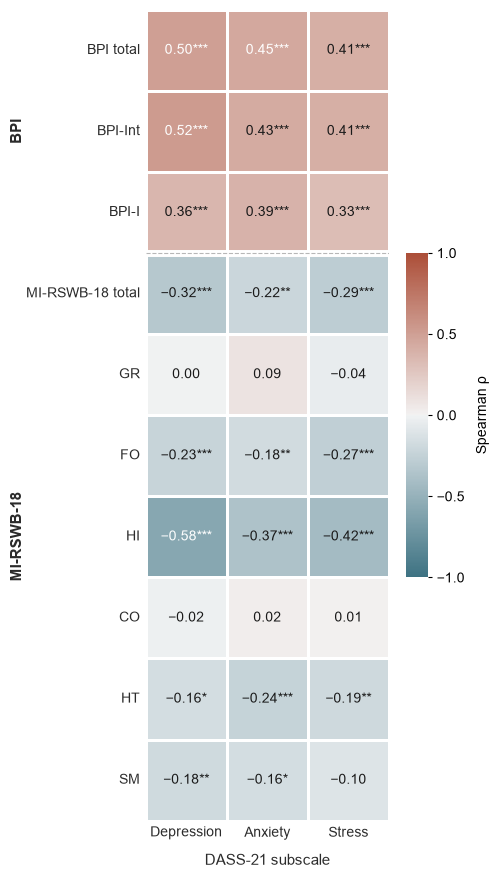

In [15]:
# SUPPLEMENTARY TABLE 6 and SUPPLEMENTARY FIGURE 1 — Spearman correlations
#   Paired bootstrap 95% CI and Benjamini–Hochberg FDR control
# ============================================================================
N_BOOT   = 2000
USE_FDR  = True          # Benjamini-Hochberg across the full 10 x 3 grid


def _fmt_p_local(p):
    """Local p formatter (independent of any later redefinition of fmt_p)."""
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "< .001"
    return f"{p:.3f}".lstrip("0")


def spearman_boot_ci(df, x, y, n_boot=N_BOOT, seed=SEED, min_n=30):
    """
    Spearman rho, asymptotic p-value, and PAIRED bootstrap 95% CI.
    Rows are resampled jointly so the x-y pairing is preserved.
    """
    d = df[[x, y]].apply(pd.to_numeric, errors="coerce").dropna()
    n = len(d)
    if n < min_n:
        return np.nan, np.nan, np.nan, np.nan, n

    rho, pval = stats.spearmanr(d[x], d[y])

    rng = np.random.default_rng(seed)
    xv  = d[x].to_numpy()
    yv  = d[y].to_numpy()
    boot = np.empty(n_boot, dtype=float)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)          # paired resampling
        boot[b] = stats.spearmanr(xv[idx], yv[idx]).statistic

    lo, hi = np.nanquantile(boot, [0.025, 0.975])
    return float(rho), float(pval), float(lo), float(hi), int(n)


# ── Single source of truth for labels ────────────────────────────────────────
# Long labels -> tables (Supplementary Table S6)
# Short labels -> heatmap axis (Supplementary Figure 1)
PREDICTORS = [
    # column,            table label,                    figure label,          group
    ("bpi_mean",         "BPI total (11 items)",         "BPI total",           "BPI"),
    ("bpi_interf_mean",  "BPI interference (items 1-7)", "BPI-Int",    "BPI"),
    ("bpi_int_mean",     "BPI intensity (items 8-11)",   "BPI-I",       "BPI"),
    ("mirswb_total",     "MI-RSWB-18 total",             "MI-RSWB-18 total",    "MI-RSWB-18"),
    ("mirswb_gr",        "MI-RSWB-18 General religiosity",  "GR", "MI-RSWB-18"),
    ("mirswb_fo",        "MI-RSWB-18 Forgiveness",          "FO",         "MI-RSWB-18"),
    ("mirswb_hi",        "MI-RSWB-18 Hope immanent",        "HI",       "MI-RSWB-18"),
    ("mirswb_co",        "MI-RSWB-18 Connectedness",        "CO",       "MI-RSWB-18"),
    ("mirswb_ht",        "MI-RSWB-18 Hope transcendent",    "HT",   "MI-RSWB-18"),
    ("mirswb_sm",        "MI-RSWB-18 Sense and meaning",    "SM",   "MI-RSWB-18"),
]

OUTCOMES = [
    ("dass_dep_interp", "DASS-21 Depression", "Depression"),
    ("dass_ans_interp", "DASS-21 Anxiety",    "Anxiety"),
    ("dass_st_interp",  "DASS-21 Stress",     "Stress"),
]

PRED_COLS   = [c for c, _, _, _ in PREDICTORS]
PRED_TABLE  = {c: t for c, t, _, _ in PREDICTORS}
PRED_FIG    = {c: f for c, _, f, _ in PREDICTORS}
PRED_GROUP  = {c: g for c, _, _, g in PREDICTORS}

OUT_COLS    = [c for c, _, _ in OUTCOMES]
OUT_TABLE   = {c: t for c, t, _ in OUTCOMES}
OUT_FIG     = {c: f for c, _, f in OUTCOMES}

# ── Compute the correlation grid ─────────────────────────────────────────────
corr_rows = []
for x in PRED_COLS:
    for y in OUT_COLS:
        rho, pval, lo, hi, n = spearman_boot_ci(rp2, x, y)
        corr_rows.append({
            "pred_col":  x,
            "out_col":   y,
            "Predictor": PRED_TABLE[x],
            "Outcome":   OUT_TABLE[y],
            "rho":       rho,
            "ci_low":    lo,
            "ci_high":   hi,
            "p_raw":     pval,
            "n":         n,
        })

corr_tbl = pd.DataFrame(corr_rows)

# ── Multiplicity control across the whole 10 x 3 grid ────────────────────────
ok = corr_tbl["p_raw"].notna()
corr_tbl["p_fdr"] = np.nan
if USE_FDR and ok.any():
    corr_tbl.loc[ok, "p_fdr"] = multipletests(
        corr_tbl.loc[ok, "p_raw"].to_numpy(), alpha=0.05, method="fdr_bh"
    )[1]

# p-value that drives the stars in the figure
P_STAR_COL = "p_fdr" if USE_FDR else "p_raw"

# ── Ordering (kept identical to the figure row/column order) ─────────────────
corr_tbl["pred_col"] = pd.Categorical(corr_tbl["pred_col"], categories=PRED_COLS, ordered=True)
corr_tbl["out_col"]  = pd.Categorical(corr_tbl["out_col"],  categories=OUT_COLS,  ordered=True)
corr_tbl = corr_tbl.sort_values(["pred_col", "out_col"]).reset_index(drop=True)

def fmt_rho(x, d=2):
    """Fixed decimals, typographic minus, and no '-0.00'."""
    if pd.isna(x):
        return ""
    x = 0.0 if round(x, d) == 0 else x
    return f"{x:.{d}f}".replace("-", MINUS)

# ── Supplementary Table S6 (this was computed but never displayed before) ────
supp_table_s6 = pd.DataFrame({
    "Predictor": corr_tbl["Predictor"].str.replace("-", "\u2013", regex=False)
                                      .str.replace("MI\u2013RSWB\u201318", "MI-RSWB-18", regex=False),
    "Outcome":   corr_tbl["Outcome"],
    "ρ":         corr_tbl["rho"].map(fmt_rho),
    "95% CI":    corr_tbl.apply(
        lambda r: "" if pd.isna(r["ci_low"])
        else f"{fmt_rho(r['ci_low'])} to {fmt_rho(r['ci_high'])}", axis=1),
    "p value":           corr_tbl["p_raw"].map(fmt_p_table),
    "FDR-adjusted p":    corr_tbl["p_fdr"].map(fmt_p_table),
    "n":         corr_tbl["n"],
})

print("=" * 70)
print("SUPPLEMENTARY TABLE S6 — Spearman correlations "
      f"(paired bootstrap 95% CI, {N_BOOT} resamples; BH-FDR over "
      f"{int(ok.sum())} tests)")
print("=" * 70)
display(supp_table_s6)


# ============================================================================
# Heatmap
# ============================================================================
row_order = [PRED_FIG[c] for c in PRED_COLS]
col_order = [OUT_FIG[c]  for c in OUT_COLS]

corr_tbl["_row"] = corr_tbl["pred_col"].map(PRED_FIG)
corr_tbl["_col"] = corr_tbl["out_col"].map(OUT_FIG)

rho_fig = (corr_tbl.pivot(index="_row", columns="_col", values="rho")
                   .reindex(index=row_order, columns=col_order))
p_fig   = (corr_tbl.pivot(index="_row", columns="_col", values=P_STAR_COL)
                   .reindex(index=row_order, columns=col_order))

rho_fig.index.name = None
rho_fig.columns.name = None


def _sig_stars(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""


annot_fig = pd.DataFrame(
    [[("" if pd.isna(rho_fig.loc[r, c])
       else f"{fmt_rho(rho_fig.loc[r, c])}{_sig_stars(p_fig.loc[r, c])}")
      for c in col_order]
     for r in row_order],
    index=row_order, columns=col_order,
)

# ── Style ────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
})

cmap = sns.diverging_palette(220, 20, s=70, l=45, as_cmap=True)

fig, ax = plt.subplots(figsize=(6.2, 9))

sns.heatmap(
    rho_fig,
    annot=annot_fig, fmt="",
    cmap=cmap, center=0, vmin=-1, vmax=1,
    linewidths=0.8, linecolor="white", square=True,
    annot_kws={"size": 10},
    cbar_kws={"shrink": 0.40, "aspect": 15, "pad": 0.03, "orientation": "vertical"},
    ax=ax,
)

# Annotation colour: white on saturated cells, dark on pale cells
for text in ax.texts:
    xi, yi = int(text.get_position()[0]), int(text.get_position()[1])
    val = rho_fig.iloc[yi, xi]
    text.set_color("white" if (pd.notna(val) and abs(val) > 0.45) else "#1a1a1a")
    text.set_fontsize(10)

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=10, length=3)
cbar.set_label("Spearman ρ", size=10, labelpad=8)
cbar.set_ticks([-1, -0.5, 0, 0.5, 1])
cbar.outline.set_visible(False)

# ── Ticks: set locations AND labels together (avoids silent misalignment) ────
ax.set_xticks(np.arange(len(col_order)) + 0.5)
ax.set_xticklabels(col_order, rotation=0, ha="center",
                   fontsize=10, color="#2b2b2b")
ax.tick_params(axis="x", which="both", length=0, pad=4)

ax.set_yticks(np.arange(len(row_order)) + 0.5)
ax.set_yticklabels(row_order, rotation=0, ha="right",
                   fontsize=10, color="#2b2b2b")
ax.tick_params(axis="y", which="both", length=0, pad=4)

ax.set_xlabel("DASS-21 subscale", fontsize=11, labelpad=10, color="#2b2b2b")
ax.set_ylabel("")

# ── Group separator + group labels (computed, not hard-coded) ───────────────
groups = [PRED_GROUP[c] for c in PRED_COLS]
boundaries = [i for i in range(1, len(groups)) if groups[i] != groups[i - 1]]
for b in boundaries:
    ax.axhline(y=b, color="white",   linewidth=5,   zorder=3)
    ax.axhline(y=b, color="#888888", linewidth=0.8,
               linestyle="--", zorder=4, alpha=0.6)

# Bracketed group names, placed just outside the widest y tick label
plt.tight_layout(pad=1.5)
fig.canvas.draw()
_rend  = fig.canvas.get_renderer()
_ax_w  = ax.get_window_extent(_rend).width
_lab_w = max(t.get_window_extent(_rend).width for t in ax.get_yticklabels())
_x_grp = -(_lab_w / _ax_w) - 0.06          # axes-fraction, left of the labels

starts = [0] + boundaries
ends   = boundaries + [len(groups)]
for s, e in zip(starts, ends):
    ax.text(_x_grp, (s + e) / 2, groups[s],
            transform=ax.get_yaxis_transform(),
            rotation=90, va="center", ha="center",
            fontsize=10.5, fontweight="bold", color="#2b2b2b")

save_figure(fig, "Supplementary_Figure_1")

### Regression diagnostics (Appendix C.1.4)

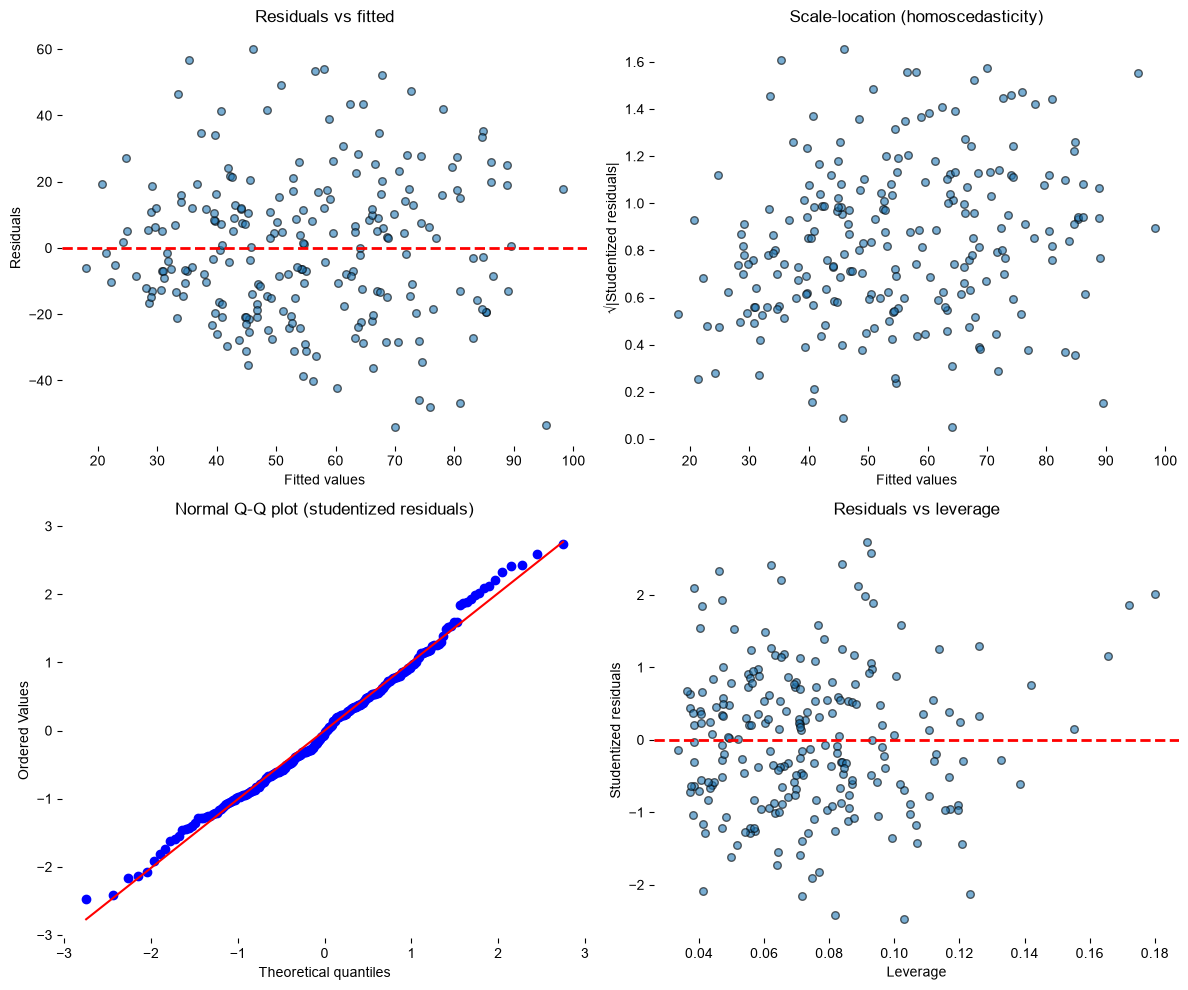

Breusch-Pagan: LM(16) = 26.46, p = 0.048
Shapiro-Wilk:  W = 0.992, p = 0.210
Jarque-Bera:   JB = 2.38, p = 0.305
Cook's distance > 4/n (0.017): 14 observations; max = 0.052
|Studentized residual| > 3: 0 observations

Generalized VIF — S1 continuous


,Term,df,GVIF,GVIF^(1/(2·df))
0,genero,1,1.13,1.06
1,edu_grp,2,1.23,1.05
2,civil_grp,3,1.44,1.06
3,dx_grp2,3,1.22,1.03
4,bpi_interf_mean,1,1.90,1.38
5,bpi_int_mean,1,2.03,1.43
6,mirswb_total,1,1.14,1.07
7,edad,1,1.54,1.24
8,duracion_dolor,1,1.21,1.10



Generalized VIF — S2-A tertiles (primary)


,Term,df,GVIF,GVIF^(1/(2·df))
0,bpi_interf_tert,2,1.71,1.14
1,mirswb_tert,2,1.19,1.04
2,genero,1,1.13,1.06
3,edu_grp,2,1.26,1.06
4,civil_grp,3,1.46,1.07
5,dx_grp2,3,1.26,1.04
6,bpi_int_mean,1,1.73,1.31
7,edad,1,1.53,1.24
8,duracion_dolor,1,1.21,1.10



Max adjusted GVIF across models: 1.43 (sqrt(5) = 2.24; sqrt(10) = 3.16)


,Assumption,Test / check,Interpretation
0,Linearity,"Nested F-test, linear vs restricted cubic spli...",Nonlinearity addressed via tertile coding
1,Independence,"Cross-sectional design, one observation per pa...",Assumed by design
2,Homoscedasticity,"Breusch-Pagan LM = 26.46, p = 0.048",Heteroskedasticity detected; HC3 robust SEs used
3,Normality of residuals,"Shapiro-Wilk W = 0.992, p = 0.210; Jarque-Bera...",No evidence against normality
4,Influential observations,14 obs. with Cook's D > 4/n (max 0.052); 0 wit...,Inspect leverage plot
5,Multicollinearity,Max adjusted GVIF = 1.43,No problematic multicollinearity


✓ Saved: results/figures/ols_diagnostics_primary_model.png / .pdf


In [16]:
# ============================================================================
# OLS ASSUMPTION DIAGNOSTICS — primary tertile model (Supplementary Table 2, Panel A)
# ============================================================================
diag_model = m_tertiles
assert all(v in diag_model.model.formula for v in ("edu_grp", "civil_grp", "dx_grp2")), \
    "Diagnostics must use the collapsed-coding primary model"

infl      = OLSInfluence(diag_model)
fitted    = diag_model.fittedvalues
resid     = diag_model.resid
resid_stu = infl.resid_studentized_internal
leverage  = infl.hat_matrix_diag
cooks_d   = infl.cooks_distance[0]
n_obs     = int(diag_model.nobs)

# ── 7A. Visual diagnostics ───────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].scatter(fitted, resid, alpha=0.6, edgecolors="k", s=30)
axes[0, 0].axhline(0, color="red", linestyle="--", lw=2)
axes[0, 0].set(xlabel="Fitted values", ylabel="Residuals", title="Residuals vs fitted")

axes[0, 1].scatter(fitted, np.sqrt(np.abs(resid_stu)), alpha=0.6, edgecolors="k", s=30)
axes[0, 1].set(xlabel="Fitted values", ylabel="√|Studentized residuals|",
               title="Scale-location (homoscedasticity)")

stats.probplot(resid_stu, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Normal Q-Q plot (studentized residuals)")

axes[1, 1].scatter(leverage, resid_stu, alpha=0.6, edgecolors="k", s=30)
axes[1, 1].axhline(0, color="red", linestyle="--", lw=2)
axes[1, 1].set(xlabel="Leverage", ylabel="Studentized residuals",
               title="Residuals vs leverage")

plt.tight_layout()
plt.savefig(FIG_DIR / "ols_diagnostics_primary_model.png", dpi=150, bbox_inches="tight")
plt.show()

# ── 7B. Statistical tests ────────────────────────────────────────────────────
bp_stat, bp_pval, _, _ = het_breuschpagan(resid, diag_model.model.exog)
sw_stat, sw_pval       = stats.shapiro(resid)
jb_stat, jb_pval, _, _ = jarque_bera(resid)

cook_cut   = 4 / n_obs
n_cook     = int((cooks_d > cook_cut).sum())
n_outliers = int((np.abs(resid_stu) > 3).sum())

print(f"Breusch-Pagan: LM({int(diag_model.df_model)}) = {bp_stat:.2f}, p = {bp_pval:.3f}")
print(f"Shapiro-Wilk:  W = {sw_stat:.3f}, p = {sw_pval:.3f}")
print(f"Jarque-Bera:   JB = {jb_stat:.2f}, p = {jb_pval:.3f}")
print(f"Cook's distance > 4/n ({cook_cut:.3f}): {n_cook} observations; "
      f"max = {cooks_d.max():.3f}")
print(f"|Studentized residual| > 3: {n_outliers} observations")


# ── 7C. Generalized VIF (Fox & Monette, 1992) ────────────────────────────────
def gvif_table(res):
    """
    GVIF per model term (one row per variable, not per dummy).
    GVIF = det(R_term) * det(R_other) / det(R), with R the correlation matrix
    of the design columns excluding the intercept. For 1-df terms GVIF = VIF.
    GVIF^(1/(2*df)) is comparable across terms (compare with sqrt(5) or sqrt(10)).
    """
    # Rebuild the design matrix from the formula (design_info location varies across
    # statsmodels versions); patsy drops the same incomplete rows as the fitted model
    _, X_full = dmatrices(res.model.formula, res.model.data.frame, return_type="dataframe")
    assert X_full.shape[0] == int(res.nobs), "Design matrix rows differ from the fitted model"
    slices = X_full.design_info.term_name_slices

    X     = X_full.drop(columns="Intercept")
    R     = np.corrcoef(X.to_numpy(), rowvar=False)
    det_R = np.linalg.det(R)

    rows = []
    for term, sl in slices.items():
        # ... el resto del bucle queda igual
        if term == "Intercept":
            continue
        idx   = list(range(sl.start - 1, sl.stop - 1))        # shift: intercept removed
        other = [i for i in range(R.shape[0]) if i not in idx]
        gvif  = np.linalg.det(R[np.ix_(idx, idx)]) * np.linalg.det(R[np.ix_(other, other)]) / det_R
        m = re.match(r"C\((\w+)", term)
        rows.append({
            "Term": m.group(1) if m else term,
            "df": len(idx),
            "GVIF": round(gvif, 2),
            "GVIF^(1/(2·df))": round(gvif ** (1 / (2 * len(idx))), 2),
        })
    return pd.DataFrame(rows)


gvif_models = {"S1 continuous": m_continuous, "S2-A tertiles (primary)": m_tertiles}
gvif_results = {}
for name, res in gvif_models.items():
    tbl = gvif_table(res)
    gvif_results[name] = tbl
    print(f"\nGeneralized VIF — {name}")
    display(tbl)

max_adj_gvif = max(t["GVIF^(1/(2·df))"].max() for t in gvif_results.values())
print(f"\nMax adjusted GVIF across models: {max_adj_gvif:.2f} "
      f"(sqrt(5) = 2.24; sqrt(10) = 3.16)")

# ── 7D. Summary ──────────────────────────────────────────────────────────────
diag_summary = pd.DataFrame({
    "Assumption": ["Linearity", "Independence", "Homoscedasticity",
                   "Normality of residuals", "Influential observations",
                   "Multicollinearity"],
    "Test / check": [
        "Nested F-test, linear vs restricted cubic splines (Appendix C, 1.2); residual plots",
        "Cross-sectional design, one observation per participant",
        f"Breusch-Pagan LM = {bp_stat:.2f}, p = {bp_pval:.3f}",
        f"Shapiro-Wilk W = {sw_stat:.3f}, p = {sw_pval:.3f}; "
        f"Jarque-Bera JB = {jb_stat:.2f}, p = {jb_pval:.3f}",
        f"{n_cook} obs. with Cook's D > 4/n (max {cooks_d.max():.3f}); "
        f"{n_outliers} with |studentized residual| > 3",
        f"Max adjusted GVIF = {max_adj_gvif:.2f}",
    ],
    "Interpretation": [
        "Nonlinearity addressed via tertile coding",
        "Assumed by design",
        "Heteroskedasticity detected; HC3 robust SEs used" if bp_pval < 0.05
        else "No evidence of heteroskedasticity; HC3 robust SEs used as precaution",
        "No evidence against normality" if min(sw_pval, jb_pval) >= 0.05
        else "Departure from normality; inspect Q-Q plot",
        "Inspect leverage plot",
        "No problematic multicollinearity" if max_adj_gvif < np.sqrt(5)
        else "Inspect terms with adjusted GVIF > 2.24",
    ],
})
display(diag_summary)

save_figure(fig, "ols_diagnostics_primary_model")


## 3. Synthetic personas (SP)

### Shared SP–RP metrics (identifier-matched)

In [17]:
# ============================================================================
# SHARED METRICS — ID-matched SP–RP comparisons by task and LLM
#   master_table feeds Supplementary Tables 10–11 and Supplementary Figures 3–4
# ============================================================================
def get_step_datasets(step_number):
    """Analytic datasets for one step; RP is the prepared N = 230 sample."""
    return {"RP": rp2, **{lab: ALL_DATASETS[f"{key}_step{step_number}"]
                          for lab, key in MODEL_KEYS.items()}}

def _aligned(rp_df, sp_df, col, min_n=10):
    """Return (y_true, y_pred) matched by participant ID, or None if unavailable."""
    if col not in rp_df.columns or col not in sp_df.columns:
        return None
    m = rp_df[[ID_COL, col]].merge(sp_df[[ID_COL, col]], on=ID_COL,
                                   suffixes=("_rp", "_sp"), validate="one_to_one")
    y_true = pd.to_numeric(m[f"{col}_rp"], errors="coerce").to_numpy(float)
    y_pred = pd.to_numeric(m[f"{col}_sp"], errors="coerce").to_numpy(float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    return (y_true[mask], y_pred[mask]) if mask.sum() >= min_n else None


# ── Step specifications: inputs, primary outcome, and R² targets ──────────────
STEP_SPECS = {
    "Step 1": dict(datasets=get_step_datasets(1),
                   inputs="SocDemo",
                   outcome_col="bpi_mean",        outcome_name="Pain subscale (BPI-11 total)",
                   r2_dass=True,                 r2_mirswb=True),
    "Step 2": dict(datasets=get_step_datasets(2),
                   inputs="SocDemo; PDur",
                   outcome_col="bpi_mean",        outcome_name="Pain subscale (BPI-11 total)",
                   r2_dass=True,                 r2_mirswb=True),
    "Step 3": dict(datasets=get_step_datasets(3),
                   inputs="SocDemo; Dx",
                   outcome_col="bpi_mean",        outcome_name="Pain subscale (BPI-11 total)",
                   r2_dass=True,                 r2_mirswb=True),
    "Step 4": dict(datasets=get_step_datasets(4),
                   inputs="SocDemo; PDur; Dx; BPI-I",
                   outcome_col="bpi_interf_mean", outcome_name="Pain subscale (BPI-Interference)",
                   r2_dass=True,                 r2_mirswb=True),
    "Step 5": dict(datasets=get_step_datasets(5),
                   inputs="SocDemo; PDur; Dx; BPI-Int",
                   outcome_col="bpi_int_mean",    outcome_name="Pain subscale (BPI-Intensity)",
                   r2_dass=True,                 r2_mirswb=True),
    "Step 6": dict(datasets=get_step_datasets(6),
                   inputs="SocDemo; PDur; Dx; BPI-11",
                   outcome_col="dass_total_interp", outcome_name="DASS-21 (total)",
                   r2_dass=True,                    r2_mirswb=True),
    "Step 7": dict(datasets=get_step_datasets(7),
                   inputs="SocDemo; PDur; Dx; BPI-11; MI-RSWB-18",
                   outcome_col="dass_total_interp", outcome_name="DASS-21 (total)",
                   r2_dass=True,  r2_mirswb=False),  # MI-RSWB-18 is input → R² N/A
    "Step 8": dict(datasets=get_step_datasets(8),
                   inputs="SocDemo; PDur; Dx; BPI-11; DASS-21",
                   outcome_col="mirswb_total",    outcome_name="MI-RSWB-18 (total)",
                   r2_dass=False, r2_mirswb=True),  # DASS-21 is input → R² N/A
}

# ── Subscale columns for extended R² tracking ────────────────────────────────
DASS_SUB_COLS    = {"Depression": "dass_dep_interp",
                    "Anxiety":    "dass_ans_interp",
                    "Stress":     "dass_st_interp"}
MIRSWB_SUB_COLS  = {"GR":      "mirswb_gr",
                    "FO": "mirswb_fo",
                    "HI":        "mirswb_hi",
                    "CO":  "mirswb_co",
                    "HT":   "mirswb_ht",
                    "SM":     "mirswb_sm"}


def _pairwise_r2(rp_df, sp_df, col):
    pair = _aligned(rp_df, sp_df, col)
    return np.nan if pair is None else r2_score(*pair)


def _pairwise_rmse_mae(rp_df, sp_df, col):
    pair = _aligned(rp_df, sp_df, col)
    if pair is None:
        return np.nan, np.nan, 0
    y_true, y_pred = pair
    return (np.sqrt(mean_squared_error(y_true, y_pred)),
            mean_absolute_error(y_true, y_pred), len(y_true))


# ── Build master table ────────────────────────────────────────────────────────
rows = []
for step_name, spec in STEP_SPECS.items():
    rp_df   = spec["datasets"]["RP"]
    out_col = spec["outcome_col"]
    rp_mean = rp_df[out_col].mean() if out_col in rp_df.columns else np.nan

    for model in ["GPT", "DeepSeek", "Llama"]:
        sp_df   = spec["datasets"][model]
        sp_mean = sp_df[out_col].mean() if out_col in sp_df.columns else np.nan
        delta   = ((sp_mean - rp_mean) / rp_mean * 100) if pd.notna(rp_mean) else np.nan
        rmse, mae, n_pairs = _pairwise_rmse_mae(rp_df, sp_df, out_col)

        row = {
            "Step":                    step_name,
            "Model":                   model,
            "Inputs provided":         spec["inputs"],
            "Outcome generated":       spec["outcome_name"],
            "RP mean":                 rp_mean,
            "SP mean":                 sp_mean,
            "ΔMean (%)":              delta,
            "RMSE":                    rmse,
            "MAE":                     mae,
            "n pairs":                 n_pairs,
            "R² (DASS-21 outcome)":   _pairwise_r2(rp_df, sp_df, "dass_total_interp")
                                        if spec["r2_dass"] else np.nan,
            "R² (MI-RSWB-18 outcome)": _pairwise_r2(rp_df, sp_df, "mirswb_total")
                                        if spec["r2_mirswb"] else np.nan,
        }
        # DASS-21 subscales
        for label, col in DASS_SUB_COLS.items():
            row[f"R² (DASS-21 {label})"] = (
                _pairwise_r2(rp_df, sp_df, col) if spec["r2_dass"] else np.nan
            )
        # MI-RSWB subscales
        for label, col in MIRSWB_SUB_COLS.items():
            row[f"R² (MI-RSWB {label})"] = (
                _pairwise_r2(rp_df, sp_df, col) if spec["r2_mirswb"] else np.nan
            )
        rows.append(row)

# Sort and round
step_order  = [f"Step {i}" for i in range(1, 9)]

master_table = (pd.DataFrame(rows)
                .assign(Step=lambda d: pd.Categorical(d["Step"], categories=step_order, ordered=True),
                        Model=lambda d: pd.Categorical(d["Model"], categories=MODEL_ORDER, ordered=True))
                .sort_values(["Step", "Model"]).reset_index(drop=True))

assert (master_table["n pairs"] == 230).all(), "Some step/model has fewer than 230 matched pairs"

master_table_round = master_table.copy()
num_cols = master_table_round.select_dtypes(include="number").columns.drop("n pairs")
master_table_round[num_cols] = master_table_round[num_cols].round(2)
display(master_table_round)


,Step,Model,Inputs provided,Outcome generated,RP mean,SP mean,ΔMean (%),RMSE,MAE,n pairs,...,R² (MI-RSWB-18 outcome),R² (DASS-21 Depression),R² (DASS-21 Anxiety),R² (DASS-21 Stress),R² (MI-RSWB GR),R² (MI-RSWB FO),R² (MI-RSWB HI),R² (MI-RSWB CO),R² (MI-RSWB HT),R² (MI-RSWB SM)
0,Step 1,GPT,SocDemo,Pain subscale (BPI-11 total),6.64,5.57,-16.01,2.01,1.65,230,...,-0.26,-0.08,-0.11,-0.15,-0.38,-0.59,-0.60,-0.10,-0.60,-0.01
1,Step 1,DeepSeek,SocDemo,Pain subscale (BPI-11 total),6.64,6.25,-5.82,1.78,1.42,230,...,-0.24,-0.28,-0.43,-0.47,-1.95,-0.72,-0.24,-1.03,-2.06,-0.20
2,Step 1,Llama,SocDemo,Pain subscale (BPI-11 total),6.64,5.71,-14.03,1.95,1.61,230,...,-1.38,-0.21,-0.11,-0.14,-1.44,-1.05,-2.45,-0.35,-0.85,-0.26
3,Step 2,GPT,SocDemo; PDur,Pain subscale (BPI-11 total),6.64,5.55,-16.33,2.05,1.68,230,...,-0.26,-0.16,-0.11,-0.16,-0.47,-0.60,-0.53,-0.15,-0.52,-0.09
4,Step 2,DeepSeek,SocDemo; PDur,Pain subscale (BPI-11 total),6.64,6.29,-5.23,1.73,1.41,230,...,-0.32,-0.39,-0.33,-0.43,-1.84,-0.68,-0.14,-1.08,-2.11,-0.18
5,Step 2,Llama,SocDemo; PDur,Pain subscale (BPI-11 total),6.64,5.65,-14.95,2.01,1.67,230,...,-1.39,-0.20,-0.24,-0.10,-1.50,-1.06,-2.48,-0.39,-0.67,-0.44
6,Step 3,GPT,SocDemo; Dx,Pain subscale (BPI-11 total),6.64,5.57,-16.11,2.04,1.67,230,...,-0.26,-0.09,-0.17,-0.13,-0.53,-0.55,-0.54,-0.14,-0.64,-0.02
7,Step 3,DeepSeek,SocDemo; Dx,Pain subscale (BPI-11 total),6.64,6.33,-4.63,1.72,1.38,230,...,-0.50,-0.24,-0.53,-0.37,-1.81,-0.62,-0.22,-1.32,-1.87,-0.32
8,Step 3,Llama,SocDemo; Dx,Pain subscale (BPI-11 total),6.64,5.78,-12.85,1.92,1.58,230,...,-1.41,-0.20,-0.14,-0.07,-1.45,-1.06,-2.54,-0.30,-0.87,-0.28
9,Step 4,GPT,SocDemo; PDur; Dx; BPI-I,Pain subscale (BPI-Interference),6.85,6.00,-12.41,1.67,1.36,230,...,-0.35,0.02,-0.01,-0.03,-0.58,-0.50,-0.61,-0.13,-0.52,-0.00


## 3.1 Multivariable structural fidelity (RQ1)

In [18]:
# ============================================================================
# RQ1 — SP RECODING AND TERTILE-MODEL SENSITIVITY
#   Categorical recoding identical to RP; RP tertile cut-points; Tasks 1–7
#   Outputs: rq1_structural_diagnostics.csv, rq1_structural_coefficients.csv
# ============================================================================
RQ1_TASKS   = list(range(1, 8))
TERT_LABELS = ["Low", "Medium", "High"]
CAT_SOURCE  = ["genero", "estudios", "estado_civil", "causa_dolor"]
CAT_MODEL   = ["edu_grp", "civil_grp", "dx_grp2", "bpi_interf_tert", "mirswb_tert"]
CAT_REF     = {"edu_grp": EDU_REF, "civil_grp": "Casado/a",
               "dx_grp2": "Dolor crónico primario", "bpi_interf_tert": "Low", "mirswb_tert": "High"}

KEY_TERMS = {
    ("bpi_interf_tert", "Medium"): "BPI-Int tertile: Medium",
    ("bpi_interf_tert", "High"):   "BPI-Int tertile: High",
    ("bpi_int_mean", None):        "BPI-I score",
    ("mirswb_tert", "Low"):        "MI-RSWB-18 tertile: Low",
    ("mirswb_tert", "Medium"):     "MI-RSWB-18 tertile: Medium",
}


# ── Recoding helpers (mirror RP data preparation) ────────────────────────────
def _norm_label(s):
    """Unicode-normalised, trimmed, case-insensitive label for matching."""
    if pd.isna(s):
        return np.nan
    s = unicodedata.normalize("NFC", str(s)).strip()
    return re.sub(r"\s+", " ", s).casefold()


CANON = {col: {_norm_label(v): v for v in rp2[col].dropna().astype(str).str.strip().unique()}
         for col in CAT_SOURCE}
BPI_CUTS    = [-np.inf, round(float(bpi_int_q[1/3]), 6), round(float(bpi_int_q[2/3]), 6), np.inf]
MIRSWB_CUTS = [-np.inf, 56, 66, np.inf]
DX2_MAP     = {**{c: "Dx_other_unspec" for c in RARE_CAUSES}, "No lo sé.": "Dx_other_unspec"}
CIV2_MAP    = {"Viudo/a": "Separado/a o viudo/a", "Separado/a": "Separado/a o viudo/a"}


def prepare_for_model(df):
    """Apply RP recoding (labels, collapsed categories, RP tertile cut-points)."""
    d = df.copy()
    for col, cmap in CANON.items():
        norm = d[col].map(_norm_label)
        unmapped = set(norm.dropna()) - set(cmap)
        if unmapped:
            raise ValueError(f"{col}: levels not present in RP: {unmapped}")
        d[col] = norm.map(cmap).astype(object)
    d["edu_grp"] = pd.Categorical(d["estudios"].replace({"Otros": EDU_REF}),
                                  categories=rp2["edu_grp"].cat.categories)
    d["civil_grp"] = pd.Categorical(d["estado_civil"].replace(CIV2_MAP),
                                    categories=rp2["civil_grp"].cat.categories)
    d["dx_grp2"] = pd.Categorical(d["causa_dolor"].replace(DX2_MAP),
                                  categories=rp2["dx_grp2"].cat.categories)
    d["bpi_interf_tert"] = pd.cut(pd.to_numeric(d["bpi_interf_mean"]).round(6), BPI_CUTS,
                                  labels=TERT_LABELS, right=True)
    d["mirswb_tert"] = pd.cut(pd.to_numeric(d["mirswb_total"]), MIRSWB_CUTS,
                              labels=TERT_LABELS, right=True)
    return d


def fit_structural(d, outcome="dass_total_interp"):
    """Fit the primary tertile model; drop empty levels, stop if a reference is absent."""
    cols = [outcome, "bpi_interf_mean", "bpi_int_mean", "mirswb_total",
            "edad", "duracion_dolor", "genero"] + CAT_MODEL
    d = d.dropna(subset=cols).copy()
    notes = []
    for c in CAT_MODEL:
        counts = d[c].value_counts()
        empty = counts[counts == 0].index.tolist()
        if empty:
            notes += [f"{c}:{lv} empty" for lv in empty]
            d[c] = d[c].cat.remove_unused_categories()
        if CAT_REF[c] not in d[c].cat.categories:
            return None, d, notes + [f"{c}: reference level absent"]
    return fit_ols(outcome, PRED_TERTILES, COVARS_COLLAPSED, d), d, notes


def key_coefs(m):
    """β and 95% CI for each key term (NaN if the term is absent)."""
    ci = m.conf_int()
    lookup = {parse_term(t): t for t in m.params.index}
    return {k: (np.nan, np.nan, np.nan) if lookup.get(k) is None
            else (m.params[lookup[k]], ci.loc[lookup[k], 0], ci.loc[lookup[k], 1])
            for k in KEY_TERMS}


# ── Pipeline check: recoding the raw RP must reproduce Supplementary Table 2-A ─
_rp_prep = prepare_for_model(ALL_DATASETS["rp"])
_chk = _rp_prep[[ID_COL] + CAT_MODEL].merge(rp2[[ID_COL] + CAT_MODEL], on=ID_COL,
                                            suffixes=("", "_ref"), validate="one_to_one")
for c in CAT_MODEL:
    assert (_chk[c].astype(str) == _chk[f"{c}_ref"].astype(str)).all(), f"RP recoding mismatch: {c}"
_m_chk, _, _ = fit_structural(_rp_prep)
assert np.allclose(_m_chk.params.reindex(m_tertiles.params.index), m_tertiles.params), \
    "Refitted RP model does not reproduce Supplementary Table 2, Panel A"
print("✓ Recoding pipeline reproduces the RP primary model")

rp_key = key_coefs(m_tertiles)
PRIMARY_TERMS = [k for k, (b, lo, hi) in rp_key.items() if lo > 0 or hi < 0]
print("Terms used for agreement metrics (RP 95% CI excludes 0):",
      [KEY_TERMS[k] for k in PRIMARY_TERMS])


# ── Fit SP models ────────────────────────────────────────────────────────────
coef_rows, diag_rows = [], []
for t in RQ1_TASKS:
    for model, key in MODEL_KEYS.items():
        prep = prepare_for_model(ALL_DATASETS[f"{key}_step{t}"])
        m, d, notes = fit_structural(prep)
        level_n = [int(v) for c in CAT_MODEL for v in d[c].value_counts() if v > 0]
        diag_rows.append({
            "Task": t, "Model": model, "n": len(d),
            "SD DASS-21 generated": d["dass_total_interp"].std(),
            "BPI-Int tertiles L/M/H": "/".join(str(int(v)) for v in
                                               d["bpi_interf_tert"].value_counts().reindex(TERT_LABELS, fill_value=0)),
            "MI-RSWB-18 tertiles L/M/H": "/".join(str(int(v)) for v in
                                                  d["mirswb_tert"].value_counts().reindex(TERT_LABELS, fill_value=0)),
            "Smallest category n": min(level_n),
            "Notes": "; ".join(notes) or "none",
            "Full rank": bool(m is not None and
                              np.linalg.matrix_rank(m.model.exog) == m.model.exog.shape[1]),
            "R2": m.rsquared if m is not None else np.nan,
            "Adj R2": m.rsquared_adj if m is not None else np.nan,
        })
        if m is None:
            continue
        for k, (b, lo, hi) in key_coefs(m).items():
            rb, rlo, rhi = rp_key[k]
            coef_rows.append({
                "Task": t, "Model": model, "Term": KEY_TERMS[k], "primary": k in PRIMARY_TERMS,
                "beta": b, "ci_low": lo, "ci_high": hi, "beta_RP": rb, "delta_beta": b - rb,
                "same_sign": float(np.sign(b) == np.sign(rb)) if pd.notna(b) else np.nan,
                "within_RP_CI": float(rlo <= b <= rhi) if pd.notna(b) else np.nan,
            })

df_rq1_diag = pd.DataFrame(diag_rows)
df_rq1 = pd.DataFrame(coef_rows)
df_rq1_diag.round(3).to_csv(OUT_DIR / "rq1_structural_diagnostics.csv", index=False, encoding="utf-8-sig")
df_rq1.round(4).to_csv(OUT_DIR / "rq1_structural_coefficients.csv", index=False, encoding="utf-8-sig")

print(f"\nRP primary model: R² = {m_tertiles.rsquared:.3f}; adjusted R² = {m_tertiles.rsquared_adj:.3f}; "
      f"SD DASS-21 = {rp2['dass_total_interp'].std():.1f}")
display(df_rq1_diag.round(2))
for _, r in df_rq1_diag.iterrows():
    tert_min = min(int(x) for x in (r["BPI-Int tertiles L/M/H"] + "/" + r["MI-RSWB-18 tertiles L/M/H"]).split("/"))
    if r["Notes"] != "none" or not r["Full rank"] or tert_min < 10 or r["Smallest category n"] < 5:
        print(f"⚠ Task {r['Task']} {r['Model']}: notes={r['Notes']}; full rank={r['Full rank']}; "
              f"smallest tertile n={tert_min}; smallest category n={r['Smallest category n']}")


✓ Recoding pipeline reproduces the RP primary model
Terms used for agreement metrics (RP 95% CI excludes 0): ['BPI-Int tertile: Medium', 'BPI-Int tertile: High', 'BPI-I score', 'MI-RSWB-18 tertile: Low']

RP primary model: R² = 0.384; adjusted R² = 0.337; SD DASS-21 = 28.3


,Task,Model,n,SD DASS-21 generated,BPI-Int tertiles L/M/H,MI-RSWB-18 tertiles L/M/H,Smallest category n,Notes,Full rank,R2,Adj R2
0,1,GPT,230,4.98,212/18/0,29/121/80,5,bpi_interf_tert:High empty,True,0.10,0.04
1,1,DeepSeek,230,12.22,55/175/0,36/105/89,16,bpi_interf_tert:High empty,True,0.22,0.16
2,1,Llama,230,9.60,198/32/0,6/23/201,4,dx_grp2:Dx_other_unspec empty; bpi_interf_tert...,True,0.06,-0.00
3,2,GPT,230,5.87,211/19/0,31/117/82,3,bpi_interf_tert:High empty,True,0.16,0.10
4,2,DeepSeek,230,12.23,62/168/0,50/90/90,16,bpi_interf_tert:High empty,True,0.16,0.10
5,2,Llama,230,9.40,199/31/0,1/23/206,1,dx_grp2:Dx_other_unspec empty; bpi_interf_tert...,True,0.04,-0.02
6,3,GPT,230,5.27,216/14/0,31/110/89,14,bpi_interf_tert:High empty,True,0.07,0.00
7,3,DeepSeek,230,10.67,62/168/0,45/114/71,16,bpi_interf_tert:High empty,True,0.12,0.05
8,3,Llama,230,9.95,186/44/0,1/21/208,1,bpi_interf_tert:High empty,True,0.03,-0.03
9,4,GPT,230,8.16,125/94/11,23/97/110,11,none,True,0.45,0.41


⚠ Task 1 GPT: notes=bpi_interf_tert:High empty; full rank=True; smallest tertile n=0; smallest category n=5
⚠ Task 1 DeepSeek: notes=bpi_interf_tert:High empty; full rank=True; smallest tertile n=0; smallest category n=16
⚠ Task 1 Llama: notes=dx_grp2:Dx_other_unspec empty; bpi_interf_tert:High empty; full rank=True; smallest tertile n=0; smallest category n=4
⚠ Task 2 GPT: notes=bpi_interf_tert:High empty; full rank=True; smallest tertile n=0; smallest category n=3
⚠ Task 2 DeepSeek: notes=bpi_interf_tert:High empty; full rank=True; smallest tertile n=0; smallest category n=16
⚠ Task 2 Llama: notes=dx_grp2:Dx_other_unspec empty; bpi_interf_tert:High empty; full rank=True; smallest tertile n=0; smallest category n=1
⚠ Task 3 GPT: notes=bpi_interf_tert:High empty; full rank=True; smallest tertile n=0; smallest category n=14
⚠ Task 3 DeepSeek: notes=bpi_interf_tert:High empty; full rank=True; smallest tertile n=0; smallest category n=16
⚠ Task 3 Llama: notes=bpi_interf_tert:High empty; f

### Supplementary Table 7 — Standardized coefficients

In [19]:
# ============================================================================
# RQ1 — PRIMARY ANALYSIS: standardized continuous specification
#   RP tertile cut-points cannot be applied to generated scores (empty high
#   BPI-Int tertile in Tasks 1–3; sparse MI-RSWB-18 tertiles). The continuous
#   specification (Supplementary Table 1) is refitted in each dataset with the
#   outcome and continuous predictors z-scored within that dataset.
#   Tertile-model estimates are kept as sensitivity (rq1_structural_coefficients.csv).
# ============================================================================
STD_TERMS = {"bpi_interf_mean": "BPI-Int", "bpi_int_mean": "BPI-I", "mirswb_total": "MI-RSWB-18 total"}
CONT_COLS = ["bpi_interf_mean", "bpi_int_mean", "mirswb_total", "edad", "duracion_dolor"]
MODEL_ORDER = ["GPT", "DeepSeek", "Llama"]


def fit_standardized(d, outcome="dass_total_interp"):
    """Continuous specification; outcome and continuous predictors z-scored within dataset."""
    d = d.dropna(subset=[outcome] + CONT_COLS + ["genero", "edu_grp", "civil_grp", "dx_grp2"]).copy()
    sd_y = d[outcome].std(ddof=1)
    for c in [outcome] + CONT_COLS:
        d[c] = (d[c] - d[c].mean()) / d[c].std(ddof=1)
    for c in ["edu_grp", "civil_grp", "dx_grp2"]:
        d[c] = d[c].cat.remove_unused_categories()
    m = fit_ols(outcome, PRED_CONTINUOUS, COVARS_COLLAPSED, d)
    ci = m.conf_int()
    return m, sd_y, {t: (m.params[t], ci.loc[t, 0], ci.loc[t, 1]) for t in STD_TERMS}


def compare_rows(coefs, rp_coefs, **extra):
    out = []
    for term, (b, lo, hi) in coefs.items():
        rb, rlo, rhi = rp_coefs[term]
        out.append({**extra, "Term": STD_TERMS[term], "beta": b, "ci_low": lo, "ci_high": hi,
                    "beta_RP": rb, "same_sign": float(np.sign(b) == np.sign(rb)),
                    "within_RP_CI": float(rlo <= b <= rhi)})
    return out


m_rp_std, sd_rp, rp_std = fit_standardized(rp2)
assert np.isclose(m_rp_std.rsquared, m_continuous.rsquared), "Standardized RP model != Supplementary Table 1"

std_rows = []
for t in RQ1_TASKS:
    for model, key in MODEL_KEYS.items():
        m, sd_y, coefs = fit_standardized(prepare_for_model(ALL_DATASETS[f"{key}_step{t}"]))
        std_rows += compare_rows(coefs, rp_std, Task=t, Model=model, R2=m.rsquared, SD_ratio=sd_y / sd_rp)
df_std = pd.DataFrame(std_rows)
df_std.round(4).to_csv(OUT_DIR / "rq1_standardized_coefficients.csv", index=False, encoding="utf-8-sig")

# ── Supplementary Table S7 ───────────────────────────────────────────────────
ci_cell = lambda b, lo, hi, mark="": f"{fmt_num(b)} ({fmt_num(lo)} to {fmt_num(hi)}){mark}"
rows = [{"Task": "RP", "Model": EM_DASH, **{lab: ci_cell(*rp_std[t]) for t, lab in STD_TERMS.items()},
         "R²": fmt_r2(m_rp_std.rsquared), "SD ratio": "1.00"}]
for (t, model), g in df_std.groupby(["Task", "Model"], sort=False):
    g = g.set_index("Term")
    rows.append({"Task": t, "Model": ABBR[model],
                 **{lab: ci_cell(g.loc[lab, "beta"], g.loc[lab, "ci_low"], g.loc[lab, "ci_high"],
                                 "\u2020" if g.loc[lab, "within_RP_CI"] else "")
                    for lab in STD_TERMS.values()},
                 "R²": fmt_r2(g["R2"].iloc[0]), "SD ratio": f"{g['SD_ratio'].iloc[0]:.2f}"})
s7_rq1 = pd.DataFrame(rows).set_index(["Task", "Model"])
export_table(s7_rq1, "SUPPLEMENTARY TABLE S7 — Standardized coefficients (β, 95% CI; † within RP 95% CI)",
             "supp_table_S7_structural_fidelity.csv")

display(df_std.assign(Block=np.where(df_std["Task"] <= 3, "Tasks 1–3", "Tasks 4–7"))
        .groupby(["Block", "Term", "Model"])[["same_sign", "within_RP_CI"]].sum()
        .unstack("Model").astype(int))

# ── Secondary: DASS-21 subscales (CSV only) ──────────────────────────────────
sub_rows = []
for lab, col in DASS_SUBSCALES.items():
    _, _, rp_sub = fit_standardized(rp2, col)
    for t in RQ1_TASKS:
        for model, key in MODEL_KEYS.items():
            m, _, coefs = fit_standardized(prepare_for_model(ALL_DATASETS[f"{key}_step{t}"]), col)
            sub_rows += compare_rows(coefs, rp_sub, Subscale=lab, Task=t, Model=model, R2=m.rsquared)
df_std_sub = pd.DataFrame(sub_rows)
df_std_sub.round(4).to_csv(OUT_DIR / "rq1_standardized_subscales.csv", index=False, encoding="utf-8-sig")
display(df_std_sub.groupby(["Subscale", "Model"])[["same_sign", "within_RP_CI"]].sum().astype(int))



SUPPLEMENTARY TABLE S7 — Standardized coefficients (β, 95% CI; † within RP 95% CI)


BPI-Int                   BPI-I  \
Task Model                                                  
RP   —        0.36 (0.19 to 0.54)    0.13 (−0.05 to 0.31)   
1    GPT     0.08 (−0.10 to 0.26)    0.21 (0.07 to 0.36)†   
     DS      0.22 (0.09 to 0.36)†   0.11 (−0.03 to 0.24)†   
     Llama  −0.02 (−0.17 to 0.14)   0.01 (−0.14 to 0.17)†   
2    GPT     0.05 (−0.10 to 0.21)   0.10 (−0.04 to 0.25)†   
     DS      0.11 (−0.08 to 0.31)   0.13 (−0.04 to 0.30)†   
     Llama   0.07 (−0.17 to 0.31)   0.03 (−0.19 to 0.25)†   
3    GPT     0.02 (−0.13 to 0.16)   0.01 (−0.18 to 0.19)†   
     DS      0.17 (−0.03 to 0.37)   0.16 (−0.01 to 0.32)†   
     Llama   0.09 (−0.08 to 0.26)  −0.05 (−0.23 to 0.13)†   
4    GPT      0.58 (0.20 to 0.96)  −0.02 (−0.38 to 0.35)†   
     DS      0.06 (−0.24 to 0.36)     0.54 (0.24 to 0.85)   
     Llama   0.26 (0.01 to 0.51)†   0.02 (−0.22 to 0.27)†   
5    GPT     0.31 (0.09 to 0.53)†   0.17 (−0.05 to 0.40)†   
     DS      0.32 (0.10 to 0.54)†     0.34 (0.10 to 0.57)   
     Llama   0.24 (0.09 to 0.38)†   0.08 (−0.07 to 0.23)†   
6    GPT     0.39 (0.19 to 0.59)†   0.04 (−0.16 to 0.24)†   
     DS      0.44 (0.30 to 0.59)†    0.23 (0.09 to 0.37)†   
     Llama   0.19 (0.00 to 0.39)†   0.12 (−0.08 to 0.32)†   
7    GPT     0.45 (0.21 to 0.68)†   0.10 (−0.14 to 0.35)†   
     DS      0.51 (0.31 to 0.71)†   0.15 (−0.05 to 0.35)†   
     Llama   0.12 (−0.06 to 0.30)   0.07 (−0.11 to 0.25)†   

                   MI-RSWB-18 total    R² SD ratio  
Task Model                                          
RP   —       −0.20 (−0.32 to −0.08)  0.36     1.00  
1    GPT       0.02 (−0.13 to 0.18)  0.09     0.18  
     DS       −0.04 (−0.18 to 0.09)  0.22     0.43  
     Llama    −0.06 (−0.21 to 0.08)  0.05     0.34  
2    GPT       0.00 (−0.14 to 0.14)  0.14     0.21  
     DS       −0.06 (−0.20 to 0.08)  0.15     0.43  
     Llama    −0.02 (−0.14 to 0.11)  0.04     0.33  
3    GPT     −0.09 (−0.24 to 0.06)†  0.06     0.19  
     DS       −0.01 (−0.16 to 0.13)  0.13     0.38  
     Llama   −0.15 (−0.29 to 0.00)†  0.05     0.35  
4    GPT      −0.04 (−0.16 to 0.08)  0.47     0.29  
     DS       −0.01 (−0.13 to 0.10)  0.41     0.60  
     Llama  −0.15 (−0.28 to −0.02)†  0.14     0.36  
5    GPT       0.01 (−0.14 to 0.15)  0.27     0.27  
     DS         0.10 (0.00 to 0.21)  0.48     0.63  
     Llama    −0.07 (−0.20 to 0.07)  0.11     0.33  
6    GPT     −0.11 (−0.25 to 0.03)†  0.25     0.25  
     DS       −0.07 (−0.17 to 0.04)  0.48     0.70  
     Llama    −0.01 (−0.14 to 0.13)  0.14     0.35  
7    GPT       0.11 (−0.05 to 0.27)  0.33     0.29  
     DS       −0.04 (−0.14 to 0.07)  0.48     0.70  
     Llama    −0.01 (−0.13 to 0.11)  0.12     0.34

Task	Model	BPI-Int	BPI-I	MI-RSWB-18 total	R²	SD ratio
RP	—	0.36 (0.19 to 0.54)	0.13 (−0.05 to 0.31)	−0.20 (−0.32 to −0.08)	0.36	1.00
1	GPT	0.08 (−0.10 to 0.26)	0.21 (0.07 to 0.36)†	0.02 (−0.13 to 0.18)	0.09	0.18
1	DS	0.22 (0.09 to 0.36)†	0.11 (−0.03 to 0.24)†	−0.04 (−0.18 to 0.09)	0.22	0.43
1	Llama	−0.02 (−0.17 to 0.14)	0.01 (−0.14 to 0.17)†	−0.06 (−0.21 to 0.08)	0.05	0.34
2	GPT	0.05 (−0.10 to 0.21)	0.10 (−0.04 to 0.25)†	0.00 (−0.14 to 0.14)	0.14	0.21
2	DS	0.11 (−0.08 to 0.31)	0.13 (−0.04 to 0.30)†	−0.06 (−0.20 to 0.08)	0.15	0.43
2	Llama	0.07 (−0.17 to 0.31)	0.03 (−0.19 to 0.25)†	−0.02 (−0.14 to 0.11)	0.04	0.33
3	GPT	0.02 (−0.13 to 0.16)	0.01 (−0.18 to 0.19)†	−0.09 (−0.24 to 0.06)†	0.06	0.19
3	DS	0.17 (−0.03 to 0.37)	0.16 (−0.01 to 0.32)†	−0.01 (−0.16 to 0.13)	0.13	0.38
3	Llama	0.09 (−0.08 to 0.26)	−0.05 (−0.23 to 0.13)†	−0.15 (−0.29 to 0.00)†	0.05	0.35
4	GPT	0.58 (0.20 to 0.96)	−0.02 (−0.38 to 0.35)†	−0.04 (−0.16 to 0.08)	0.47	0.29
4	DS	0.06 (−0.24 to 0.36)	0.54 (0.24 to 0.85)	−0.01 (

same_sign           within_RP_CI          
Model                       DeepSeek GPT Llama     DeepSeek GPT Llama
Block     Term                                                       
Tasks 1–3 BPI-I                    3   3     2            3   3     3
          BPI-Int                  3   3     2            1   0     0
          MI-RSWB-18 total         3   1     3            0   1     1
Tasks 4–7 BPI-I                    4   3     4            2   4     4
          BPI-Int                  4   4     4            3   3     3
          MI-RSWB-18 total         3   2     4            0   1     1

same_sign  within_RP_CI
Subscale   Model                            
Anxiety    DeepSeek         19            15
           GPT              15            13
           Llama            16            13
Depression DeepSeek         19             6
           GPT              15            10
           Llama            16             7
Stress     DeepSeek         18            14
           GPT              15            16
           Llama            14            14

### Supplementary Figure 2 — Standardized coefficients across tasks

In [20]:
# ── Supplementary Figure 2 ───────────────────────────────────────────────────
RQ1_STYLE = {"GPT": ("#0072B2", "o"), "DeepSeek": ("#D55E00", "s"), "Llama": ("#009E73", "D")}
DODGE = dict(zip(MODEL_ORDER, [-0.22, 0.0, 0.22]))

fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
fig.patch.set_facecolor("white")
for j, (ax, lab, letter) in enumerate(zip(axes, STD_TERMS.values(), "ABC")):
    for spine in ax.spines.values():
        spine.set_visible(True); spine.set_linewidth(0.8); spine.set_color("#444444")
    ax.grid(True, linewidth=0.5, alpha=0.3, linestyle="--")
    rb, rlo, rhi = rp_std[[k for k, v in STD_TERMS.items() if v == lab][0]]
    ax.axhspan(rlo, rhi, color="#999999", alpha=0.20, linewidth=0, zorder=1)
    ax.axhline(rb, color="#000000", ls=":", lw=1.8, zorder=2)
    ax.axhline(0, color="#444444", lw=0.8, alpha=0.5, zorder=1)
    for m in MODEL_ORDER:
        s = df_std[(df_std["Model"] == m) & (df_std["Term"] == lab)].sort_values("Task")
        ax.errorbar(s["Task"] + DODGE[m], s["beta"], yerr=[s["beta"] - s["ci_low"], s["ci_high"] - s["beta"]],
                    fmt=RQ1_STYLE[m][1], color=RQ1_STYLE[m][0], ms=6, capsize=2.5, elinewidth=1.2, zorder=3)
    ax.set_xticks(RQ1_TASKS); ax.set_xlim(0.5, 7.5)
    ax.set_title(lab, fontsize=FS_TITLE, pad=6)
    ax.set_xlabel("Task", fontsize=FS_LABEL)
    if j == 0:
        ax.set_ylabel("Standardized β (DASS-21 total)", fontsize=FS_LABEL)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2f}".replace("-", MINUS)))
    ax.tick_params(axis="both", which="major", labelsize=FS_TICK)
    ax.text(0.0, 1.0, letter, transform=ax.transAxes + mtransforms.ScaledTranslation(-35 / 72, 4 / 72, fig.dpi_scale_trans),
            fontsize=FS_PANEL, fontweight="bold", ha="right", va="bottom")

handles = [Line2D([0], [0], color=RQ1_STYLE[m][0], marker=RQ1_STYLE[m][1], ls="none", ms=7, label=m)
           for m in MODEL_ORDER]
handles += [Line2D([0], [0], color="#000000", ls=":", lw=1.8, label="RP estimate"),
            Patch(facecolor="#999999", alpha=0.35, label="RP 95% CI")]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=FS_LEGEND,
           bbox_to_anchor=(0.5, 0.0))
fig.subplots_adjust(left=0.07, right=0.98, top=0.90, bottom=0.22, wspace=0.25)

save_figure(fig, "Supplementary_Figure_2")
plt.close(fig)

print(f"✓ Saved: {FIG_DIR / 'Supplementary_Figure_2.png'} / {FIG_DIR / 'Supplementary_Figure_2.pdf'}")

✓ Saved: results/figures/Supplementary_Figure_2.png / .pdf
✓ Saved: results/figures/Supplementary_Figure_2.png / results/figures/Supplementary_Figure_2.pdf


## 4. Univariate distributional fidelity

### Figure 2 — Hellinger distance heatmap

In [21]:
# ============================================================================
# FIGURE 2 — Binned Hellinger distance with RP sampling noise floor
#   10 equal-width bins over each instrument's theoretical range
#   '°' marks values within the RP noise floor (95th percentile of bootstrap distances)
# ============================================================================
HELL_VARS = {
    "DASS-21 total":    ("dass_total_interp", (0, 126)),
    "MI-RSWB-18 total": ("mirswb_total",      (18, 108)),
    "BPI total":        ("bpi_mean",          (0, 10)),
    "BPI-Int":          ("bpi_interf_mean",   (0, 10)),
    "BPI-I":            ("bpi_int_mean",      (0, 10)),
}

N_BINS, B_FLOOR = 10, 1000

def hellinger_binned(x, y, lo, hi, n_bins=N_BINS):
    """Hellinger distance on equal-width bins over [lo, hi] (last bin closed)."""
    edges = np.linspace(lo, hi, n_bins + 1)
    p = np.histogram(np.asarray(x, float), bins=edges)[0].astype(float)
    q = np.histogram(np.asarray(y, float), bins=edges)[0].astype(float)
    p, q = p / p.sum(), q / q.sum()
    return float(np.sqrt(0.5 * np.sum((np.sqrt(p) - np.sqrt(q)) ** 2)))

# ── Helper: Hellinger distance (discrete empirical distributions) ─────────────
def hellinger_discrete(x: pd.Series, y: pd.Series) -> float:
    """
    Hellinger distance between two discrete empirical distributions.
    Suitable for integer-valued summed questionnaire scores.
    Range: [0, 1]
    """
    x = pd.Series(x).dropna()
    y = pd.Series(y).dropna()

    if len(x) == 0 or len(y) == 0:
        return np.nan

    support = np.union1d(np.sort(x.unique()), np.sort(y.unique()))

    p = (
        x.value_counts(normalize=True)
         .reindex(support, fill_value=0.0)
         .to_numpy(dtype=float)
    )
    q = (
        y.value_counts(normalize=True)
         .reindex(support, fill_value=0.0)
         .to_numpy(dtype=float)
    )

    h2 = 0.5 * np.sum((np.sqrt(p) - np.sqrt(q)) ** 2)
    h = np.sqrt(max(h2, 0.0))

    return float(np.clip(h, 0.0, 1.0))

# Rounding to 6 decimals prevents float artefacts in mean scores (e.g., sum / 11)
r6 = lambda s: pd.Series(np.round(np.asarray(s, float), 6))

rng = np.random.default_rng(SEED)
floor_rows = []
for label, (col, (lo, hi)) in HELL_VARS.items():
    x = rp2[col].to_numpy(float)
    raw, binned = [], []
    for _ in range(B_FLOOR):
        a, b = rng.choice(x, len(x)), rng.choice(x, len(x))
        raw.append(hellinger_discrete(r6(a), r6(b)))
        binned.append(hellinger_binned(a, b, lo, hi))
    floor_rows.append({
        "Variable": label, "Distinct RP values": rp2[col].round(6).nunique(),
        "Floor raw, mean": np.mean(raw), "Floor raw, 95th pct": np.percentile(raw, 95),
        "Floor binned, mean": np.mean(binned), "Floor binned, 95th pct": np.percentile(binned, 95),
    })
display(pd.DataFrame(floor_rows).round(3))

FS_CELL, FS_TICK_P, FS_LABEL_P, FS_TITLE_P, FS_PANEL_P = 13, 13, 14, 15, 17
TASKS = list(range(1, 9))
TASK_LABELS = [f"Task {t}" for t in TASKS]

col_range = {col: rng for col, rng in HELL_VARS.values()}
floor95 = {HELL_VARS[r["Variable"]][0]: r["Floor binned, 95th pct"] for r in floor_rows}

# Column evaluated at each task (tasks not listed = instrument supplied as input)
HELL_PANELS = [
    ("DASS-21 total", {t: "dass_total_interp" for t in range(1, 8)}),
    ("MI-RSWB-18 total", {t: "mirswb_total" for t in (1, 2, 3, 4, 5, 6, 8)}),
    ("BPI (total, Tasks 1–3; interference, Task 4; intensity, Task 5)",
     {1: "bpi_mean", 2: "bpi_mean", 3: "bpi_mean", 4: "bpi_interf_mean", 5: "bpi_int_mean"}),
]

# ── Tidy results (saved for the repository) ──────────────────────────────────
hell_rows = []
for panel, task_cols in HELL_PANELS:
    for t in TASKS:
        for model, key in MODEL_KEYS.items():
            col = task_cols.get(t)
            if col is None:
                h, floor = np.nan, np.nan
            else:
                lo, hi = col_range[col]
                h = hellinger_binned(rp2[col], ALL_DATASETS[f"{key}_step{t}"][col], lo, hi)
                floor = floor95[col]
            hell_rows.append({"Panel": panel, "Task": t, "Model": model, "Variable": col,
                              "Hellinger (binned)": h, "Noise floor (95th pct)": floor,
                              "Within noise floor": (h <= floor) if col else np.nan})

df_hell = pd.DataFrame(hell_rows)
df_hell.round(3).to_csv(OUT_DIR / "figure2_hellinger_binned.csv", index=False, encoding="utf-8-sig")
display(df_hell.pivot_table(index=["Panel", "Task"], columns="Model",
                            values="Hellinger (binned)", sort=False)[MODEL_ORDER].round(2))

# ── Heatmap ──────────────────────────────────────────────────────────────────
fig = make_subplots(rows=3, cols=1, vertical_spacing=0.11,
                    subplot_titles=[p for p, _ in HELL_PANELS])
shapes = []

for r, (panel, task_cols) in enumerate(HELL_PANELS, start=1):
    sub = df_hell[df_hell["Panel"] == panel]
    z = (sub.pivot(index="Model", columns="Task", values="Hellinger (binned)")
            .reindex(index=MODEL_ORDER, columns=TASKS))
    within = (sub.pivot(index="Model", columns="Task", values="Within noise floor")
                 .reindex(index=MODEL_ORDER, columns=TASKS))

    text = [["input" if t not in task_cols
             else f"{z.loc[m, t]:.2f}{'°' if within.loc[m, t] else ''}"
             for t in TASKS] for m in MODEL_ORDER]

    xref, yref = ("x", "y") if r == 1 else (f"x{r}", f"y{r}")
    for i, _ in enumerate(MODEL_ORDER):
        for j, t in enumerate(TASKS):
            if t not in task_cols:
                shapes.append(dict(type="rect", xref=xref, yref=yref,
                                   x0=j - 0.5, x1=j + 0.5, y0=i - 0.5, y1=i + 0.5,
                                   line=dict(color="#555555", width=1, dash="dot"),
                                   fillcolor="rgba(0,0,0,0)"))

    fig.add_trace(go.Heatmap(
        z=z.to_numpy(float), x=TASK_LABELS, y=MODEL_ORDER, text=text,
        texttemplate="%{text}", textfont=dict(family="Arial", size=FS_CELL),
        colorscale="Cividis", reversescale=True, zmin=0, zmax=1,
        xgap=1, ygap=1, showscale=(r == 1),
        colorbar=dict(title=dict(text="Hellinger distance", side="right",
                         font=dict(family="Arial", size=FS_TICK_P)),
              tickvals=[0, 0.25, 0.5, 0.75, 1], len=0.28, y=0.84, x=1.02, xpad=5, ypad=10,
              tickfont=dict(family="Arial", size=FS_TICK_P)) if r == 1 else None,
        hovertemplate="Model: %{y}<br>%{x}<br>Hellinger: %{z:.3f}<extra></extra>",
    ), row=r, col=1)

    fig.update_yaxes(title_text="Model", autorange="reversed",   
                     title_font=dict(family="Arial", size=FS_LABEL_P),
                     tickfont=dict(family="Arial", size=FS_TICK_P), row=r, col=1)
    fig.update_xaxes(tickfont=dict(family="Arial", size=FS_TICK_P), row=r, col=1)

fig.update_xaxes(title_text="Task", title_font=dict(family="Arial", size=FS_LABEL_P), row=3, col=1)
fig.update_layout(height=860, width=1100, margin=dict(l=110, r=110, t=70, b=60),
                  plot_bgcolor="white", paper_bgcolor="white", shapes=shapes,
                  font=dict(family="Arial", size=FS_TICK_P))

for ann in fig.layout.annotations[:3]:
    ann.font = dict(family="Arial", size=FS_TITLE_P)

for i, lbl in enumerate(["A", "B", "C"], start=1):
    y_top = fig.layout["yaxis" if i == 1 else f"yaxis{i}"].domain[1]
    fig.add_annotation(x=-0.08, y=y_top, xref="paper", yref="paper", text=f"<b>{lbl}</b>",
                       showarrow=False, font=dict(family="Arial", size=FS_PANEL_P),
                       xanchor="right", yanchor="bottom")

fig.write_image(FIG_DIR / "Figure_2.png", scale=3)
fig.write_image(FIG_DIR / "Figure_2.pdf")
print(f"✓ Saved: {FIG_DIR / 'Figure_2'}.png / .pdf")


,Variable,Distinct RP values,"Floor raw, mean","Floor raw, 95th pct","Floor binned, mean","Floor binned, 95th pct"
0,DASS-21 total,56,0.280,0.328,0.099,0.141
1,MI-RSWB-18 total,52,0.267,0.316,0.098,0.148
2,BPI total,69,0.318,0.366,0.093,0.136
3,BPI-Int,53,0.268,0.317,0.105,0.147
4,BPI-I,34,0.213,0.255,0.102,0.144


Model                                                     GPT  DeepSeek  Llama
Panel                                              Task                       
DASS-21 total                                      1     0.63      0.45   0.53
                                                   2     0.61      0.46   0.51
                                                   3     0.62      0.48   0.49
                                                   4     0.53      0.37   0.48
                                                   5     0.57      0.35   0.51
                                                   6     0.60      0.32   0.49
                                                   7     0.54      0.32   0.49
MI-RSWB-18 total                                   1     0.35      0.25   0.46
                                                   2     0.35      0.20   0.49
                                                   3     0.34      0.21   0.52
                                                   4     0.34      0.17   0.37
                                                   5     0.27      0.20   0.36
                                                   6     0.28      0.16   0.48
                                                   8     0.42      0.11   0.33
BPI (total, Tasks 1–3; interference, Task 4; in... 1     0.65      0.55   0.59
                                                   2     0.64      0.52   0.55
                                                   3     0.65      0.52   0.54
                                                   4     0.32      0.20   0.38
                                                   5     0.30      0.24   0.45

✓ Saved: results/figures/Figure_2.png / .pdf


### Table 3 and Supplementary Tables 8–9 — Mean-level bias

In [22]:
# ============================================================================
# TABLE 3 and SUPPLEMENTARY TABLES 8–9 — Mean-level bias (ΔMean %)
#   ΔMean (%) = (SP mean − RP mean) / RP mean × 100; inputs are not evaluated
# ============================================================================
MODEL_ABBR = {"GPT": "GPT", "DeepSeek": "DS", "Llama": "Llama"}
TASK_INPUT_COLS = {t: set(expand_blocks(STEP_INPUT_BLOCKS[t])) for t in range(1, 9)}


def is_generated(task, col):
    """True if col was generated by the LLM at this task (not an input).
    BPI total is evaluated only when no BPI subscale was supplied (Tasks 1–3)."""
    if col == "bpi_mean" and task >= 4:
        return False
    return col not in TASK_INPUT_COLS[task]


def mean_fidelity(task, model, col):
    """ΔMean (%) and RMSE for one task, model and variable (NaN if input)."""
    if not is_generated(task, col):
        return np.nan, np.nan
    sp = ALL_DATASETS[f"{MODEL_KEYS[model]}_step{task}"]
    y_true, y_pred = _aligned(rp2, sp, col)
    assert len(y_true) == 230, f"Task {task} {model} {col}: {len(y_true)} matched pairs"
    dmean = (y_pred.mean() - y_true.mean()) / y_true.mean() * 100
    rmse = float(np.sqrt(np.mean((y_pred - y_true) ** 2)))
    return float(dmean), rmse


def fmt_signed(x, d=1, na="[input]"):
    """Signed value with typographic minus; avoids '+0.0' / '−0.0'."""
    if pd.isna(x):
        return na
    if round(x, d) == 0:
        return f"{0:.{d}f}"
    return f"{x:+.{d}f}".replace("-", MINUS)


# ── Supplementary Tables 8–9: ΔMean (%) as GPT / DS / Llama ───────────────
def delta_cell(task, col):
    if not is_generated(task, col):
        return "[input]" if col != "bpi_mean" or task >= 6 else EM_DASH
    return " / ".join(fmt_signed(mean_fidelity(task, m, col)[0]) for m in MODEL_ORDER)


def delta_table(tasks, var_rows):
    rows = [{"Variable": lab, **{f"Task {t}": delta_cell(t, col) for t in tasks}}
            for lab, col in var_rows]
    return pd.DataFrame(rows).set_index("Variable")


# ── Table 3 ──
table3 = pd.DataFrame(
    [{"Task": t,
      "DASS-21 total, ΔMean (%) GPT / DS / Llama": delta_cell(t, "dass_total_interp"),
      "MI-RSWB-18 total, ΔMean (%) GPT / DS / Llama": delta_cell(t, "mirswb_total")}
     for t in range(1, 9)]
).set_index("Task")
export_table(table3, "TABLE 3 — Mean-level bias of total scores",
             "table3_mean_level_bias.csv")




S8_VARS = [
    ("Pain duration (years)", "duracion_dolor"),
    ("BPI total",             "bpi_mean"),
    ("BPI-Int",               "bpi_interf_mean"),
    ("BPI-I",                 "bpi_int_mean"),
]
S9_VARS = [
   ("Depression", "dass_dep_interp"),
    ("Anxiety", "dass_ans_interp"),         ("Stress", "dass_st_interp"),
    ("GR", "mirswb_gr"), ("FO", "mirswb_fo"),
    ("HI", "mirswb_hi"), ("CO", "mirswb_co"), ("HT", "mirswb_ht"), ("SM", "mirswb_sm"),
]

s8 = delta_table(range(1, 6), S8_VARS)
s9 = delta_table(range(6, 9), S9_VARS)
export_table(s8, "SUPPLEMENTARY TABLE S8 — ΔMean (%) by variable, Tasks 1–5",
             "supp_table_S8_delta_tasks1-5.csv")
export_table(s9, "SUPPLEMENTARY TABLE S9 — ΔMean (%) by variable, Tasks 6–8",
             "supp_table_S9_delta_tasks6-8.csv")



TABLE 3 — Mean-level bias of total scores


,"DASS-21 total, ΔMean (%) GPT / DS / Llama","MI-RSWB-18 total, ΔMean (%) GPT / DS / Llama"
Task,,
1,−3.3 / +8.2 / +0.8,+4.4 / +5.2 / +20.6
2,−3.3 / +6.9 / −1.7,+4.6 / +4.6 / +21.3
3,−3.0 / −1.9 / −2.9,+5.8 / +3.3 / +20.9
4,−1.3 / +8.9 / −0.2,+6.7 / +1.8 / +15.7
5,+4.1 / +9.0 / −0.7,+1.9 / +3.0 / +16.4
6,+2.9 / +11.9 / +1.1,+3.4 / +0.2 / +19.0
7,+3.8 / +10.5 / +0.1,[input]
8,[input],+16.9 / +3.8 / +13.3


Task	DASS-21 total, ΔMean (%) GPT / DS / Llama	MI-RSWB-18 total, ΔMean (%) GPT / DS / Llama
1	−3.3 / +8.2 / +0.8	+4.4 / +5.2 / +20.6
2	−3.3 / +6.9 / −1.7	+4.6 / +4.6 / +21.3
3	−3.0 / −1.9 / −2.9	+5.8 / +3.3 / +20.9
4	−1.3 / +8.9 / −0.2	+6.7 / +1.8 / +15.7
5	+4.1 / +9.0 / −0.7	+1.9 / +3.0 / +16.4
6	+2.9 / +11.9 / +1.1	+3.4 / +0.2 / +19.0
7	+3.8 / +10.5 / +0.1	[input]
8	[input]	+16.9 / +3.8 / +13.3


SUPPLEMENTARY TABLE S8 — ΔMean (%) by variable, Tasks 1–5


,Task 1,Task 2,Task 3,Task 4,Task 5
Variable,,,,,
Pain duration (years),−9.3 / −42.0 / −0.3,[input],+1.4 / −37.7 / −35.2,[input],[input]
BPI total,−16.0 / −5.8 / −14.0,−16.3 / −5.2 / −14.9,−16.1 / −4.6 / −12.9,—,—
BPI-Int,−15.7 / −4.3 / −18.0,−16.5 / −3.7 / −19.1,−16.2 / −3.2 / −16.8,−12.4 / +4.4 / −8.6,[input]
BPI-I,−16.5 / −8.8 / −6.3,−16.1 / −8.3 / −7.0,−16.0 / −7.3 / −5.3,[input],−3.4 / −1.7 / −3.0


Variable	Task 1	Task 2	Task 3	Task 4	Task 5
Pain duration (years)	−9.3 / −42.0 / −0.3	[input]	+1.4 / −37.7 / −35.2	[input]	[input]
BPI total	−16.0 / −5.8 / −14.0	−16.3 / −5.2 / −14.9	−16.1 / −4.6 / −12.9	—	—
BPI-Int	−15.7 / −4.3 / −18.0	−16.5 / −3.7 / −19.1	−16.2 / −3.2 / −16.8	−12.4 / +4.4 / −8.6	[input]
BPI-I	−16.5 / −8.8 / −6.3	−16.1 / −8.3 / −7.0	−16.0 / −7.3 / −5.3	[input]	−3.4 / −1.7 / −3.0


SUPPLEMENTARY TABLE S9 — ΔMean (%) by variable, Tasks 6–8


,Task 6,Task 7,Task 8
Variable,,,
Depression,−1.4 / +16.9 / −3.2,−1.2 / +17.7 / −8.7,[input]
Anxiety,−12.9 / −20.2 / −2.0,−11.0 / −22.8 / −0.2,[input]
Stress,+17.8 / +29.9 / +7.1,+18.6 / +27.5 / +8.2,[input]
GR,+37.4 / +77.6 / +66.2,[input],+29.9 / +50.2 / +50.4
FO,+15.1 / +17.7 / +30.9,[input],+39.3 / +11.8 / +11.0
HI,+5.7 / −23.6 / +50.4,[input],+32.2 / +9.0 / +40.4
CO,−4.3 / +24.8 / +8.5,[input],−3.7 / −14.0 / +8.8
HT,−24.2 / −54.9 / −24.1,[input],+10.9 / −16.0 / −6.8
SM,+0.2 / −10.9 / +2.0,[input],+0.3 / −5.1 / −5.0


Variable	Task 6	Task 7	Task 8
Depression	−1.4 / +16.9 / −3.2	−1.2 / +17.7 / −8.7	[input]
Anxiety	−12.9 / −20.2 / −2.0	−11.0 / −22.8 / −0.2	[input]
Stress	+17.8 / +29.9 / +7.1	+18.6 / +27.5 / +8.2	[input]
GR	+37.4 / +77.6 / +66.2	[input]	+29.9 / +50.2 / +50.4
FO	+15.1 / +17.7 / +30.9	[input]	+39.3 / +11.8 / +11.0
HI	+5.7 / −23.6 / +50.4	[input]	+32.2 / +9.0 / +40.4
CO	−4.3 / +24.8 / +8.5	[input]	−3.7 / −14.0 / +8.8
HT	−24.2 / −54.9 / −24.1	[input]	+10.9 / −16.0 / −6.8
SM	+0.2 / −10.9 / +2.0	[input]	+0.3 / −5.1 / −5.0



## 5. Individual-level predictive performance and calibration (RQ2)

### RP benchmark (cross-validated OLS)

In [23]:
# ============================================================================
# RP BENCHMARK — task-specific OLS, 10-fold cross-validation repeated 20 times
#   Predictors mirror the information supplied to the LLMs at each task
# ============================================================================
FIG_DIR.mkdir(parents=True, exist_ok=True)


STEP_NAMES = [f"Step {i}" for i in range(1, 9)]

# ── Place of birth (input in SocDemo): binary, Spain vs other ────────────────
# Adjust the label if the check above shows a different spelling for Spain
SPAIN_LABEL = "españa"
rp2["born_spain"] = np.where(
    rp2["nacimiento_pais"].astype(str).str.strip().str.casefold() == SPAIN_LABEL,
    "Spain", "Other")
assert rp2["born_spain"].value_counts().min() >= 10, "Check SPAIN_LABEL spelling"
print(rp2["born_spain"].value_counts())

# ── Predictor sets mirroring the LLM inputs at each step ─────────────────────
SOCDEMO   = (f"edad + C(genero) + {EDU2_TERM} + {CIV2_TERM} + "
             'C(born_spain, Treatment(reference="Spain"))')
PAIN_BASE = f"{SOCDEMO} + duracion_dolor + {DX2_TERM}"

BENCH_RHS = {
    "Step 1": SOCDEMO,
    "Step 2": f"{SOCDEMO} + duracion_dolor",
    "Step 3": f"{SOCDEMO} + {DX2_TERM}",
    "Step 4": f"{PAIN_BASE} + bpi_int_mean",
    "Step 5": f"{PAIN_BASE} + bpi_interf_mean",
    "Step 6": f"{PAIN_BASE} + bpi_interf_mean + bpi_int_mean",
    "Step 7": f"{PAIN_BASE} + bpi_interf_mean + bpi_int_mean + mirswb_total",
    "Step 8": f"{PAIN_BASE} + bpi_interf_mean + bpi_int_mean + dass_total_interp",
}

OUTCOME_FAMILIES = {
    "DASS-21":    {"Total": "dass_total_interp", **DASS_SUB_COLS},
    "MI-RSWB-18": {"Total": "mirswb_total",      **MIRSWB_SUB_COLS},
}
FAMILY_IS_INPUT = {"Step 7": "MI-RSWB-18", "Step 8": "DASS-21"}

CV_SPLITS, CV_REPEATS = 10, 20


def rp_benchmark_r2(outcome, rhs, data, seed=SEED):
    """In-sample R², and mean/SD of cross-validated R² (pooled out-of-fold predictions)."""
    y, X = dmatrices(f"{outcome} ~ {rhs}", data, return_type="dataframe", NA_action="raise")
    y, X = y.iloc[:, 0].to_numpy(float), X.to_numpy(float)      # X includes intercept
    r2_in = LinearRegression(fit_intercept=False).fit(X, y).score(X, y)
    r2_cv = []
    for r in range(CV_REPEATS):
        pred = np.empty_like(y)
        for tr, te in KFold(CV_SPLITS, shuffle=True, random_state=seed + r).split(X):
            pred[te] = LinearRegression(fit_intercept=False).fit(X[tr], y[tr]).predict(X[te])
        r2_cv.append(r2_score(y, pred))
    return r2_in, float(np.mean(r2_cv)), float(np.std(r2_cv, ddof=1)), X.shape[1] - 1


bench_rows = []
for step, rhs in BENCH_RHS.items():
    for family, cols in OUTCOME_FAMILIES.items():
        if FAMILY_IS_INPUT.get(step) == family:
            continue
        for label, col in cols.items():
            r2_in, r2_cv, r2_sd, k = rp_benchmark_r2(col, rhs, rp2)
            bench_rows.append({"Step": step, "Family": family, "Outcome": label,
                               "k predictors": k, "R2 in-sample": r2_in,
                               "R2 CV mean": r2_cv, "R2 CV SD": r2_sd})

rp_benchmark = pd.DataFrame(bench_rows)
display(rp_benchmark.round(3))
rp_benchmark.round(4).to_csv(OUT_DIR / "rp_benchmark_r2.csv", index=False, encoding="utf-8-sig")


def benchmark_series(family, outcome, value="R2 CV mean"):
    """RP benchmark aligned to Steps 1–8 (NaN where the family is an input)."""
    s = (rp_benchmark.query("Family == @family and Outcome == @outcome")
                     .set_index("Step")[value])
    return s.reindex(STEP_NAMES).to_numpy(float)


# Series used by Supplementary Figures 3–4
rp_dass   = benchmark_series("DASS-21", "Total")
rp_mirswb = benchmark_series("MI-RSWB-18", "Total")
rp_r2_dass_subs   = {lab: benchmark_series("DASS-21", lab)    for lab in OUTCOME_FAMILIES["DASS-21"]}
rp_r2_mirswb_subs = {lab: benchmark_series("MI-RSWB-18", lab) for lab in OUTCOME_FAMILIES["MI-RSWB-18"]}


# ============================================================================
# Plot styling and shared panel function
# ============================================================================
RP_LABEL = "RP benchmark"
OKABE_ITO  = {"GPT": "#0072B2", "DeepSeek": "#D55E00", "Llama": "#009E73", RP_LABEL: "#000000"}
MARKERS    = {"GPT": "o", "DeepSeek": "s", "Llama": "D", RP_LABEL: "^"}
LINESTYLES = {"GPT": "-", "DeepSeek": "--", "Llama": "-.", RP_LABEL: ":"}


def _panel(ax, df, r2_col, rp_y, step_min=1, step_max=8, ylabel=False, input_tasks=()):
    """
    One R²-vs-task panel. Every series is reindexed to all tasks, so tasks
    without a value (outcome given as input) break the line instead of joining it.
    """
    d = df.copy()
    d["Step_num"] = d["Step"].astype(str).str.extract(r"(\d+)")[0].astype(int)
    d[r2_col] = pd.to_numeric(d[r2_col], errors="coerce")

    steps   = np.arange(step_min, step_max + 1)
    rp_plot = np.asarray(rp_y, dtype=float)[step_min - 1:step_max]

    ax.plot(steps, rp_plot, marker=MARKERS[RP_LABEL], linestyle=LINESTYLES[RP_LABEL],
            linewidth=2.2, markersize=6.5, color=OKABE_ITO[RP_LABEL], label=RP_LABEL)

    sp_vals = []
    for m in MODEL_ORDER:
        g = (d[d["Model"] == m].set_index("Step_num")[r2_col]
               .reindex(steps).to_numpy(float))
        if np.isnan(g).all():
            continue
        sp_vals.append(g)
        ax.plot(steps, g, marker=MARKERS[m], linestyle=LINESTYLES[m],
                linewidth=2, markersize=6, color=OKABE_ITO[m], label=m)

    ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)
    ax.set_xlim(step_min - 0.3, step_max + 0.3)
    ax.set_xticks(steps)
    ax.set_xlabel("Task", fontsize=FS_LABEL)
    if ylabel:
        ax.set_ylabel("R²", fontsize=FS_LABEL)

    for t in input_tasks:
        ax.axvspan(t - 0.4, t + 0.4, color="#DDDDDD", alpha=0.6, lw=0, zorder=0)
        ax.text(t, 0.5, "input", transform=ax.get_xaxis_transform(), rotation=90,
                ha="center", va="center", fontsize=FS_TICK - 1, color="#666666")

    visible = np.concatenate([rp_plot] + sp_vals)
    visible = visible[np.isfinite(visible)]
    if visible.size:
        ymin, ymax = min(visible.min(), 0.0), max(visible.max(), 0.0)
        span = (ymax - ymin) or 1.0
        ax.set_ylim(ymin - 0.12 * span, ymax + 0.12 * span)

    ax.yaxis.set_major_formatter(plt.FuncFormatter(
        lambda v, _: f"{v:.2f}".replace("-", "\u2212")))
    ax.tick_params(axis="both", which="major", labelsize=FS_TICK)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#444444")
    ax.grid(True, linewidth=0.5, alpha=0.3, linestyle="--")


# ── Lookup helpers shared by Table 4 and Supplementary Tables 10–11 ─────────
def sp_r2_col(family, outcome):
    """Column name in master_table for a given outcome family and subscale."""
    if family == "DASS-21":
        return "R² (DASS-21 outcome)" if outcome == "Total" else f"R² (DASS-21 {outcome})"
    return "R² (MI-RSWB-18 outcome)" if outcome == "Total" else f"R² (MI-RSWB {outcome})"


# String-typed copy of master_table for pivoting (avoids categorical index issues)
_mt = master_table.assign(Step=master_table["Step"].astype(str),
                          Model=master_table["Model"].astype(str))


born_spain
Spain    209
Other     21
Name: count, dtype: int64


,Step,Family,Outcome,k predictors,R2 in-sample,R2 CV mean,R2 CV SD
0,Step 1,DASS-21,Total,8,0.065,-0.023,0.015
1,Step 1,DASS-21,Depression,8,0.060,-0.027,0.013
2,Step 1,DASS-21,Anxiety,8,0.068,-0.021,0.016
3,Step 1,DASS-21,Stress,8,0.055,-0.032,0.015
4,Step 1,MI-RSWB-18,Total,8,0.068,-0.006,0.010
...,...,...,...,...,...,...,...
72,Step 8,MI-RSWB-18,FO,15,0.157,0.018,0.012
73,Step 8,MI-RSWB-18,HI,15,0.367,0.257,0.014
74,Step 8,MI-RSWB-18,CO,15,0.044,-0.108,0.017
75,Step 8,MI-RSWB-18,HT,15,0.123,-0.025,0.019


### Table 4 — Predictive accuracy

In [24]:
# ============================================================================
# TABLE 4 — Predictive accuracy of LLM-generated scores and the RP benchmark
#   Benchmark prediction per participant = mean of its 20 out-of-fold predictions
#   All 230 participants are evaluated (LLM scores never used observed outcomes)
# ============================================================================
TOTALS        = {"DASS-21": "dass_total_interp", "MI-RSWB-18": "mirswb_total"}
EVAL_TASKS    = {"DASS-21": list(range(1, 8)), "MI-RSWB-18": [1, 2, 3, 4, 5, 6, 8]}
CALIB_CONFIGS = [(6, "DASS-21"), (7, "DASS-21"), (6, "MI-RSWB-18"), (8, "MI-RSWB-18")]
BENCH         = "RP benchmark"


def benchmark_oof(outcome, rhs, data=rp2, seed=SEED):
    """Out-of-fold OLS predictions (repeats × participants), same splits as Supplementary Table 10."""
    y, X = dmatrices(f"{outcome} ~ {rhs}", data, return_type="dataframe", NA_action="raise")
    ids = data.loc[y.index, ID_COL].to_numpy()
    y, X = y.iloc[:, 0].to_numpy(float), X.to_numpy(float)
    preds = np.empty((CV_REPEATS, len(y)))
    for r in range(CV_REPEATS):
        for tr, te in KFold(CV_SPLITS, shuffle=True, random_state=seed + r).split(X):
            preds[r, te] = LinearRegression(fit_intercept=False).fit(X[tr], y[tr]).predict(X[te])
    return ids, y, preds


def accuracy(y, p):
    """R², RMSE and MAE for one prediction vector."""
    e = p - y
    return r2_score(y, p), float(np.sqrt(np.mean(e ** 2))), float(np.mean(np.abs(e)))


# ── Predictions and accuracy metrics ─────────────────────────────────────────
perf_rows, pred_store = [], {}
for fam, col in TOTALS.items():
    for t in EVAL_TASKS[fam]:
        ids, y, preds = benchmark_oof(col, BENCH_RHS[f"Step {t}"])
        per_rep = np.array([accuracy(y, preds[r]) for r in range(CV_REPEATS)])

        s7 = rp_benchmark[(rp_benchmark["Step"] == f"Step {t}") &
                          (rp_benchmark["Family"] == fam) &
                          (rp_benchmark["Outcome"] == "Total")]["R2 CV mean"].item()
        assert np.isclose(per_rep[:, 0].mean(), s7), f"{fam} Task {t}: benchmark != S7"

        store = pd.DataFrame({ID_COL: ids, "y_true": y, BENCH: preds.mean(axis=0)})
        perf_rows.append({"Outcome": fam, "Task": t, "Predictor": BENCH,
                          **dict(zip(["R2", "RMSE", "MAE"], per_rep.mean(axis=0)))})

        for m, key in MODEL_KEYS.items():
            sp = ALL_DATASETS[f"{key}_step{t}"][[ID_COL, col]].rename(columns={col: m})
            store = store.merge(sp, on=ID_COL, validate="one_to_one")
            r2, rmse, mae = accuracy(store["y_true"].to_numpy(), store[m].to_numpy(float))
            s7_sp = _mt.loc[(_mt["Step"] == f"Step {t}") & (_mt["Model"] == m),
                            sp_r2_col(fam, "Total")].item()
            assert np.isclose(r2, s7_sp), f"{fam} Task {t} {m}: R² != S7"
            perf_rows.append({"Outcome": fam, "Task": t, "Predictor": m,
                              "R2": r2, "RMSE": rmse, "MAE": mae})

        assert len(store) == 230
        pred_store[(fam, t)] = store

df_perf = pd.DataFrame(perf_rows)
df_perf.round(4).to_csv(OUT_DIR / "rq2_accuracy_all_tasks.csv", index=False, encoding="utf-8-sig")


def trio(sub, metric, fmt):
    return " / ".join(fmt(sub.loc[m, metric]) for m in MODEL_ORDER)


f1 = lambda v: f"{v:.1f}"

# ── Table 4 ──────────────────────────────────────────────────────────────────
t4 = []
for fam in TOTALS:
    for t in EVAL_TASKS[fam]:
        s = df_perf[(df_perf["Outcome"] == fam) & (df_perf["Task"] == t)].set_index("Predictor")
        t4.append({"Outcome": fam, "Task": t,
                   "RP benchmark R²": fmt_r2(s.loc[BENCH, "R2"]),
                   "R² GPT / DS / Llama": trio(s, "R2", fmt_r2),
                   "RP benchmark RMSE": f1(s.loc[BENCH, "RMSE"]),
                   "RMSE GPT / DS / Llama": trio(s, "RMSE", f1),
                   "RP benchmark MAE": f1(s.loc[BENCH, "MAE"]),
                   "MAE GPT / DS / Llama": trio(s, "MAE", f1)})
table4 = pd.DataFrame(t4).set_index(["Outcome", "Task"])
export_table(table4, "TABLE 4 — Individual-level predictive accuracy", "table4_predictive_accuracy.csv")




# ── Calibration fit (used by Figure 3, Supplementary Table 12 and Figure 5) ──
def calibration(y, p):
    fit = sm.OLS(y, sm.add_constant(p)).fit(cov_type="HC3")
    ci = np.asarray(fit.conf_int())
    return {"intercept": fit.params[0], "int_lo": ci[0, 0], "int_hi": ci[0, 1],
            "slope": fit.params[1], "slope_lo": ci[1, 0], "slope_hi": ci[1, 1],
            "mean_error": float(np.mean(p - y))}



TABLE 4 — Individual-level predictive accuracy


RP benchmark R²    R² GPT / DS / Llama RP benchmark RMSE  \
Outcome    Task                                                            
DASS-21    1              −0.02  −0.05 / −0.18 / −0.07              28.5   
           2              −0.03  −0.07 / −0.16 / −0.10              28.7   
           3              −0.01  −0.06 / −0.12 / −0.07              28.4   
           4               0.14   0.09 / −0.10 / −0.11              26.1   
           5               0.20     0.10 / 0.04 / 0.07              25.2   
           6               0.21     0.04 / 0.02 / 0.00              25.1   
           7               0.25    0.09 / 0.07 / −0.03              24.4   
MI-RSWB-18 1              −0.01  −0.26 / −0.24 / −1.38              12.5   
           2              −0.02  −0.26 / −0.32 / −1.39              12.6   
           3              −0.02  −0.26 / −0.50 / −1.41              12.6   
           4               0.02  −0.35 / −0.24 / −0.89              12.3   
           5              −0.01  −0.30 / −0.59 / −1.25              12.5   
           6               0.01  −0.09 / −0.27 / −1.14              12.4   
           8               0.06  −0.79 / −0.65 / −0.88              12.1   

                RMSE GPT / DS / Llama RP benchmark MAE MAE GPT / DS / Llama  
Outcome    Task                                                              
DASS-21    1       28.9 / 30.6 / 29.1             23.7   23.7 / 25.6 / 24.7  
           2       29.2 / 30.3 / 29.6             23.8   23.9 / 25.1 / 24.5  
           3       29.1 / 29.8 / 29.2             23.8   23.9 / 23.9 / 23.8  
           4       26.9 / 29.6 / 29.7             21.0   22.0 / 23.7 / 24.2  
           5       26.8 / 27.7 / 27.2             20.7   22.3 / 22.4 / 22.5  
           6       27.6 / 27.9 / 28.1             20.5   23.0 / 22.5 / 23.6  
           7       26.9 / 27.2 / 28.6             19.8   22.5 / 21.7 / 23.9  
MI-RSWB-18 1       13.9 / 13.8 / 19.2              9.9   11.1 / 11.3 / 16.0  
           2       13.9 / 14.3 / 19.2              9.9   10.7 / 11.6 / 16.0  
           3       13.9 / 15.2 / 19.3             10.0   11.5 / 12.1 / 15.8  
           4       14.4 / 13.8 / 17.1              9.6   11.5 / 11.3 / 14.0  
           5       14.2 / 15.7 / 18.7              9.7   11.6 / 12.6 / 15.3  
           6       13.0 / 14.0 / 18.2              9.6   10.0 / 11.3 / 15.0  
           8       16.6 / 16.0 / 17.0              9.5   13.6 / 12.4 / 13.8

Outcome	Task	RP benchmark R²	R² GPT / DS / Llama	RP benchmark RMSE	RMSE GPT / DS / Llama	RP benchmark MAE	MAE GPT / DS / Llama
DASS-21	1	−0.02	−0.05 / −0.18 / −0.07	28.5	28.9 / 30.6 / 29.1	23.7	23.7 / 25.6 / 24.7
DASS-21	2	−0.03	−0.07 / −0.16 / −0.10	28.7	29.2 / 30.3 / 29.6	23.8	23.9 / 25.1 / 24.5
DASS-21	3	−0.01	−0.06 / −0.12 / −0.07	28.4	29.1 / 29.8 / 29.2	23.8	23.9 / 23.9 / 23.8
DASS-21	4	0.14	0.09 / −0.10 / −0.11	26.1	26.9 / 29.6 / 29.7	21.0	22.0 / 23.7 / 24.2
DASS-21	5	0.20	0.10 / 0.04 / 0.07	25.2	26.8 / 27.7 / 27.2	20.7	22.3 / 22.4 / 22.5
DASS-21	6	0.21	0.04 / 0.02 / 0.00	25.1	27.6 / 27.9 / 28.1	20.5	23.0 / 22.5 / 23.6
DASS-21	7	0.25	0.09 / 0.07 / −0.03	24.4	26.9 / 27.2 / 28.6	19.8	22.5 / 21.7 / 23.9
MI-RSWB-18	1	−0.01	−0.26 / −0.24 / −1.38	12.5	13.9 / 13.8 / 19.2	9.9	11.1 / 11.3 / 16.0
MI-RSWB-18	2	−0.02	−0.26 / −0.32 / −1.39	12.6	13.9 / 14.3 / 19.2	9.9	10.7 / 11.6 / 16.0
MI-RSWB-18	3	−0.02	−0.26 / −0.50 / −1.41	12.6	13.9 / 15.2 / 19.3	10.0	11.5 / 12.1 / 15.8
MI-RSWB-18	4	0.02	−

### Supplementary Tables 10–11 — Predictive R² (totals and subscales)

In [25]:
# ============================================================================
# SUPPLEMENTARY TABLES 10–11 — Predictive R² across tasks
#   '—' = instrument supplied as input at that task
# ============================================================================


def r2_block(family, outcome):
    """
    One outcome: rows = tasks 1–8; columns = RP in-sample, RP cross-validated
    mean (SD), and SP R² for each LLM. Checks that RP and SP share the same
    not-applicable tasks.
    """
    bench = (rp_benchmark.query("Family == @family and Outcome == @outcome")
                         .set_index("Step").reindex(STEP_NAMES))
    sp = (_mt.pivot(index="Step", columns="Model", values=sp_r2_col(family, outcome))
             .reindex(index=STEP_NAMES, columns=MODEL_ORDER))

    rp_na = bench["R2 CV mean"].isna()
    for m in MODEL_ORDER:
        assert (sp[m].isna() == rp_na).all(), \
            f"{family} {outcome}: RP and {m} disagree on not-applicable tasks"

    out = pd.DataFrame(index=pd.Index([s.replace("Step ", "") for s in STEP_NAMES], name="Task"))
    out["RP in-sample"] = bench["R2 in-sample"].map(fmt_r2).to_numpy()
    out["RP cross-validated, mean (SD)"] = [
        EM_DASH if pd.isna(mu) else f"{fmt_r2(mu)} ({sd:.2f})"
        for mu, sd in zip(bench["R2 CV mean"], bench["R2 CV SD"])
    ]
    for m in MODEL_ORDER:
        out[m] = sp[m].map(fmt_r2).to_numpy()
    return out, rp_na.to_numpy()


# ── Supplementary Table S10: DASS-21 and MI-RSWB-18 total scores ──────────────
dass_tot, _   = r2_block("DASS-21", "Total")
mirswb_tot, _ = r2_block("MI-RSWB-18", "Total")

inputs = pd.Series({k.replace("Step ", ""): v["inputs"] for k, v in STEP_SPECS.items()},
                   name="Inputs provided")

s10 = pd.concat(
    {"": inputs.to_frame(), "DASS-21 total": dass_tot, "MI-RSWB-18 total": mirswb_tot},
    axis=1,
)
s10.index.name = "Task"
export_table(s10, "SUPPLEMENTARY TABLE S10 — Predictive R² for total scores",
             "supp_table_S10_r2_totals.csv")


# ── Supplementary Table S11: subscales (tasks where the family is an input are dropped)
def subscale_panel(family, subscales):
    blocks = {}
    for sub in subscales:
        tbl, na_mask = r2_block(family, sub)
        blocks[sub] = tbl[~na_mask]
    return pd.concat(blocks, names=["Subscale", "Task"])


s11a = subscale_panel("DASS-21", list(DASS_SUB_COLS))
s11b = subscale_panel("MI-RSWB-18", list(MIRSWB_SUB_COLS))

export_table(s11a, "SUPPLEMENTARY TABLE S11 — Panel A: DASS-21 subscales",
             "supp_table_S11A_r2_dass_subscales.csv")
export_table(s11b, "SUPPLEMENTARY TABLE S11 — Panel B: MI-RSWB-18 subscales",
             "supp_table_S11B_r2_mirswb_subscales.csv")

print(f"CV settings: {CV_SPLITS}-fold, {CV_REPEATS} repeats, seed = {SEED}")



SUPPLEMENTARY TABLE S10 — Predictive R² for total scores


DASS-21 total  \
                            Inputs provided  RP in-sample   
Task                                                        
1                                   SocDemo          0.07   
2                             SocDemo; PDur          0.07   
3                               SocDemo; Dx          0.10   
4                  SocDemo; PDur; Dx; BPI-I          0.26   
5                SocDemo; PDur; Dx; BPI-Int          0.31   
6                 SocDemo; PDur; Dx; BPI-11          0.33   
7     SocDemo; PDur; Dx; BPI-11; MI-RSWB-18          0.37   
8        SocDemo; PDur; Dx; BPI-11; DASS-21             —   

                                                          MI-RSWB-18 total  \
     RP cross-validated, mean (SD)    GPT DeepSeek  Llama     RP in-sample   
Task                                                                         
1                     −0.02 (0.01)  −0.05    −0.18  −0.07             0.07   
2                     −0.03 (0.02)  −0.07    −0.16  −0.10             0.07   
3                     −0.01 (0.02)  −0.06    −0.12  −0.07             0.08   
4                      0.14 (0.02)   0.09    −0.10  −0.11             0.14   
5                      0.20 (0.02)   0.10     0.04   0.07             0.11   
6                      0.21 (0.02)   0.04     0.02   0.00             0.14   
7                      0.25 (0.02)   0.09     0.07  −0.03                —   
8                                —      —        —      —             0.19   

                                                           
     RP cross-validated, mean (SD)    GPT DeepSeek  Llama  
Task                                                       
1                     −0.01 (0.01)  −0.26    −0.24  −1.38  
2                     −0.02 (0.01)  −0.26    −0.32  −1.39  
3                     −0.02 (0.01)  −0.26    −0.50  −1.41  
4                      0.02 (0.02)  −0.35    −0.24  −0.89  
5                     −0.01 (0.01)  −0.30    −0.59  −1.25  
6                      0.01 (0.02)  −0.09    −0.27  −1.14  
7                                —      —        —      —  
8                      0.06 (0.02)  −0.79    −0.65  −0.88

		DASS-21 total	DASS-21 total	DASS-21 total	DASS-21 total	DASS-21 total	MI-RSWB-18 total	MI-RSWB-18 total	MI-RSWB-18 total	MI-RSWB-18 total	MI-RSWB-18 total
	Inputs provided	RP in-sample	RP cross-validated, mean (SD)	GPT	DeepSeek	Llama	RP in-sample	RP cross-validated, mean (SD)	GPT	DeepSeek	Llama
Task											
1	SocDemo	0.07	−0.02 (0.01)	−0.05	−0.18	−0.07	0.07	−0.01 (0.01)	−0.26	−0.24	−1.38
2	SocDemo; PDur	0.07	−0.03 (0.02)	−0.07	−0.16	−0.10	0.07	−0.02 (0.01)	−0.26	−0.32	−1.39
3	SocDemo; Dx	0.10	−0.01 (0.02)	−0.06	−0.12	−0.07	0.08	−0.02 (0.01)	−0.26	−0.50	−1.41
4	SocDemo; PDur; Dx; BPI-I	0.26	0.14 (0.02)	0.09	−0.10	−0.11	0.14	0.02 (0.02)	−0.35	−0.24	−0.89
5	SocDemo; PDur; Dx; BPI-Int	0.31	0.20 (0.02)	0.10	0.04	0.07	0.11	−0.01 (0.01)	−0.30	−0.59	−1.25
6	SocDemo; PDur; Dx; BPI-11	0.33	0.21 (0.02)	0.04	0.02	0.00	0.14	0.01 (0.02)	−0.09	−0.27	−1.14
7	SocDemo; PDur; Dx; BPI-11; MI-RSWB-18	0.37	0.25 (0.02)	0.09	0.07	−0.03	—	—	—	—	—
8	SocDemo; PDur; Dx; BPI-11; DASS-21	—	—	—	—	—	0.19	0.06 (0

RP in-sample RP cross-validated, mean (SD)    GPT DeepSeek  \
Subscale   Task                                                              
Depression 1            0.06                  −0.03 (0.01)  −0.08    −0.28   
           2            0.07                  −0.03 (0.02)  −0.16    −0.39   
           3            0.09                  −0.03 (0.01)  −0.09    −0.24   
           4            0.22                   0.10 (0.01)   0.02    −0.35   
           5            0.32                   0.21 (0.01)   0.05    −0.08   
           6            0.32                   0.20 (0.02)  −0.01    −0.08   
           7            0.37                   0.26 (0.01)   0.03    −0.06   
Anxiety    1            0.07                  −0.02 (0.02)  −0.11    −0.43   
           2            0.07                  −0.03 (0.02)  −0.11    −0.33   
           3            0.10                  −0.01 (0.01)  −0.17    −0.53   
           4            0.23                   0.12 (0.01)  −0.01    −0.33   
           5            0.24                   0.13 (0.02)   0.01    −0.23   
           6            0.27                   0.15 (0.02)  −0.02    −0.22   
           7            0.28                   0.16 (0.02)   0.05    −0.22   
Stress     1            0.05                  −0.03 (0.02)  −0.15    −0.47   
           2            0.06                  −0.04 (0.02)  −0.16    −0.43   
           3            0.09                  −0.03 (0.02)  −0.13    −0.37   
           4            0.21                   0.09 (0.02)  −0.03    −0.45   
           5            0.24                   0.13 (0.02)  −0.10    −0.52   
           6            0.26                   0.14 (0.02)  −0.13    −0.59   
           7            0.29                   0.16 (0.02)  −0.14    −0.37   

                 Llama  
Subscale   Task         
Depression 1     −0.21  
           2     −0.20  
           3     −0.20  
           4     −0.21  
           5      0.05  
           6     −0.12  
           7     −0.12  
Anxiety    1     −0.11  
           2     −0.24  
           3     −0.14  
           4     −0.20  
           5     −0.09  
           6     −0.09  
           7     −0.13  
Stress     1     −0.14  
           2     −0.10  
           3     −0.07  
           4     −0.14  
           5     −0.08  
           6     −0.01  
           7     −0.06

Subscale	Task	RP in-sample	RP cross-validated, mean (SD)	GPT	DeepSeek	Llama
Depression	1	0.06	−0.03 (0.01)	−0.08	−0.28	−0.21
Depression	2	0.07	−0.03 (0.02)	−0.16	−0.39	−0.20
Depression	3	0.09	−0.03 (0.01)	−0.09	−0.24	−0.20
Depression	4	0.22	0.10 (0.01)	0.02	−0.35	−0.21
Depression	5	0.32	0.21 (0.01)	0.05	−0.08	0.05
Depression	6	0.32	0.20 (0.02)	−0.01	−0.08	−0.12
Depression	7	0.37	0.26 (0.01)	0.03	−0.06	−0.12
Anxiety	1	0.07	−0.02 (0.02)	−0.11	−0.43	−0.11
Anxiety	2	0.07	−0.03 (0.02)	−0.11	−0.33	−0.24
Anxiety	3	0.10	−0.01 (0.01)	−0.17	−0.53	−0.14
Anxiety	4	0.23	0.12 (0.01)	−0.01	−0.33	−0.20
Anxiety	5	0.24	0.13 (0.02)	0.01	−0.23	−0.09
Anxiety	6	0.27	0.15 (0.02)	−0.02	−0.22	−0.09
Anxiety	7	0.28	0.16 (0.02)	0.05	−0.22	−0.13
Stress	1	0.05	−0.03 (0.02)	−0.15	−0.47	−0.14
Stress	2	0.06	−0.04 (0.02)	−0.16	−0.43	−0.10
Stress	3	0.09	−0.03 (0.02)	−0.13	−0.37	−0.07
Stress	4	0.21	0.09 (0.02)	−0.03	−0.45	−0.14
Stress	5	0.24	0.13 (0.02)	−0.10	−0.52	−0.08
Stress	6	0.26	0.14 (0.02)	−0.13	−0.59	−0.01
Stress

RP in-sample RP cross-validated, mean (SD)    GPT DeepSeek  \
Subscale Task                                                              
GR       1            0.08                   0.00 (0.01)  −0.38    −1.95   
         2            0.08                  −0.01 (0.01)  −0.47    −1.84   
         3            0.10                  −0.01 (0.01)  −0.53    −1.81   
         4            0.11                  −0.01 (0.01)  −0.58    −1.79   
         5            0.10                  −0.03 (0.01)  −0.52    −2.39   
         6            0.11                  −0.02 (0.01)  −0.51    −1.91   
         8            0.12                  −0.03 (0.02)  −0.51    −1.35   
FO       1            0.07                  −0.01 (0.01)  −0.59    −0.72   
         2            0.07                  −0.02 (0.01)  −0.60    −0.68   
         3            0.09                  −0.01 (0.01)  −0.55    −0.62   
         4            0.12                   0.00 (0.01)  −0.50    −0.44   
         5            0.12                   0.00 (0.01)  −0.57    −0.61   
         6            0.13                  −0.01 (0.01)  −0.40    −0.54   
         8            0.16                   0.02 (0.01)  −1.10    −0.48   
HI       1            0.07                  −0.02 (0.01)  −0.60    −0.24   
         2            0.08                  −0.01 (0.01)  −0.53    −0.14   
         3            0.09                  −0.02 (0.02)  −0.54    −0.22   
         4            0.19                   0.08 (0.01)  −0.61    −0.62   
         5            0.21                   0.09 (0.01)  −0.55    −0.47   
         6            0.22                   0.09 (0.01)  −0.43    −0.52   
         8            0.37                   0.26 (0.01)  −1.01    −0.36   
CO       1            0.02                  −0.07 (0.01)  −0.10    −1.03   
         2            0.02                  −0.08 (0.02)  −0.15    −1.08   
         3            0.03                  −0.07 (0.01)  −0.14    −1.32   
         4            0.04                  −0.09 (0.02)  −0.13    −1.67   
         5            0.04                  −0.09 (0.02)  −0.25    −1.73   
         6            0.04                  −0.10 (0.02)  −0.07    −1.91   
         8            0.04                  −0.11 (0.02)  −0.11    −0.54   
HT       1            0.06                  −0.02 (0.01)  −0.60    −2.06   
         2            0.07                  −0.03 (0.01)  −0.52    −2.11   
         3            0.08                  −0.03 (0.01)  −0.64    −1.87   
         4            0.09                  −0.04 (0.02)  −0.52    −2.17   
         5            0.09                  −0.04 (0.01)  −0.61    −2.38   
         6            0.09                  −0.05 (0.02)  −0.64    −2.44   
         8            0.12                  −0.02 (0.02)  −0.78    −0.45   
SM       1            0.07                  −0.03 (0.01)  −0.01    −0.20   
         2            0.07                  −0.04 (0.02)  −0.09    −0.18   
         3            0.07                  −0.06 (0.02)  −0.02    −0.32   
         4            0.08                  −0.07 (0.01)   0.00    −0.73   
         5            0.07                  −0.08 (0.02)   0.01    −0.48   
         6            0.09                  −0.07 (0.01)  −0.03    −0.95   
         8            0.12                  −0.05 (0.02)  −0.16    −0.49   

               Llama  
Subscale Task         
GR       1     −1.44  
         2     −1.50  
         3     −1.45  
         4     −1.37  
         5     −1.43  
         6     −1.45  
         8     −0.98  
FO       1     −1.05  
         2     −1.06  
         3     −1.06  
         4     −0.92  
         5     −0.71  
         6     −0.81  
         8     −0.56  
HI       1     −2.45  
         2     −2.48  
         3     −2.54  
         4     −1.99  
         5     −2.27  
         6     −2.36  
         8     −1.77  
CO       1     −0.35  
         2     −0.39  
         3     −0.30  
         4     −0.32  
         5     −0.38  
         6     −0.19  
  

Subscale	Task	RP in-sample	RP cross-validated, mean (SD)	GPT	DeepSeek	Llama
GR	1	0.08	0.00 (0.01)	−0.38	−1.95	−1.44
GR	2	0.08	−0.01 (0.01)	−0.47	−1.84	−1.50
GR	3	0.10	−0.01 (0.01)	−0.53	−1.81	−1.45
GR	4	0.11	−0.01 (0.01)	−0.58	−1.79	−1.37
GR	5	0.10	−0.03 (0.01)	−0.52	−2.39	−1.43
GR	6	0.11	−0.02 (0.01)	−0.51	−1.91	−1.45
GR	8	0.12	−0.03 (0.02)	−0.51	−1.35	−0.98
FO	1	0.07	−0.01 (0.01)	−0.59	−0.72	−1.05
FO	2	0.07	−0.02 (0.01)	−0.60	−0.68	−1.06
FO	3	0.09	−0.01 (0.01)	−0.55	−0.62	−1.06
FO	4	0.12	0.00 (0.01)	−0.50	−0.44	−0.92
FO	5	0.12	0.00 (0.01)	−0.57	−0.61	−0.71
FO	6	0.13	−0.01 (0.01)	−0.40	−0.54	−0.81
FO	8	0.16	0.02 (0.01)	−1.10	−0.48	−0.56
HI	1	0.07	−0.02 (0.01)	−0.60	−0.24	−2.45
HI	2	0.08	−0.01 (0.01)	−0.53	−0.14	−2.48
HI	3	0.09	−0.02 (0.02)	−0.54	−0.22	−2.54
HI	4	0.19	0.08 (0.01)	−0.61	−0.62	−1.99
HI	5	0.21	0.09 (0.01)	−0.55	−0.47	−2.27
HI	6	0.22	0.09 (0.01)	−0.43	−0.52	−2.36
HI	8	0.37	0.26 (0.01)	−1.01	−0.36	−1.77
CO	1	0.02	−0.07 (0.01)	−0.10	−1.03	−0.35
CO	2	0.02	−0.08 (0.02)	−0.15	−

### Supplementary Figure 3 — R² for DASS-21 total and subscales

✓ Saved: results/figures/Supplementary_Figure_3.png / .pdf


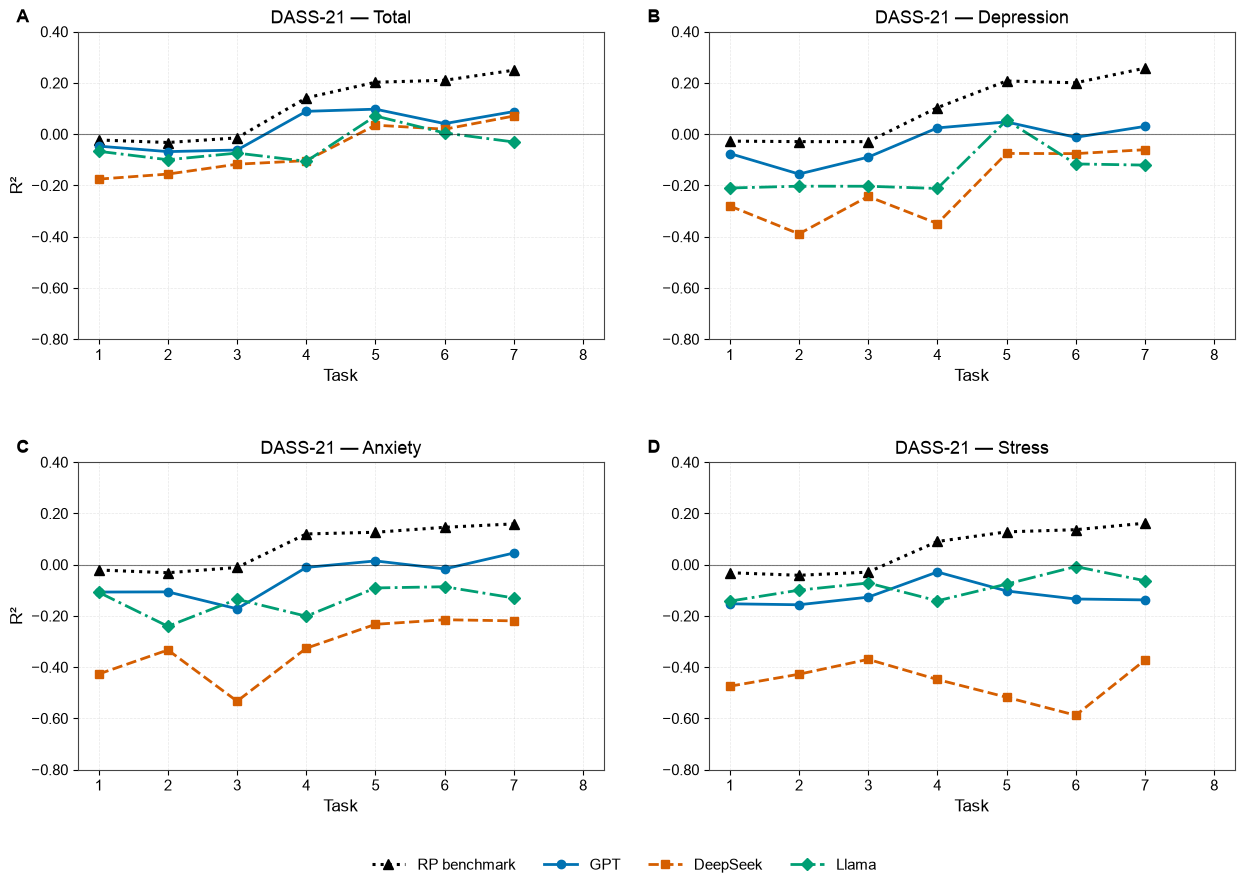

✓ Saved: results/figures/Supplementary_Figure_3.png / results/figures/Supplementary_Figure_3.pdf


In [26]:
# ============================================================================
# SUPPLEMENTARY FIGURE 3 — R² across tasks, DASS-21 total and subscales
# ============================================================================
def _compute_shared_ylims(df, r2_cols, step_min=1, step_max=8, pad=0.15, rp_series_dict=None):
    """
    Compute shared y-limits across multiple R² columns, optionally including external RP predictor series.
    Ignores NaNs, applies symmetric padding, and always includes 0.
    """
    d = df.copy()
    d["Step_num"] = d["Step"].astype(str).str.extract(r"(\d+)").astype(float)
    d = d.dropna(subset=["Step_num"])
    d["Step_num"] = d["Step_num"].astype(int)
    d = d[(d["Step_num"] >= step_min) & (d["Step_num"] <= step_max)]

    vals = []
    for col in r2_cols:
        if col in d.columns:
            vals.append(pd.to_numeric(d[col], errors="coerce").to_numpy())

    if rp_series_dict:
        for _, series in rp_series_dict.items():
            arr = np.asarray(series, dtype=float)
            vals.append(arr)

    if not vals:
        return None

    y = np.concatenate(vals)
    y = y[np.isfinite(y)]
    if y.size == 0:
        return None

    ymin, ymax = float(np.min(y)), float(np.max(y))
    ymin = min(ymin, 0.0)
    ymax = max(ymax, 0.0)

    span = ymax - ymin
    if span == 0:
        span = 1.0
    ymin -= pad * span
    ymax += pad * span

    ymin = np.floor(ymin * 10) / 10
    ymax = np.ceil(ymax * 10) / 10
    return (ymin, ymax)

# Map each subscale label to its master_table R² column and outcome column
DASS_SUBS = {
    "Total":      ("R² (DASS-21 outcome)",    "dass_total_interp"),
    "Depression": ("R² (DASS-21 Depression)", "dass_dep_interp"),
    "Anxiety":    ("R² (DASS-21 Anxiety)",    "dass_ans_interp"),
    "Stress":     ("R² (DASS-21 Stress)",     "dass_st_interp"),
}

# ── Shared y-limits across all 4 panels ──────────────────────────────────────
sf2_ylims = _compute_shared_ylims(
    master_table,
    r2_cols=[r2_col for _, (r2_col, _) in DASS_SUBS.items()],
    step_min=1,
    step_max=8,
    pad=0.15,
    rp_series_dict=rp_r2_dass_subs,
)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
fig.patch.set_facecolor("white")

panel_labels = ["A", "B", "C", "D"]

# ── Panel label offset  ──────────────────────────────
offset = mtransforms.ScaledTranslation(-35/72, 4/72, fig.dpi_scale_trans)

for (ax, (label, (r2_col, _)), panel_lbl) in zip(
    axes.flatten(), DASS_SUBS.items(), panel_labels
):
    ax.set_facecolor("white")

    # Draw panel with shared helper
    _panel(
        ax, master_table, r2_col,
        rp_r2_dass_subs[label],
        step_min=1, step_max=8,
        ylabel=(ax in axes[:, 0]),
    )

    # Apply common y-limits across panels
    ax.set_ylim(*sf2_ylims)

    # Apply unified text sizes
    ax.set_title(f"DASS-21 — {label}", fontsize=FS_TITLE, pad=6)
    ax.xaxis.label.set_size(FS_LABEL)
    ax.yaxis.label.set_size(FS_LABEL)
    ax.tick_params(axis="both", which="major", labelsize=FS_TICK)

    # Add panel letter
    ax.text(
        0.0, 1.0, panel_lbl,
        transform=ax.transAxes + offset,
        fontsize=FS_PANEL,
        fontweight="bold",
        ha="right",
        va="bottom"
    )

    # Keep visible border around each panel
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#444444")

# ── Show y-axis tick labels also on right-column panels ──────────────────────
for ax in axes[:, 1]:
    ax.tick_params(axis="y", labelleft=True)

# ── Shared horizontal legend below all panels ────────────────────────────────
handles, labels = axes.flatten()[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="lower center",
    ncol=len(labels),
    frameon=False,
    fontsize=FS_LEGEND,
    bbox_to_anchor=(0.5, -0.01),
    handlelength=2.2,
    columnspacing=1.8,
)

fig.subplots_adjust(
    left=0.08, right=0.97,
    top=0.94, bottom=0.12,
    hspace=0.40,
    wspace=0.20,
)

save_figure(fig, "Supplementary_Figure_3")
plt.show()
print(f"✓ Saved: {FIG_DIR / 'Supplementary_Figure_3.png'} / {FIG_DIR / 'Supplementary_Figure_3.pdf'}")


### Supplementary Figure 4 — R² for MI-RSWB-18 total and subscales

✓ Saved: results/figures/Supplementary_Figure_4.png / .pdf


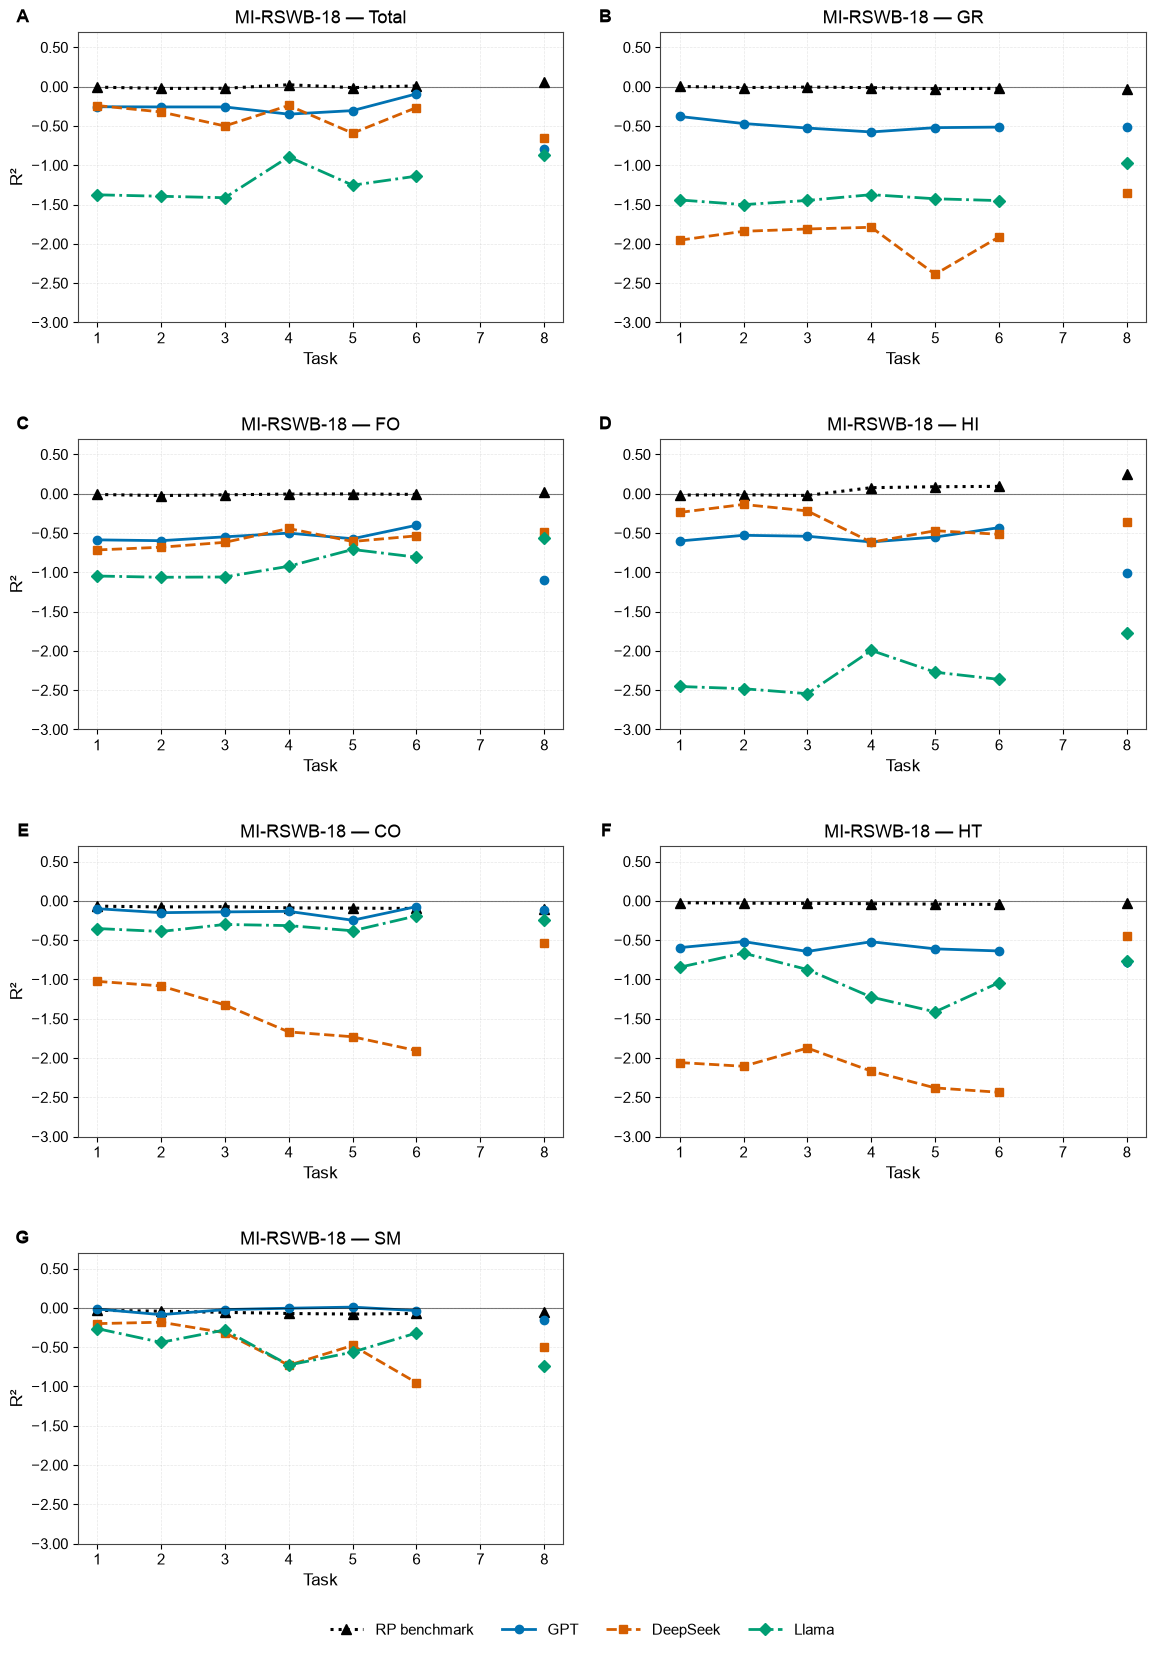

✓ Saved: results/figures/Supplementary_Figure_4.png / results/figures/Supplementary_Figure_4.pdf


In [27]:
# ============================================================================
# SUPPLEMENTARY FIGURE 4 — R² across tasks, MI-RSWB-18 total and subscales
# ============================================================================
MIRSWB_SUBS = {
    "Total":       ("R² (MI-RSWB-18 outcome)", "mirswb_total"),
    "GR":          ("R² (MI-RSWB GR)",          "mirswb_gr"),
    "FO":          ("R² (MI-RSWB FO)",          "mirswb_fo"),
    "HI":          ("R² (MI-RSWB HI)",          "mirswb_hi"),
    "CO":          ("R² (MI-RSWB CO)",          "mirswb_co"),
    "HT":          ("R² (MI-RSWB HT)",          "mirswb_ht"),
    "SM":          ("R² (MI-RSWB SM)",          "mirswb_sm"),
}

# ── Shared y-limits across all 7 panels ──────────────────────────────────────
sf3_ylims = _compute_shared_ylims(
    master_table,
    r2_cols=[r2_col for _, (r2_col, _) in MIRSWB_SUBS.items()],
    step_min=1,
    step_max=8,
    pad=0.15,
    rp_series_dict=rp_r2_mirswb_subs,
)

# ── Figure layout: 4×2 grid (7 panels; last cell hidden) ─────────────────────
fig, axes = plt.subplots(4, 2, figsize=(12, 18), sharey=True)
fig.patch.set_facecolor("white")
axes_flat = axes.flatten()

panel_labels = ["A", "B", "C", "D", "E", "F", "G"]

# ── Panel label offset (same style as previous figures) ──────────────────────
offset = mtransforms.ScaledTranslation(-35/72, 4/72, fig.dpi_scale_trans)

for ax, (label, (r2_col, _)), panel_lbl in zip(
    axes_flat, MIRSWB_SUBS.items(), panel_labels
):
    ax.set_facecolor("white")

    # Draw panel with shared helper
    _panel(
        ax, master_table, r2_col,
        rp_r2_mirswb_subs[label],
        step_min=1, step_max=8,
        ylabel=(ax in axes[:, 0]),
    )

    # Apply common y-limits across panels
    ax.set_ylim(*sf3_ylims)

    # Apply unified text sizes
    ax.set_title(f"MI-RSWB-18 — {label}", fontsize=FS_TITLE, pad=6)
    ax.xaxis.label.set_size(FS_LABEL)
    ax.yaxis.label.set_size(FS_LABEL)
    ax.tick_params(axis="both", which="major", labelsize=FS_TICK)

    # Add panel letter
    ax.text(
        0.0, 1.0, panel_lbl,
        transform=ax.transAxes + offset,
        fontsize=FS_PANEL,
        fontweight="bold",
        ha="right",
        va="bottom"
    )

    # Keep visible border around each panel
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#444444")

# ── Hide the unused 8th cell in the 4×2 grid ─────────────────────────────────
axes_flat[-1].set_visible(False)

# ── Show y-axis tick labels on right-column panels if needed ─────────────────
for ax in axes[:, 1]:
    if ax.get_visible():
        ax.tick_params(axis="y", labelleft=True)

# ── Shared horizontal legend below all panels ────────────────────────────────
handles, labels = axes_flat[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="lower center",
    ncol=len(labels),
    frameon=False,
    fontsize=FS_LEGEND,
    bbox_to_anchor=(0.5, 0.04),
    handlelength=2.2,
    columnspacing=1.8,
)

fig.subplots_adjust(
    left=0.08, right=0.97,
    top=0.94, bottom=0.10,
    hspace=0.40,
    wspace=0.20,
)

save_figure(fig, "Supplementary_Figure_4")
plt.show()
print(f"✓ Saved: {FIG_DIR / 'Supplementary_Figure_4.png'} / {FIG_DIR / 'Supplementary_Figure_4.pdf'}")


### Table 5 — Paired absolute-error comparisons

In [28]:
# ============================================================================
# TABLE 5 — Paired absolute errors, LLM vs RP benchmark (Tasks 6–8)
#   Wilcoxon signed-rank (Holm-adjusted across 12 tests); matched-pairs rank-biserial r
# ============================================================================
# ── Table 5: paired absolute-error comparisons (Tasks 6–8) ───────────────────
def rank_biserial_paired(d):
    """Matched-pairs rank-biserial correlation; positive = LLM errors larger."""
    d = d[d != 0]
    rk = rankdata(np.abs(d))
    return float((rk[d > 0].sum() - rk[d < 0].sum()) / rk.sum())


pair_rows = []
for t, fam in CALIB_CONFIGS:
    st = pred_store[(fam, t)]
    y = st["y_true"].to_numpy()
    ae_b = np.abs(st[BENCH].to_numpy() - y)
    for m in MODEL_ORDER:
        ae_l = np.abs(st[m].to_numpy(float) - y)
        d = ae_l - ae_b
        w, p = wilcoxon(d, zero_method="wilcox", alternative="two-sided")
        pair_rows.append({"Task": t, "Outcome": fam, "Model": m, "n": len(d),
                          "MedAE benchmark": np.median(ae_b), "MedAE LLM": np.median(ae_l),
                          "% LLM worse": 100 * np.mean(d > 0), "W": w, "p": p,
                          "r_rb": rank_biserial_paired(d)})

df_pairs = pd.DataFrame(pair_rows)
df_pairs["p_holm"] = multipletests(df_pairs["p"], method="holm")[1]
df_pairs.round(4).to_csv(OUT_DIR / "rq2_paired_errors.csv", index=False, encoding="utf-8-sig")

t5 = []
for (t, fam), g in df_pairs.groupby(["Task", "Outcome"], sort=False):
    g = g.set_index("Model")
    t5.append({"Task": t, "Outcome": fam,
               "RP benchmark MedAE": f1(g["MedAE benchmark"].iloc[0]),
               "LLM MedAE GPT / DS / Llama": trio(g, "MedAE LLM", f1),
               "% LLM worse GPT / DS / Llama": trio(g, "% LLM worse", lambda v: f"{v:.0f}"),
               "Holm-adjusted p GPT / DS / Llama": trio(g, "p_holm", fmt_p_table),
               "r_rb GPT / DS / Llama": trio(g, "r_rb", fmt_r2)})
table5 = pd.DataFrame(t5).set_index(["Task", "Outcome"])
export_table(table5, "TABLE 5 — Paired absolute-error comparisons (Tasks 6–8)", "table5_paired_errors.csv")



TABLE 5 — Paired absolute-error comparisons (Tasks 6–8)


,,RP benchmark MedAE,LLM MedAE GPT / DS / Llama,% LLM worse GPT / DS / Llama,Holm-adjusted p GPT / DS / Llama,r_rb GPT / DS / Llama
Task,Outcome,,,,,
6,DASS-21,18.4,22.0 / 20.0 / 21.0,59 / 57 / 63,0.01 / 0.07 / 0.001,0.24 / 0.17 / 0.29
7,DASS-21,17.1,22.0 / 18.0 / 22.0,55 / 55 / 58,0.048 / 0.14 / < 0.001,0.19 / 0.14 / 0.30
6,MI-RSWB-18,8.6,8.0 / 10.0 / 13.0,54 / 56 / 73,0.32 / 0.02 / < 0.001,0.08 / 0.22 / 0.55
8,MI-RSWB-18,7.6,11.0 / 10.0 / 11.0,67 / 63 / 65,< 0.001 / < 0.001 / < 0.001,0.46 / 0.33 / 0.43


Task	Outcome	RP benchmark MedAE	LLM MedAE GPT / DS / Llama	% LLM worse GPT / DS / Llama	Holm-adjusted p GPT / DS / Llama	r_rb GPT / DS / Llama
6	DASS-21	18.4	22.0 / 20.0 / 21.0	59 / 57 / 63	0.01 / 0.07 / 0.001	0.24 / 0.17 / 0.29
7	DASS-21	17.1	22.0 / 18.0 / 22.0	55 / 55 / 58	0.048 / 0.14 / < 0.001	0.19 / 0.14 / 0.30
6	MI-RSWB-18	8.6	8.0 / 10.0 / 13.0	54 / 56 / 73	0.32 / 0.02 / < 0.001	0.08 / 0.22 / 0.55
8	MI-RSWB-18	7.6	11.0 / 10.0 / 11.0	67 / 63 / 65	< 0.001 / < 0.001 / < 0.001	0.46 / 0.33 / 0.43



### Figure 3 — Calibration plots

In [29]:
# ============================================================================
# FIGURE 3 — Grouped calibration plots (A–D)
# ============================================================================
SHOW_RAW  = False          # Figure 3: also draw individual points (faint)
N_GROUPS  = 5              # Figure 3: quantile groups of predicted scores

PRED_ORDER = [BENCH] + MODEL_ORDER
STYLE = {
    BENCH:      dict(color="#000000", marker="^", ls=(0, (4, 1, 1, 1)), label="RP benchmark"),
    "GPT":      dict(color="#0072B2", marker="o", ls="-",  label="GPT"),
    "DeepSeek": dict(color="#D55E00", marker="s", ls="--", label="DeepSeek"),
    "Llama":    dict(color="#009E73", marker="D", ls="-.", label="Llama"),
}
OUT_LABEL = {"DASS-21": "DASS-21 total", "MI-RSWB-18": "MI-RSWB-18 total"}


def _style_ax(ax):
    """Shared styling of previous figures: white background, border, light grid."""
    ax.set_facecolor("white")
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.8)
        spine.set_color("#444444")
    ax.grid(True, linewidth=0.5, alpha=0.3, linestyle="--")
    ax.tick_params(axis="both", which="major", labelsize=FS_TICK)


def _panel_letter(fig, ax, letter):
    offset = mtransforms.ScaledTranslation(-35 / 72, 4 / 72, fig.dpi_scale_trans)
    ax.text(0.0, 1.0, letter, transform=ax.transAxes + offset,
            fontsize=FS_PANEL, fontweight="bold", ha="right", va="bottom")


def _fit(y, p):
    """OLS calibration fit (observed ~ predicted) with HC3 covariance."""
    return sm.OLS(y, sm.add_constant(p)).fit(cov_type="HC3")


def _limits_by_outcome(pad_frac=0.04):
    """Common square limits per instrument across its configurations."""
    lims = {}
    for fam in TOTALS:
        vals = []
        for t, f in CALIB_CONFIGS:
            if f == fam:
                st = pred_store[(fam, t)]
                vals.append(st[["y_true"] + PRED_ORDER].to_numpy(float).ravel())
        v = np.concatenate(vals)
        lo, hi = np.nanmin(v), np.nanmax(v)
        pad = pad_frac * (hi - lo)
        lims[fam] = (lo - pad, hi + pad)
    return lims


def _square_axes(ax, lo, hi):
    ax.plot([lo, hi], [lo, hi], color="#666666", ls=":", lw=1.2, zorder=1)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal", adjustable="box")


def _calib_text(y, p, digits=2):
    c = calibration(y, p)
    return (f"Slope {fmt_num(c['slope'], digits)} "
            f"({fmt_num(c['slope_lo'], digits)} to {fmt_num(c['slope_hi'], digits)})"), c


LIMS = _limits_by_outcome()

# ============================================================================
# FIGURE 3 — grouped calibration, all predictors per configuration
# ============================================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 12.5))
fig.patch.set_facecolor("white")

for ax, (t, fam), letter in zip(axes.ravel(), CALIB_CONFIGS, "ABCD"):
    _style_ax(ax)
    st = pred_store[(fam, t)]
    y = st["y_true"].to_numpy(float)
    lo, hi = LIMS[fam]
    _square_axes(ax, lo, hi)

    y_box = 0.97
    for pred in PRED_ORDER:
        p, sty = st[pred].to_numpy(float), STYLE[pred]

        if SHOW_RAW and pred != BENCH:
            ax.scatter(p, y, s=10, alpha=0.15, color=sty["color"],
                       marker=sty["marker"], linewidths=0, zorder=2)

        # Quantile groups of predicted scores: mean predicted vs mean observed
        grp = pd.qcut(pd.Series(p).rank(method="first"), N_GROUPS, labels=False)
        gm = pd.DataFrame({"p": p, "y": y, "g": grp}).groupby("g")[["p", "y"]].mean()
        ax.scatter(gm["p"], gm["y"], s=55, color=sty["color"], marker=sty["marker"],
                   edgecolor="white", linewidth=0.8, zorder=5)

        # Calibration line over the observed range of predictions (no extrapolation)
        c = calibration(y, p)
        xs = np.linspace(p.min(), p.max(), 100)
        ax.plot(xs, c["intercept"] + c["slope"] * xs, color=sty["color"],
                ls=sty["ls"], lw=2.0, zorder=4)

        txt, _ = _calib_text(y, p)
        ax.text(0.03, y_box, f"{sty['label']}: {txt}", transform=ax.transAxes,
                fontsize=FS_LEGEND - 1, color=sty["color"], va="top", ha="left",
                bbox=dict(boxstyle="round,pad=0.18", facecolor="white",
                          edgecolor=sty["color"], alpha=0.85, linewidth=0.8), zorder=6)
        y_box -= 0.075

    ax.set_title(f"Task {t} | {OUT_LABEL[fam]}", fontsize=FS_TITLE, pad=6)
    ax.set_xlabel("Predicted score", fontsize=FS_LABEL)
    ax.set_ylabel("Observed RP score", fontsize=FS_LABEL)
    _panel_letter(fig, ax, letter)

handles = [Line2D([0], [0], color=STYLE[k]["color"], ls=STYLE[k]["ls"], lw=2,
                  marker=STYLE[k]["marker"], markersize=7, label=STYLE[k]["label"])
           for k in PRED_ORDER]
handles.append(Line2D([0], [0], color="#666666", ls=":", lw=1.2, label="Identity"))
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False,
           fontsize=FS_LEGEND, bbox_to_anchor=(0.5, 0.01), handlelength=2.4, columnspacing=1.8)
fig.subplots_adjust(left=0.08, right=0.98, top=0.95, bottom=0.09, hspace=0.28, wspace=0.25)

save_figure(fig, "Figure_3")
plt.close(fig)
print(f"✓ Saved: {FIG_DIR / 'Figure_3.png'} / {FIG_DIR / 'Figure_3.pdf'}")


✓ Saved: results/figures/Figure_3.png / .pdf
✓ Saved: results/figures/Figure_3.png / results/figures/Figure_3.pdf


### Supplementary Table 12 — Calibration parameters

In [30]:
# ============================================================================
# SUPPLEMENTARY TABLE 12 — Calibration slopes, intercepts and mean error
# ============================================================================
# ── Supplementary Table S12: calibration (observed regressed on predicted) ───


cal_rows = []
for t, fam in CALIB_CONFIGS:
    st = pred_store[(fam, t)]
    for pred in [BENCH] + MODEL_ORDER:
        cal_rows.append({"Task": t, "Outcome": fam, "Predictor": pred,
                         **calibration(st["y_true"].to_numpy(), st[pred].to_numpy(float))})
df_cal = pd.DataFrame(cal_rows)

ci_fmt = lambda est, lo, hi, d: f"{fmt_num(est, d)} ({fmt_num(lo, d)} to {fmt_num(hi, d)})"
s11 = pd.DataFrame({
    "Task": df_cal["Task"], "Outcome": df_cal["Outcome"],
    "Predictor": df_cal["Predictor"].replace({"DeepSeek": "DS"}),
    "Slope (95% CI)": [ci_fmt(r.slope, r.slope_lo, r.slope_hi, 2) for r in df_cal.itertuples()],
    "Intercept (95% CI)": [ci_fmt(r.intercept, r.int_lo, r.int_hi, 1) for r in df_cal.itertuples()],
    "Mean error": df_cal["mean_error"].map(lambda v: fmt_num(v, 1)),
}).set_index(["Task", "Outcome", "Predictor"])
export_table(s11, "SUPPLEMENTARY TABLE S12 — Calibration parameters (Tasks 6–8)",
             "supp_table_S12_calibration.csv")



SUPPLEMENTARY TABLE S12 — Calibration parameters (Tasks 6–8)


Slope (95% CI)    Intercept (95% CI)  \
Task Outcome    Predictor                                                   
6    DASS-21    RP benchmark    0.82 (0.63 to 1.02)    9.6 (−0.8 to 20.0)   
                GPT             0.86 (0.32 to 1.40)   6.1 (−24.0 to 36.2)   
                DS              0.57 (0.41 to 0.74)    19.5 (9.1 to 29.9)   
                Llama           0.52 (0.15 to 0.89)    25.9 (5.8 to 46.0)   
7    DASS-21    RP benchmark    0.85 (0.67 to 1.02)    8.5 (−1.2 to 18.2)   
                GPT             1.06 (0.60 to 1.52)  −5.3 (−30.9 to 20.3)   
                DS              0.62 (0.44 to 0.79)    17.5 (6.9 to 28.1)   
                Llama           0.37 (0.03 to 0.71)   34.5 (15.8 to 53.1)   
6    MI-RSWB-18 RP benchmark    0.56 (0.21 to 0.91)    27.0 (5.2 to 48.7)   
                GPT             0.40 (0.18 to 0.63)   35.8 (21.4 to 50.2)   
                DS              0.28 (0.11 to 0.46)   43.8 (33.2 to 54.5)   
                Llama         −0.02 (−0.30 to 0.26)   63.1 (42.4 to 83.7)   
8    MI-RSWB-18 RP benchmark    0.67 (0.39 to 0.95)    20.1 (2.6 to 37.6)   
                GPT             0.34 (0.07 to 0.62)   36.8 (16.9 to 56.7)   
                DS             0.11 (−0.05 to 0.27)   54.5 (44.1 to 65.0)   
                Llama          0.02 (−0.17 to 0.21)   59.9 (46.5 to 73.2)   

                             Mean error  
Task Outcome    Predictor                
6    DASS-21    RP benchmark       −0.1  
                GPT                 1.6  
                DS                  6.5  
                Llama               0.6  
7    DASS-21    RP benchmark       −0.1  
                GPT                 2.1  
                DS                  5.7  
                Llama               0.0  
6    MI-RSWB-18 RP benchmark        0.0  
                GPT                 2.1  
                DS                  0.1  
                Llama              11.6  
8    MI-RSWB-18 RP benchmark        0.0  
                GPT                10.3  
                DS                  2.3  
                Llama               8.2

Task	Outcome	Predictor	Slope (95% CI)	Intercept (95% CI)	Mean error
6	DASS-21	RP benchmark	0.82 (0.63 to 1.02)	9.6 (−0.8 to 20.0)	−0.1
6	DASS-21	GPT	0.86 (0.32 to 1.40)	6.1 (−24.0 to 36.2)	1.6
6	DASS-21	DS	0.57 (0.41 to 0.74)	19.5 (9.1 to 29.9)	6.5
6	DASS-21	Llama	0.52 (0.15 to 0.89)	25.9 (5.8 to 46.0)	0.6
7	DASS-21	RP benchmark	0.85 (0.67 to 1.02)	8.5 (−1.2 to 18.2)	−0.1
7	DASS-21	GPT	1.06 (0.60 to 1.52)	−5.3 (−30.9 to 20.3)	2.1
7	DASS-21	DS	0.62 (0.44 to 0.79)	17.5 (6.9 to 28.1)	5.7
7	DASS-21	Llama	0.37 (0.03 to 0.71)	34.5 (15.8 to 53.1)	0.0
6	MI-RSWB-18	RP benchmark	0.56 (0.21 to 0.91)	27.0 (5.2 to 48.7)	0.0
6	MI-RSWB-18	GPT	0.40 (0.18 to 0.63)	35.8 (21.4 to 50.2)	2.1
6	MI-RSWB-18	DS	0.28 (0.11 to 0.46)	43.8 (33.2 to 54.5)	0.1
6	MI-RSWB-18	Llama	−0.02 (−0.30 to 0.26)	63.1 (42.4 to 83.7)	11.6
8	MI-RSWB-18	RP benchmark	0.67 (0.39 to 0.95)	20.1 (2.6 to 37.6)	0.0
8	MI-RSWB-18	GPT	0.34 (0.07 to 0.62)	36.8 (16.9 to 56.7)	10.3
8	MI-RSWB-18	DS	0.11 (−0.05 to 0.27)	54.5 (44.1 to 65.0)	2.3
8	

### Supplementary Figure 5 — Model-specific calibration plots

In [31]:
# ============================================================================
# SUPPLEMENTARY FIGURE 5 — one panel per configuration × LLM, 95% CI band
# ============================================================================
fig, axes = plt.subplots(len(CALIB_CONFIGS), len(MODEL_ORDER), figsize=(14, 19))
fig.patch.set_facecolor("white")
letters = iter("ABCDEFGHIJKL")

for i, (t, fam) in enumerate(CALIB_CONFIGS):
    st = pred_store[(fam, t)]
    y = st["y_true"].to_numpy(float)
    lo, hi = LIMS[fam]

    for j, m in enumerate(MODEL_ORDER):
        ax = axes[i, j]
        _style_ax(ax)
        _square_axes(ax, lo, hi)
        p, sty = st[m].to_numpy(float), STYLE[m]

        ax.scatter(p, y, s=18, alpha=0.45, color=sty["color"], marker=sty["marker"],
                   linewidths=0, zorder=2)

        fit = _fit(y, p)
        xs = np.linspace(p.min(), p.max(), 150)
        band = fit.get_prediction(sm.add_constant(xs)).summary_frame(alpha=0.05)
        ax.fill_between(xs, band["mean_ci_lower"], band["mean_ci_upper"],
                        color=sty["color"], alpha=0.18, linewidth=0, zorder=3)
        ax.plot(xs, band["mean"], color=sty["color"], ls=sty["ls"], lw=2.0, zorder=4)

        txt, c = _calib_text(y, p)
        ax.text(0.04, 0.96,
                f"{txt}\nIntercept {fmt_num(c['intercept'], 1)}"
                f"\nMean error {fmt_num(c['mean_error'], 1)}",
                transform=ax.transAxes, fontsize=FS_LEGEND - 1, va="top", ha="left",
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white",
                          edgecolor=sty["color"], alpha=0.85, linewidth=0.8), zorder=6)

        ax.set_title(f"Task {t} | {OUT_LABEL[fam]} | {m}", fontsize=FS_TITLE - 1, pad=5)
        ax.set_xlabel("Predicted score", fontsize=FS_LABEL)
        ax.set_ylabel("Observed RP score" if j == 0 else "", fontsize=FS_LABEL)
        _panel_letter(fig, ax, next(letters))

handles = [Line2D([0], [0], color=STYLE[m]["color"], ls=STYLE[m]["ls"], lw=2,
                  marker=STYLE[m]["marker"], markersize=6, label=m) for m in MODEL_ORDER]
handles += [Patch(facecolor="#999999", alpha=0.35, label="95% CI of calibration line"),
            Line2D([0], [0], color="#666666", ls=":", lw=1.2, label="Identity")]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False,
           fontsize=FS_LEGEND, bbox_to_anchor=(0.5, 0.005), handlelength=2.4, columnspacing=1.6)
fig.subplots_adjust(left=0.07, right=0.98, top=0.97, bottom=0.05, hspace=0.38, wspace=0.25)

save_figure(fig, "Supplementary_Figure_5")
plt.close(fig)
print(f"✓ Saved: {FIG_DIR / 'Supplementary_Figure_5.png'} / {FIG_DIR / 'Supplementary_Figure_5.pdf'}")

✓ Saved: results/figures/Supplementary_Figure_5.png / .pdf
✓ Saved: results/figures/Supplementary_Figure_5.png / results/figures/Supplementary_Figure_5.pdf
